    # Trabajo final · Data Engineer · UniAndina

    **Universidad** · Empresa ficticia. Los datos son sintéticos y ningún resultado representa una situación real de ARCA. No hay credenciales ni infraestructura real.

    **Lo propio de la empresa** (la base operacional y los eventos de sus sistemas) **se genera por código en este notebook**. **Lo externo** (los datos que mandan terceros) **llega como archivos CSV y XLSX** en la carpeta `datos_externos/`, junto a este notebook.

    ## El caso

    UniAndina tiene 2.000 alumnos, 40 materias y tres sistemas: la base académica, las notas que cargan los docentes y la biblioteca. Quiere un catálogo de datos con su linaje, controles de calidad, accesos por rol y detectar a tiempo a quienes están en riesgo de abandonar.

    ## Qué tiene que resolver la plataforma

    - Un catálogo con el linaje de al menos un indicador.
- Reglas de calidad medibles.
- Una detección temprana del riesgo de abandono.

    ## Restricciones del caso

    - Hay personas con dos legajos y cambios de plan de estudio.
- Los esquemas de notas cambian entre cuatrimestres.
- Datos personales de estudiantes.
- Los archivos externos llegan en CSV y XLSX, y cambian de formato sin aviso.

    Todo lo que el caso **no declara** es una suposición: escribila y justificala.

    Las instrucciones completas (qué se entrega, rúbrica y defensa) están en el PDF **«Trabajo final · Data Engineer · Instrucciones»**. Este notebook es tu lugar de trabajo: vas del **SQL al análisis** sin salir de acá. Elegí la herramienta **después** de fijar el requisito.

## Paso 0 · Instalación

Corré esta celda primero. Si falta alguna librería (incluida `openpyxl`, para leer XLSX), la instala en el mismo Python que ejecuta este notebook.

In [1]:
# Instalación autocontenida: instala, en el mismo Python que ejecuta este notebook, lo que falte.
import importlib, importlib.util, subprocess, sys

REQUISITOS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "openpyxl": "openpyxl",
              "yaml": "pyyaml", "sklearn": "scikit-learn"}   # pyyaml: contrato (módulo 6) · scikit-learn: modelo (módulo 7)
print(f"Kernel en uso: {sys.executable} (Python {sys.version.split()[0]})")
faltan = [pip for modulo, pip in REQUISITOS.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan), "(puede tardar un minuto)")
    base = [sys.executable, "-m", "pip", "install", "-q"]
    try:
        try:
            subprocess.check_call(base + faltan)
        except subprocess.CalledProcessError:       # el Python del sistema suele rechazar instalaciones
            print("Reintentando con --break-system-packages ...")
            subprocess.check_call(base + ["--break-system-packages"] + faltan)
    except Exception:
        raise SystemExit("No se pudo instalar en este kernel. Elegí el kernel .venv (arriba a la derecha) y volvé a correr esta celda.")
    importlib.invalidate_caches()
    print("Listo.")
else:
    print("Todo instalado: podés seguir.")

Kernel en uso: /usr/local/bin/python3 (Python 3.13.18)
Todo instalado: podés seguir.


## 1 · Las fuentes

La primera celda **genera lo propio** con código comprimido a propósito: no hace falta leerla, y leerla te quita la mitad del trabajo. La segunda lo escribe en la carpeta `fuentes/` (una base SQLite y los eventos en JSON), lista los archivos externos y comprueba que tu base coincide con la que se usó para armarlos.

Te deja estas herramientas: `sql(...)`, `ls()`, `externos()`, `hojas(...)`, `leer_externo(...)`, `leer_eventos(...)`, `dwh()`, `medir(...)`, `regla(...)`, `correr_dag(...)`, `zonas()` y `enmascarar(...)`.

In [2]:
import zlib, base64
_BLOB = (
    "eNqNV+tu2zYU/p+nIAQEkFJHkORLHWcuVrQYNqDNBiwDNgiGQUt0ylYiBUrqWhh+pP0Y+gh5sX2HlHxJnSyGYcskz+G5fOc7"
    "x7KstGmYasvqK+M1U9WAVVzleMS7ys9ysWbLXEnfDJgKZsyIpjWKpXVjfKka/0sQsLU27AuTipkQS+JOmNpPIvcasNG0f1LB"
    "4qxT2FZ+vh4wKMWFtRD5XnWVh5lWGW/8lI7k67DmZVUIe10hFAQDdsGqAOKwVJfLuuGNmFstiwGTd0obsZQqF1/mt6YVgbs0"
    "F5NlqyREpOI+nZ5PJsHsjOFl2Byuh05fiNO8LZqlUXf2XHDNbnCAXLpmGTdGGARnzlLvF3UnlBTm/h/uDZj3Oi+lkggNz+T9"
    "N0VLv9Uy04W+6068FUZkH7R9lLW4/1d7i2vGC2iD3295w38yvBT+xpP5khdtqbQ3Y+nae/1uI2fRON96NtzShpvjev+GnPYK"
    "ccc/dmffbWz02QsmHzuOjOJsn9gbxNJTulwZ0d1mb2ZPX7mGJ3yp4GsphWroch9O3MpSICNl5Xvx1VV0GcV4ewGswWajlw32"
    "c1E03D+AC9AxnIyR1njszEGmmrn31guCEPFck5Dvnf91eV5enuce2dslAreaECGVmfD73EAFgDVPw2Q6YGEywkc83X0kCxKv"
    "Cq6WMLTNpT7UkXpJFE8pQUmUDL3FTtcYloWjsRUWJZeFC5VL0kZuf9yBK2yg91TQtoFFG9CPfPOiB/YkOgVlVEH11Qf2cDw9"
    "gMOCkGcBcUMZPp2hSRQsOskOGZ3Yu83wcWw4qR6NfRXyYkCaTpbWNSt5cxK8WBdGchek97cEpeEJQ0eRxdIh+N47SYu+5HGR"
    "J/OPM1sYZ6RwlZ0VsgLeYH7JCx8YICBEDmphFONjguN8RVlQHDKmIwOkjf1AemzmspZoUDeu/GFFinh9wnNkt7/LuGOXfitr"
    "ac8nYI0uk6zD2PgyzryDk/SS650tqVwwPJHwfL4XsGs7I8nGcDJjSFkjVSuOlNHVpaPnLk4jeE5selCAwwGbBESpAoWRiflP"
    "vKjFA6vo9Ym9mLP42gYBfq8LDYj0ASYK1a3K95F+GSbskg1DKm0EEc4MWBzamxD0OAoQdRQLNHm8MnrFc+6R91b9qzkbMQE7"
    "wFei3u3vJVyI7r9ZEf9hxI6jMxoHTheErymRIa8qAVv9tffmj82nWTQB1gZUlrtas+YCyOEez2mJpawdkBoy3oJhp+q5wiQ1"
    "YGvv7a9vNgdJQEhQgg71QdAj7mF5WRCiqeCSem6ZASs1RQaA2vOE+9GXIRVMyxtjyRmVRiQGsslBDPBC4w4KSUdIyfhJQtIn"
    "6eiK6nV0ol6TMbGKPrK0k3rz52MtxgntvO+5yPquH6Ei9R0T2ew8CNZzw0Oy9J3rDN1NIE42IaWlxx22aCBRQAJBLIrGZERY"
    "6CwtiTWdjoU937eXmHAP+rnEd7RwdVhSL2gBVIuomCirSaHo0KS++i1zLMLc6Mrv/Tq2nXQkT+qwDPK0jtAIZcHWbR8PJPTD"
    "9U5Ooek9nRErF3ItMwwFWnlba0p6vEjh8FUSHi5S44+CjjyiDvm8tF0S/Sc8bNa9E+jNPV6H0ckOmh7hdLHDLzSnrv+T9UZq"
    "Y41yjf9wG0z6Wfd7uLDbc4MPHlfS7T4Ye2yEo+Hzxp44odkniv5/5qHOnHZVu1xjzijs5SDdvz9grLTsu0x7FhzsMQpOIXhi"
    "8BnsSNMWAM8aCQddvFdyZZvaczrZcr/l+kilZV1r5U+RST8G5ScHlB+47hAS8gFxjPrczT+HXHlNBvREeow2TvR+wOavqHc7"
    "MocSN99YtvVkvVIQWHtXL6ebBx0uji4urqjnXFxQ3yGu95r6+6HV1lg0fSx7D7RS8oYRXJ1ORkjiLov16Szenv88O38/O//d"
    "jrCNrGw1VcZerr1uQOz+CW28fIXtTTdjkq2WVTrSot94tNRlWZUWLEF6Dpv1klBMi7zcUrpN9gH5rq1OS43LjlDCrP6MVRV3"
    "lWw3iCX6jYTkxWca8504klVI3YiMhx+ReBqGsbTdnp3hHxFmMOLto39cZ/8Bi3tvuQ=="
)
exec(zlib.decompress(base64.b64decode(_BLOB)).decode("utf-8"))   # define generar(): código comprimido a propósito

In [3]:
import os, json, sqlite3, time, shutil
pd.options.display.width = 200; pd.options.display.max_columns = 40; pd.options.display.float_format = "{:,.3f}".format
t = generar(); DESTINO = "fuentes"; shutil.rmtree(DESTINO, ignore_errors=True); os.makedirs(DESTINO)   # lo propio de la empresa: base operacional y eventos
_con = sqlite3.connect(f"{DESTINO}/operacional.db")
for nombre, df in t["db"].items(): df.astype({c: "object" for c in df.columns if str(df[c].dtype).startswith("str")}).to_sql(nombre, _con, index=False)
_con.close()
if t["eventos"]: os.makedirs(f"{DESTINO}/eventos")
for nombre, ev in t["eventos"].items():
    with open(f"{DESTINO}/eventos/{nombre}", "w", encoding="utf-8") as f:
        for x in ev: f.write(json.dumps(x, ensure_ascii=False) + "\n")
EXTERNOS = next((c for c in ("datos_externos", "../datos_externos") if os.path.isdir(c)), None)
if EXTERNOS is None: print("⚠ No encuentro la carpeta datos_externos. Abrí este notebook desde la carpeta de tu equipo, junto a datos_externos/.")

def sql(consulta, base=f"{DESTINO}/operacional.db", parametros=None):
    """Corre una consulta SQL sobre la base operacional (o sobre otra base) y devuelve un DataFrame."""
    c = sqlite3.connect(base)
    try: return pd.read_sql_query(consulta, c, params=parametros)
    finally: c.close()
def ls(carpeta=DESTINO):
    """Lista lo propio que se generó (base y eventos) con su tamaño."""
    for raiz, _, nombres in sorted(os.walk(carpeta)):
        for n in sorted(nombres): print(f"{os.path.join(raiz, n):<62} {os.path.getsize(os.path.join(raiz, n)) / 1024:>9,.0f} KB")
def externos():
    """Lista los archivos externos (CSV y XLSX) con su tamaño y, en los XLSX, sus hojas."""
    for n in sorted(os.listdir(EXTERNOS)):
        ruta = os.path.join(EXTERNOS, n); extra = ("  hojas: " + ", ".join(pd.ExcelFile(ruta).sheet_names)) if n.endswith(".xlsx") else ""
        print(f"{n:<40} {os.path.getsize(ruta) / 1024:>8,.0f} KB{extra}")
def hojas(nombre):
    """Nombres de las hojas de un archivo XLSX externo."""
    return pd.ExcelFile(os.path.join(EXTERNOS, nombre)).sheet_names
def leer_externo(nombre, hoja=0, **opciones):
    """Lee un archivo externo (CSV o XLSX) como DataFrame. No arregla nada: ver cómo viene es parte del trabajo."""
    ruta = os.path.join(EXTERNOS, nombre)
    return pd.read_excel(ruta, sheet_name=hoja, **opciones) if nombre.endswith(".xlsx") else pd.read_csv(ruta, **opciones)
def leer_eventos(nombre):
    """Lee un archivo de eventos JSON (uno por línea) como DataFrame."""
    return pd.read_json(f"{DESTINO}/eventos/{nombre}", lines=True)
def dwh(archivo="dwh.db"):
    """Conexión al almacén que vas a modelar (un archivo SQLite nuevo)."""
    return sqlite3.connect(archivo)
def medir(funcion, *args, **kwargs):
    """Mide cuánto tarda una función y devuelve (resultado, segundos)."""
    t0 = time.perf_counter(); r = funcion(*args, **kwargs); return r, time.perf_counter() - t0
resultados_calidad = []
def regla(nombre, valor, umbral, mayor_es_mejor=False, descripcion=""):
    """Registra una regla de calidad medible: compara un valor con un umbral y deja el resultado."""
    ok = valor >= umbral if mayor_es_mejor else valor <= umbral
    resultados_calidad.append({"regla": nombre, "valor": valor, "umbral": umbral, "cumple": ok, "descripción": descripcion}); print(("✔" if ok else "✘"), nombre, "→", valor, f"(umbral {umbral})"); return ok
def correr_dag(tareas, dependencias, reintentos=2):
    """Ejecuta tareas (nombre → función) respetando dependencias, con reintentos. Si una falla, sus dependientes no corren."""
    estado = {}; pendientes = list(tareas)
    while pendientes:
        listas = [n for n in pendientes if all(estado.get(d) == "ok" for d in dependencias.get(n, []))]; bloq = [n for n in pendientes if any(estado.get(d) in ("falló", "omitida") for d in dependencias.get(n, []))]
        for n in bloq: estado[n] = "omitida"; pendientes.remove(n); print(f"  ⏭  {n}: omitida (falló una dependencia)")
        if not listas and not bloq: raise RuntimeError(f"Dependencias circulares o faltantes: {pendientes}")
        for n in listas:
            pendientes.remove(n)
            for intento in range(1, reintentos + 2):
                try: tareas[n](); estado[n] = "ok"; print(f"  ✔ {n}" + (f" (intento {intento})" if intento > 1 else "")); break
                except Exception as ex: print(f"  ✘ {n}, intento {intento}: {type(ex).__name__}: {ex}"); estado[n] = "falló"
    return estado
def zonas(base="lake"):
    """Crea las carpetas de las zonas de datos."""
    for z in ("cruda", "curada", "variables", "consumo"): os.makedirs(f"{base}/{z}", exist_ok=True)
    return sorted(os.listdir(base))
def enmascarar(valor, visibles=2):
    """Enmascara un texto dejando visibles los últimos caracteres."""
    s = str(valor); return "*" * max(len(s) - visibles, 0) + s[-visibles:]

HUELLA = {'alumnos': [2060, 0.0], 'materias': [40, 0.0], 'cursadas': [15315, 0.0], 'cambios_plan': [300, 0.0], 'biblioteca.jsonl': 10946}
def comprobar_base():
    """Comprueba que la base que generaste coincide con la que usaron para armar los archivos externos."""
    bien = True
    for nombre, df in t["db"].items():
        filas, suma = len(df), round(float(df.select_dtypes("number").sum().sum()), 2); e_filas, e_suma = HUELLA[nombre]
        if filas != e_filas or abs(suma - e_suma) > max(0.01, abs(e_suma) * 1e-6): bien = False; print(f"⚠ {nombre}: no coincide ({filas} filas)")
    for nombre, ev in t["eventos"].items():
        if len(ev) != HUELLA[nombre]: bien = False; print(f"⚠ {nombre}: no coincide ({len(ev)} eventos)")
    print("✔ Tu base coincide con los archivos externos." if bien else "⚠ Tu base no coincide con los archivos externos: reiniciá el kernel y volvé a correr todo. Si sigue, avisá al facilitador.")
    return bien
print("Lo propio, generado en la carpeta", DESTINO + "/")
ls(); print("\nLo externo, en la carpeta", EXTERNOS + "/")
externos(); print(); comprobar_base()

Lo propio, generado en la carpeta fuentes/
fuentes/operacional.db                                               940 KB
fuentes/eventos/biblioteca.jsonl                                   1,057 KB

Lo externo, en la carpeta datos_externos/
actas_docentes.xlsx                            44 KB  hojas: Ciencias, Humanidades, Gestión
becas.csv                                      10 KB
encuesta_satisfaccion.xlsx                     20 KB  hojas: Respuestas
notas_2024-2c.csv                             187 KB
notas_2025-1c.csv                             179 KB

✔ Tu base coincide con los archivos externos.


True

Los archivos externos **cambian de formato sin aviso**, y los datos propios traen duplicados, datos tardíos y datos personales. Descubrirlo, decidir qué hacer con cada caso y dejarlo escrito es parte de la evidencia. `leer_externo(...)` lee el archivo tal como viene: no arregla nada.

In [4]:
# Explorá lo propio y lo externo
sql("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,alumnos
1,materias
2,cursadas
3,cambios_plan


## Descubrimiento de problemas

Antes de diseñar, medimos los problemas de cada fuente. La celda siguiente los cuenta con código: si cambian los datos, la tabla cambia. Abajo está qué hacemos con cada uno y lo que suponemos porque el caso no lo declara.

In [5]:
# Descubrimiento: cada problema se mide con código, para que la evidencia se pueda volver a correr.
import re

def patron(serie):
    """Reemplaza dígitos por 9 para ver los formatos distintos de una columna."""
    return serie.astype(str).str.replace(r"\d", "9", regex=True).value_counts().to_dict()

alumnos  = sql("SELECT * FROM alumnos")
materias = sql("SELECT * FROM materias")
cursadas = sql("SELECT * FROM cursadas")
cambios  = sql("SELECT * FROM cambios_plan")
biblio   = pd.read_json(f"{DESTINO}/eventos/biblioteca.jsonl", lines=True, dtype={"isbn": str, "id_alumno": str})
notas_24 = leer_externo("notas_2024-2c.csv", dtype=str)
notas_25 = leer_externo("notas_2025-1c.csv", dtype=str)
becas    = leer_externo("becas.csv", dtype=str)
actas    = pd.concat([leer_externo("actas_docentes.xlsx", hoja=h, header=3, dtype=str).assign(hoja=h)
                      for h in hojas("actas_docentes.xlsx")], ignore_index=True)
encuesta = leer_externo("encuesta_satisfaccion.xlsx", header=2)

hallazgos = []
def hallazgo(fuente, problema, medido, total):
    hallazgos.append({"fuente": fuente, "problema": problema, "casos": int(medido), "de": int(total),
                      "%": round(100 * medido / total, 1) if total else 0.0})

# --- Lo propio: base académica ---
pares = alumnos[alumnos.dni.duplicated(keep=False)]
hallazgo("alumnos", "Personas con dos legajos (mismo DNI, nombre y correo; legajo L3xxxx)", pares.dni.nunique(), alumnos.dni.nunique())
hallazgo("alumnos", "Pares duplicados con estado_final distinto entre sus dos legajos",
         (pares.groupby("dni").estado_final.nunique() > 1).sum(), pares.dni.nunique())
hallazgo("alumnos", "plan_estudio guarda solo el plan actual (los que cambiaron ya figuran con el nuevo)",
         cambios.merge(alumnos, on="id_alumno").eval("plan_estudio == plan_nuevo").sum(), len(cambios))
hallazgo("cursadas", "Cursadas de alumnos que no existen en la base (id AL9xxxx)", (~cursadas.id_alumno.isin(alumnos.id_alumno)).sum(), len(cursadas))
hallazgo("cursadas", "Legajos duplicados sin ninguna cursada", (~alumnos.id_alumno.isin(cursadas.id_alumno) & alumnos.legajo.str.startswith("L3")).sum(), len(pares) // 2)
x = cursadas.merge(alumnos[["id_alumno", "estado_final"]])
hallazgo("cursadas", "Estado 'abandonó': aparece SOLO en alumnos con estado_final = abandono (es el objetivo escrito de otra forma)",
         ((x.estado == "abandonó") & (x.estado_final == "abandono")).sum(), (x.estado == "abandonó").sum())

# --- Lo propio: eventos de biblioteca ---
hallazgo("biblioteca.jsonl", "Préstamos que identifican al alumno por legajo y no por id_alumno", biblio.id_alumno.str.startswith("L").sum(), len(biblio))
hallazgo("biblioteca.jsonl", "El archivo no viene ordenado por fecha (eventos con fecha anterior al previo)", (pd.to_datetime(biblio.ts).diff().dt.total_seconds() < 0).sum(), len(biblio))

# --- Lo externo: notas por cuatrimestre ---
hallazgo("notas_2025-1c.csv", "Cambio de esquema: id_alumno → id_estudiante y nota → calificacion",
         int(list(notas_25.columns) != list(notas_24.columns)), 1)
hallazgo("notas_2025-1c.csv", "Cambio de escala: notas de 0 a 100 en vez de 0 a 10", (pd.to_numeric(notas_25.calificacion) > 10).sum(), len(notas_25))
n24, n25 = pd.to_numeric(notas_24.nota), pd.to_numeric(notas_25.calificacion)
hallazgo("notas_2024-2c.csv", "Notas fuera de rango (menores a 0 o mayores a 10)", ((n24 < 0) | (n24 > 10)).sum(), len(notas_24))
hallazgo("notas_2025-1c.csv", "Notas fuera de rango (menores a 0 o mayores a 100)", ((n25 < 0) | (n25 > 100)).sum(), len(notas_25))
k = notas_24.astype({"nota": float}).merge(cursadas[cursadas.cuatrimestre == "2024-2c"], on=["id_alumno", "id_materia"])
hallazgo("notas_2024-2c.csv", "Cursadas 'aprobada' con nota válida menor a 4", k.query("estado == 'aprobada' and 0 <= nota < 4").shape[0], len(k))
hallazgo("notas_2024-2c.csv", "Cursadas 'abandonó' que igual tienen nota", (k.estado == "abandonó").sum(), len(k))

# --- Lo externo: actas de los docentes (XLSX) ---
hallazgo("actas_docentes.xlsx", "Encabezado en la fila 4 y cuatrimestre escrito en la celda A2 (no es una columna)", 3, 3)
hallazgo("actas_docentes.xlsx", "Legajo sin la 'L' inicial", (~actas.Legajo.str.upper().str.startswith("L")).sum(), len(actas))
hallazgo("actas_docentes.xlsx", "Legajo con 'l' minúscula", actas.Legajo.str.startswith("l").sum(), len(actas))
hallazgo("actas_docentes.xlsx", "Nota con coma decimal ('7,0')", actas.Nota.str.contains(",").sum(), len(actas))
hallazgo("actas_docentes.xlsx", "Nota 'AUS' (ausente) donde el CSV de notas sí trae un número", (actas.Nota == "AUS").sum(), len(actas))
na = pd.to_numeric(actas.Nota.str.replace(",", "."), errors="coerce")
hallazgo("actas_docentes.xlsx", "Notas fuera de rango", ((na < 0) | (na > 10)).sum(), len(actas))
hallazgo("actas_docentes.xlsx", "La materia viene por nombre, no por id_materia", len(actas), len(actas))
leg = actas.Legajo.str.upper().where(actas.Legajo.str.upper().str.startswith("L"), "L" + actas.Legajo)
ac = (actas.assign(legajo=leg, nota_acta=na).merge(alumnos[["legajo", "id_alumno"]], on="legajo")
           .merge(materias.rename(columns={"nombre": "Materia"})[["Materia", "id_materia"]], on="Materia")
           .merge(notas_25.astype({"calificacion": float}), left_on=["id_alumno", "id_materia"], right_on=["id_estudiante", "id_materia"]))
hallazgo("actas_docentes.xlsx", "Misma nota que notas_2025-1c.csv (acta × 10 = CSV): son dos fuentes del mismo dato", (ac.nota_acta * 10 == ac.calificacion).sum(), len(ac))

# --- Lo externo: becas ---
hallazgo("becas.csv", "DNI con puntos ('35.527.738')", becas.dni.str.contains(r"\.").sum(), len(becas))
dni_b = becas.dni.str.replace(".", "", regex=False)
hallazgo("becas.csv", "DNI que no existe en la base académica (aun sin puntos)", (~dni_b.isin(alumnos.dni)).sum(), len(becas))
hallazgo("becas.csv", "Becas de personas con dos legajos (el DNI matchea dos filas)", dni_b.isin(pares.dni).sum(), len(becas))

# --- Lo externo: encuesta (XLSX) ---
hallazgo("encuesta_satisfaccion.xlsx", "Puntaje fuera de la escala 1 a 5", (~encuesta.Puntaje.between(1, 5)).sum(), len(encuesta))
hallazgo("encuesta_satisfaccion.xlsx", "Materia mal escrita ('Matería 11')", (~encuesta.Materia.isin(materias.nombre)).sum(), len(encuesta))
hallazgo("encuesta_satisfaccion.xlsx", "Comentario vacío", encuesta.Comentario.isna().sum(), len(encuesta))

hallazgos = pd.DataFrame(hallazgos)
hallazgos


,fuente,problema,casos,de,%
0,alumnos,"Personas con dos legajos (mismo DNI, nombre y ...",60,2000,3.000
1,alumnos,Pares duplicados con estado_final distinto ent...,14,60,23.300
2,alumnos,plan_estudio guarda solo el plan actual (los q...,300,300,100.000
3,cursadas,Cursadas de alumnos que no existen en la base ...,25,15315,0.200
4,cursadas,Legajos duplicados sin ninguna cursada,60,60,100.000
5,cursadas,Estado 'abandonó': aparece SOLO en alumnos con...,547,547,100.000
6,biblioteca.jsonl,Préstamos que identifican al alumno por legajo...,1126,10946,10.300
7,biblioteca.jsonl,El archivo no viene ordenado por fecha (evento...,5481,10946,50.100
8,notas_2025-1c.csv,Cambio de esquema: id_alumno → id_estudiante y...,1,1,100.000
9,notas_2025-1c.csv,Cambio de escala: notas de 0 a 100 en vez de 0...,7316,7334,99.800


### Qué hacemos con cada problema

Cada hallazgo de la tabla de arriba tiene una decisión y un módulo donde se resuelve. Lo que no se puede corregir con una regla clara **no se adivina**: va a cuarentena, con un motivo.

| # | Problema | Qué hacemos | Módulo |
| --- | --- | --- | --- |
| 1 | 60 personas con dos legajos | La persona se identifica por DNI. Se arma una tabla de equivalencias legajo → persona y queda como vigente el legajo con actividad (L2xxxx). Si los dos legajos tienen un `estado_final` distinto (14 casos), vale el del legajo vigente. | 2 y 3 |
| 2 | `plan_estudio` pisa el plan anterior | La historia del plan se reconstruye con `cambios_plan`: una versión con el plan anterior hasta `fecha_cambio` y otra con el plan nuevo desde esa fecha (SCD tipo 2). | 3 |
| 3 | 25 cursadas de alumnos inexistentes | Cuarentena. No entran al hecho porque romperían la integridad referencial. | 4 y 6 |
| 4 | El estado «abandonó» de la cursada equivale al objetivo | No se usa tal cual como variable del modelo. Definimos una fecha de corte y el modelo solo ve lo anterior a ese corte. | 7 |
| 5 | Biblioteca identifica a veces por legajo | En la zona curada se traduce el legajo a `id_alumno` con la tabla de equivalencias. | 4 |
| 6 | Biblioteca desordenada | Se carga por fecha del evento y no por orden de llegada. Para que sea idempotente, la clave es (alumno, ISBN, fecha y hora). | 4 y 5 |
| 7 | Las columnas de notas cambian entre cuatrimestres | Un contrato por cuatrimestre dice cómo se llama cada columna. Si llega un archivo con columnas desconocidas, va a cuarentena entero y se avisa. | 4 y 6 |
| 8 | Escala 0–100 en 2025-1c | Se normaliza a 0–10. La escala de cada archivo queda declarada en el contrato. | 4 |
| 9 | Notas fuera de rango (CSV y actas) | Cuarentena fila por fila y una regla de calidad con umbral. | 6 |
| 10 | Cursada «aprobada» con nota menor a 4 | Se marca como inconsistencia. El estado lo define la base académica y la nota la define el acta. | 6 |
| 11 | Actas: encabezado en la fila 4, cuatrimestre en A2, legajos sin «L» o en minúscula, coma decimal, «AUS» y materia por nombre | Se leen con encabezado fijo y el cuatrimestre sale de la celda A2. El legajo se normaliza (mayúscula y «L»), la coma pasa a punto, «AUS» queda como nota nula con la marca `ausente` y la materia se traduce a `id_materia`. | 4 |
| 12 | Actas y CSV 2025-1c traen la misma nota | El acta es la fuente de verdad (es el documento del docente). El CSV se usa para controlar el acta: si las dos no coinciden, se genera una alerta. | 4 y 6 |
| 13 | Becas: DNI con puntos, 20 sin alumno y 17 de personas duplicadas | Se quitan los puntos y se resuelve a persona. Las becas sin alumno van a cuarentena. | 4 |
| 14 | Encuesta: puntajes fuera de 1–5, «Matería» y comentarios vacíos | Se corrige el nombre de la materia (sin tilde) y los puntajes fuera de escala van a cuarentena. Es anónima: se usa solo agregada por materia y cuatrimestre, nunca cruzada con alumnos. | 4 y 6 |
| 15 | Datos personales: DNI, nombre, fecha de nacimiento, correo y legajo (en alumnos, becas, actas y biblioteca) | Se clasifican, se enmascaran fuera de la zona cruda y se definen accesos por rol. | 9 |

### Lo que el caso no declara: nuestros supuestos

| # | Supuesto | Por qué |
| --- | --- | --- |
| S1 | La persona es el DNI. El legajo vigente es el que tiene cursadas. | Los 60 legajos L3xxxx no tienen ninguna cursada y comparten DNI, nombre y correo con un L2xxxx. |
| S2 | La nota oficial de 2025-1c es la del acta del docente. | Es el documento firmado. El CSV coincide en el 97 %, y el resto son los ausentes. |
| S3 | En 2025-1c la escala es 0–100 y se divide por 10. Se aprueba con 4. | El 99,8 % de las notas de 2025-1c supera 10. Multiplicada por 10, la nota del acta coincide con el CSV. |
| S4 | La encuesta puntúa de 1 a 5. | El 98 % de las respuestas cae entre 1 y 5. Los 0, 6 y 10 son errores de carga. |
| S5 | Las hojas de las actas (Ciencias, Humanidades, Gestión) no indican carrera. | Cada hoja mezcla alumnos de las cinco carreras. |
| S6 | Hay materias compartidas entre carreras. | El 80 % de las cursadas es de una materia asignada a otra carrera. No usamos esa asignación como regla de calidad. |
| S7 | La primera versión de cada alumno rige desde el 1/8/2024, el inicio del primer cuatrimestre con datos. | El caso no trae la fecha de alta en el plan. Ningún dato propio ni externo es anterior a esa fecha. |

## Qué tiene que recorrer tu trabajo

| Módulo | Qué se entrega |
| --- | --- |
| 1 · Arquitectura moderna | Un diagrama con fuentes, almacenamiento, procesamiento y consumo, y la justificación de la elección (warehouse, lake o lakehouse) con **una alternativa descartada**. |
| 2 · Modelado | Modelo conceptual, lógico y físico del dominio y un modelo dimensional: un hecho de cursada y nota con las dimensiones alumno (con el historial de plan), materia y tiempo. Con su DDL. |
| 3 · PL/SQL | Un procedimiento (o un conjunto de sentencias SQL) que cargue la dimensión alumno con historia (SCD tipo 2) y resuelva los alumnos duplicados, con manejo de errores y una medición de tiempos antes y después de optimizarlo. |
| 4 · Ingestión (NiFi) | El flujo para ingerir la base académica, los préstamos de biblioteca, las notas por cuatrimestre, las actas de los docentes (XLSX), las becas y la encuesta de satisfacción (XLSX): procesadores, conexiones, manejo de errores y monitoreo. Se implementa en NiFi o, si no hay entorno, como diagrama más un script equivalente que cargue los datos entregados. |
| 5 · Orquestación (Airflow) | Un DAG con dependencias, calendario (diario durante el cierre de actas y semanal el resto del año), reintentos e idempotencia, y la decisión sobre los datos que llegan tarde. |
| 6 · Governance | Al menos cinco reglas de calidad **medibles**, aplicadas a los datos entregados, con sus resultados; roles (dueño y responsable) y un contrato de datos. |
| 7 · MLOps | Un modelo de riesgo de abandono: ficha de versión, criterios de promoción, monitoreo y marcha atrás, cuidando que no use información posterior al evento. |
| 8 · Plataformas | Las zonas de datos (cruda, curada, variables y consumo) con sus reglas de paso; si hay un modelo, la arquitectura para Machine Learning. |
| 9 · Seguridad y metadatos | Clasificación de los datos (DNI, nombre, fecha de nacimiento, correo y legajo), enmascaramiento y accesos por rol; un catálogo mínimo con el linaje de un indicador. |
| 10 · Proyecto | Una matriz de riesgos, un backlog priorizado y una defensa de 8 minutos. |

**Sobre el modelo (central):** Un modelo de riesgo de abandono: ficha de versión, criterios de promoción, monitoreo y marcha atrás, cuidando que no use información posterior al evento.

## 1 · Arquitectura moderna

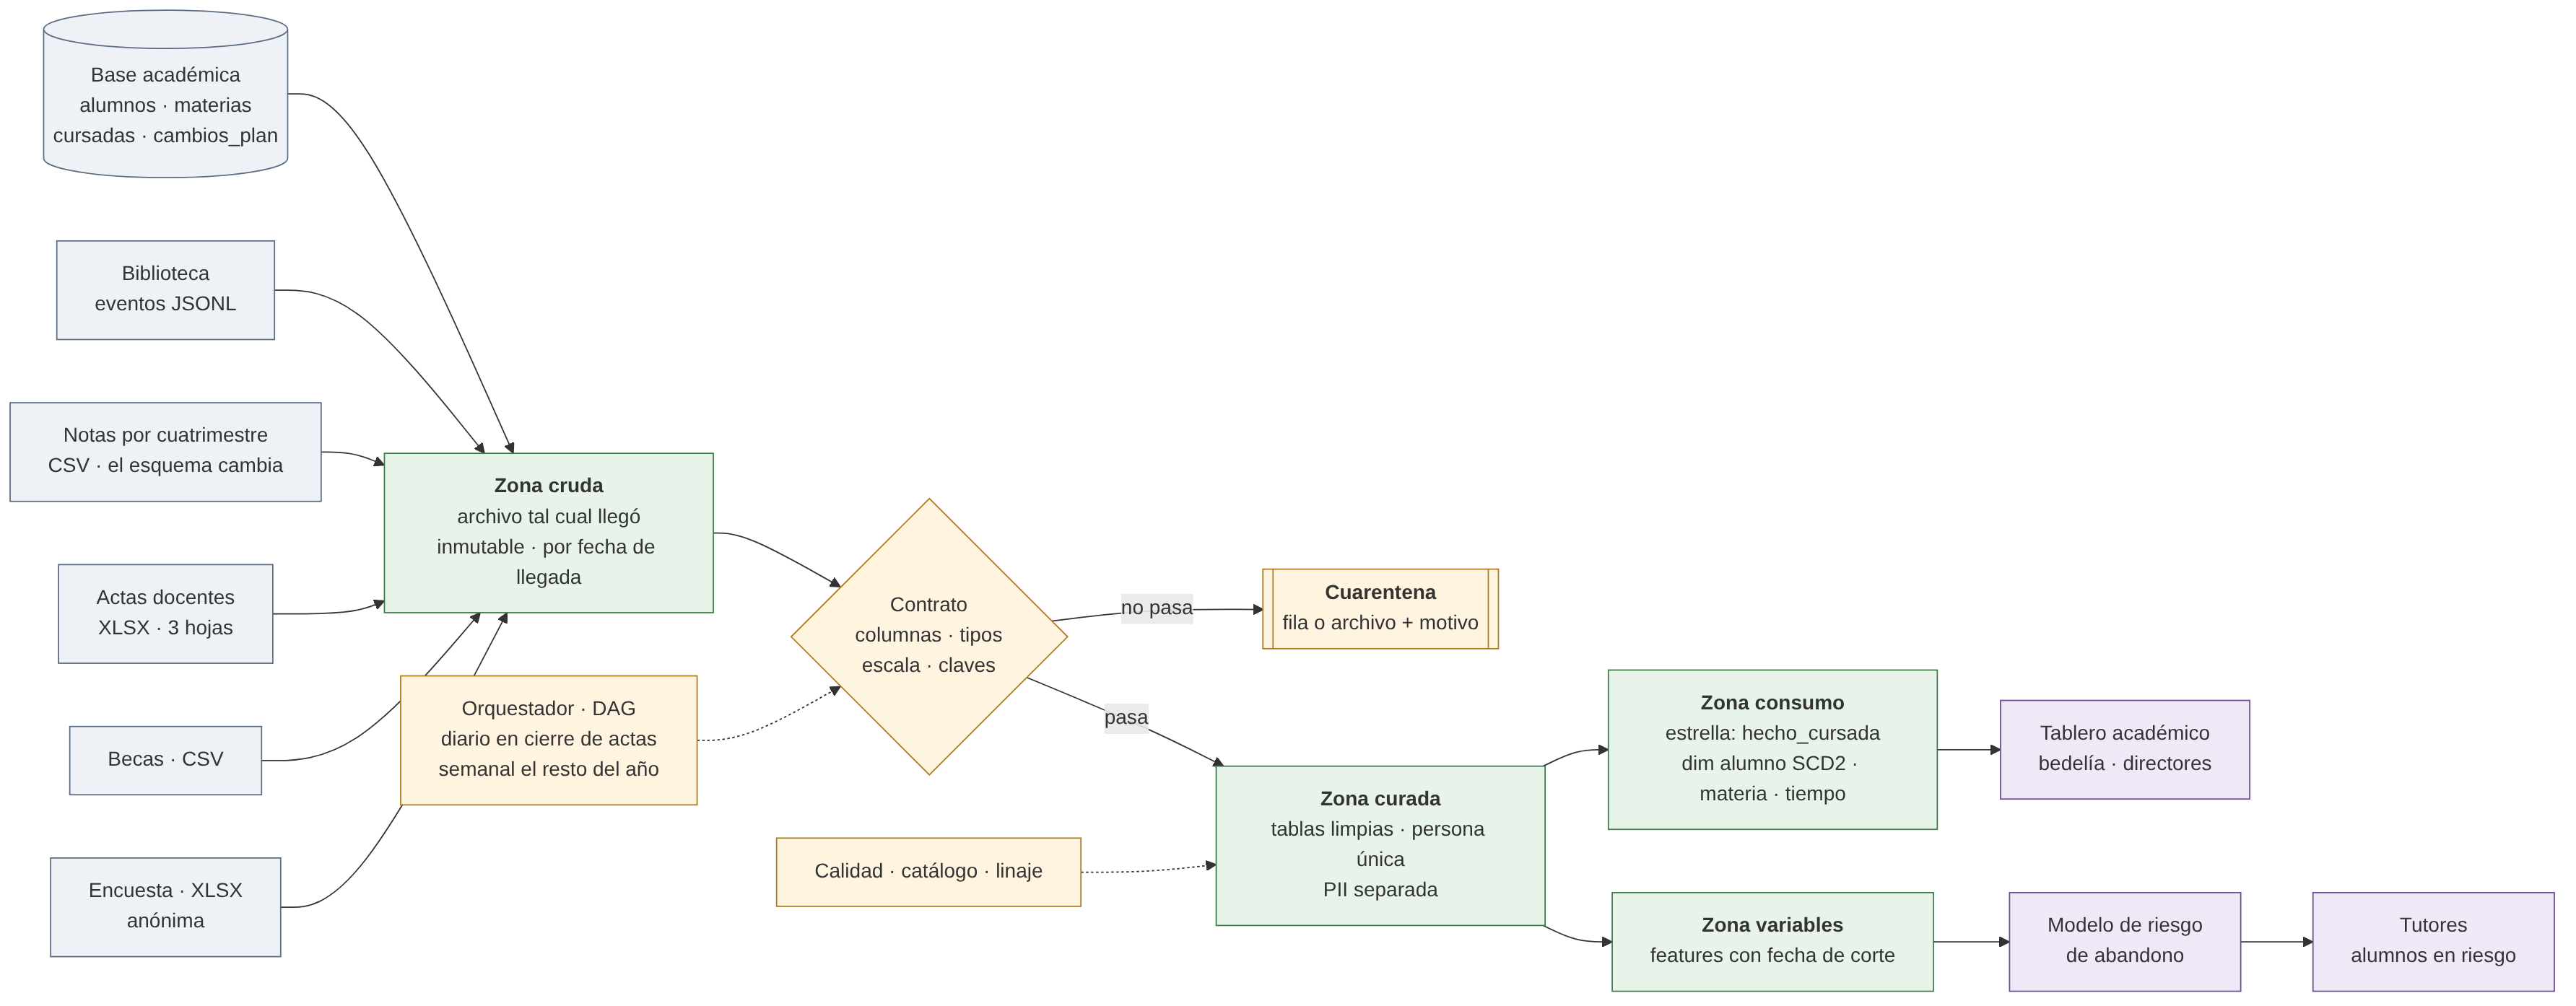

*El código fuente del diagrama está en `img/arquitectura.mmd` (Mermaid), por si hay que editarlo.*

**Cómo se lee.** Todo lo que llega, propio o externo, se guarda primero **tal cual** en la zona cruda. Después pasa por un contrato que revisa columnas, tipos, escala y claves. Lo que pasa el contrato va a la zona curada. Lo que no pasa va a cuarentena con su motivo, y no se pierde ni se arregla a ciegas. Desde la zona curada salen dos caminos:
- **consumo:** el modelo estrella, para los tableros;
- **variables:** las variables del modelo de abandono, calculadas con una fecha de corte para no usar información del futuro.

| Campo | Contenido |
| --- | --- |
| Decisión | Dónde y en qué forma se guardan los datos: **lakehouse liviano**. La zona cruda guarda archivos, y las zonas curada, variables y consumo son tablas SQL con esquema (SQLite en este trabajo). |
| Restricción comprobable | 1) Los archivos externos cambian de formato sin aviso (en el diagnóstico: columnas renombradas y escala 0–100 en 2025-1c). 2) Hay que poder **reprocesar** cuando cambia una regla, por ejemplo cómo se resuelven los dos legajos. 3) El volumen es chico: 2.060 alumnos, 15.315 cursadas, 10.946 préstamos y unos 2,5 MB en total. 4) Hace falta un modelo dimensional con historia (SCD 2) y variables para Machine Learning. |
| Opción elegida y costo que se acepta | Lakehouse liviano. El costo es tener dos formas de almacenamiento (archivos y tablas), y que el catálogo tiene que mantenerlas alineadas. También se guarda más, porque los crudos no se borran, pero con unos 2,5 MB en total eso es despreciable. |
| **Alternativa descartada y por qué** | **Data warehouse clásico con ETL**, que transforma antes de guardar y solo guarda el resultado limpio. Se descarta porque, cuando un archivo cambia de formato, el original se pierde. Sin el original no hay reproceso ni evidencia de qué llegó. **También se descarta un lakehouse con Spark y Delta Lake:** resuelve un volumen que no tenemos y suma un clúster que el caso no justifica. |
| Control que detecta el fallo y qué se hace cuando suena | **Balance de filas por lote:** filas leídas en cruda = filas cargadas en curada + filas en cuarentena. Se registra en `control_lote`. Si no cierra, el lote queda en estado «falló», no se publica en consumo y el tablero sigue mostrando el último lote bueno. Decide la **responsable de datos académicos** (rol de gobierno, módulo 6): reprocesa, o libera el lote con una nota. |

**Qué cambiaría la decisión.**
- Si el volumen se multiplicara por cien (por ejemplo, eventos de un campus virtual por clic), la zona cruda pasaría a Parquet particionado, y el procesamiento a Spark o DuckDB.
- Si se necesitaran alertas de abandono en minutos en vez de días, haría falta ingestión por eventos (streaming).

Hoy ninguno de los dos aplica: el calendario es diario como máximo.

## 2 · Modelado

### Modelo conceptual: qué cosas existen y cómo se relacionan

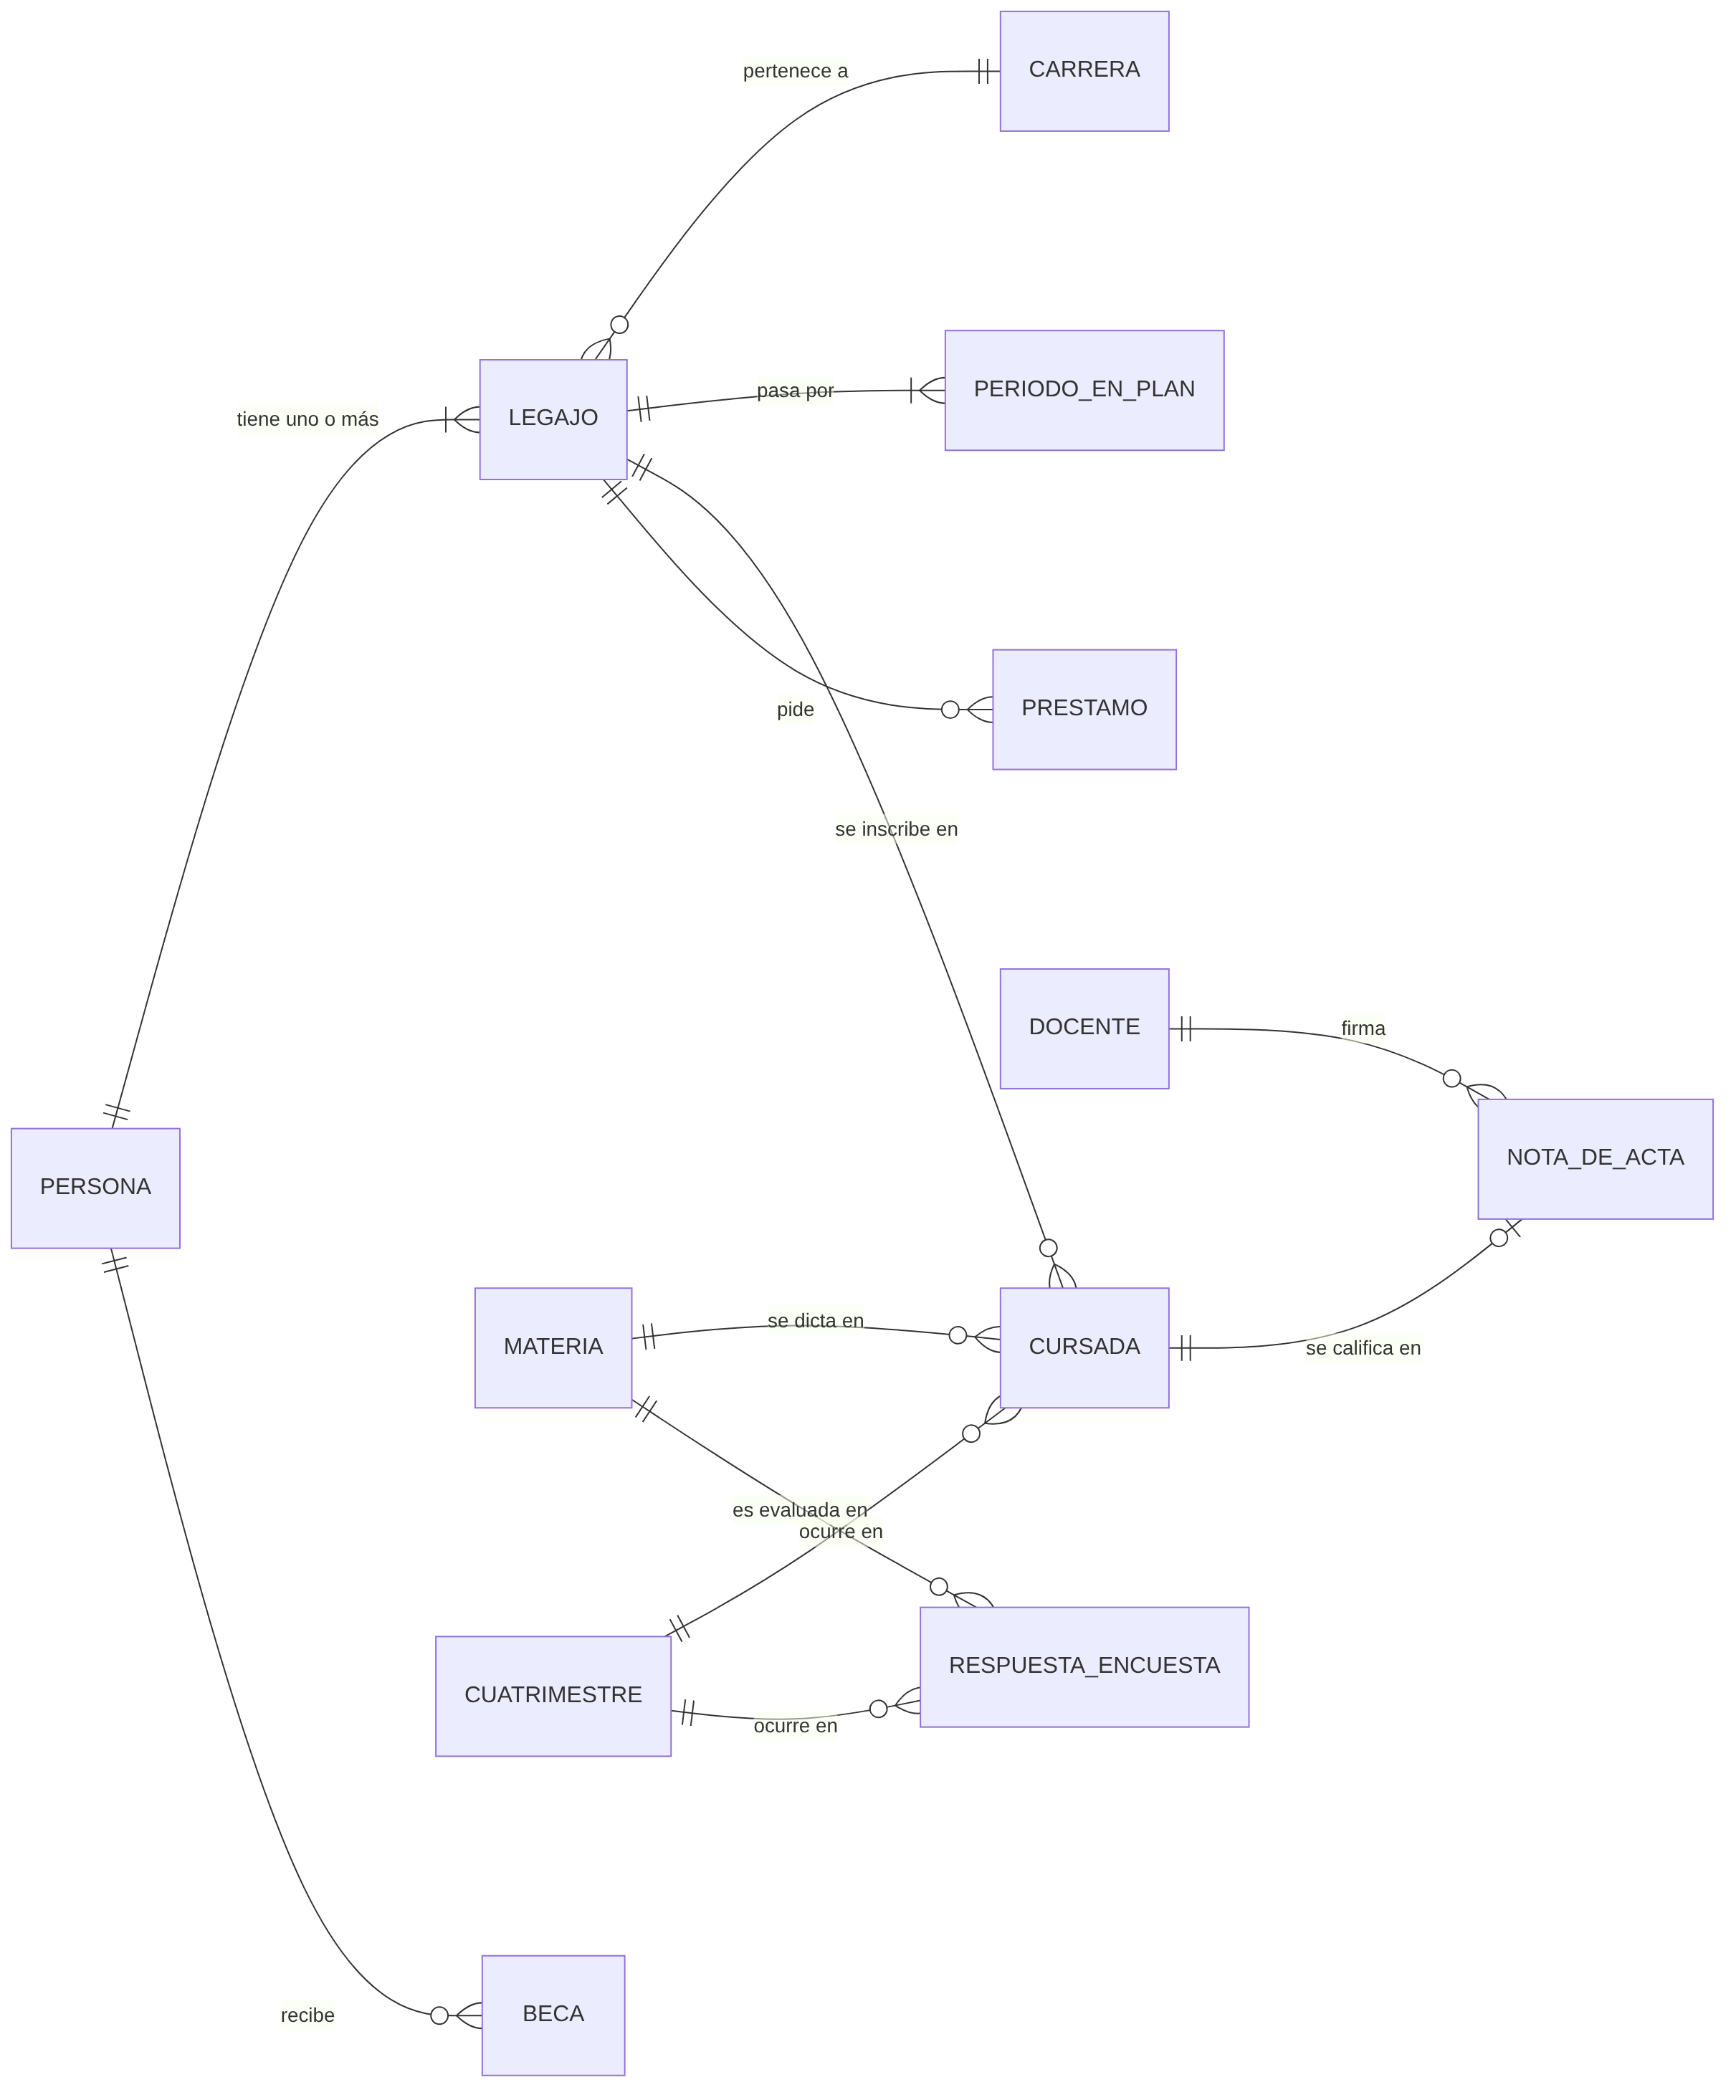

**La decisión central está en la primera relación: una persona tiene uno o más legajos.** El diagnóstico mostró 60 personas con dos legajos. Si el modelo tratara al legajo como si fuera la persona, esas 60 personas contarían dos veces en cualquier indicador. Y el modelo de abandono vería a un alumno «nuevo» sin historia.

### Modelo lógico: entidades, claves y atributos (sin pensar en el motor)

| Entidad | Clave | Atributos | Se relaciona con |
| --- | --- | --- | --- |
| Persona | id_persona | DNI, nombre, fecha de nacimiento, correo | Legajo (1 a N), Beca (1 a N) |
| Legajo | legajo | id_alumno, carrera, es_vigente | Persona (N a 1), Cursada (1 a N), Préstamo (1 a N) |
| Período en plan | persona + válido_desde | plan, válido_hasta | Persona (N a 1). En el físico son las versiones de `dim_alumno` |
| Materia | id_materia | nombre, carrera | Cursada (1 a N), Respuesta de encuesta (1 a N) |
| Cuatrimestre | cuatrimestre | año, número, fecha de inicio, fecha de fin | Cursada (1 a N) |
| Cursada | id_cursada | estado | Legajo, Materia, Cuatrimestre; Nota de acta (1 a 0 o 1) |
| Nota de acta | id_cursada | nota, ausente, docente, condición, fuente | Cursada (1 a 1) |
| Préstamo | persona + ISBN + fecha y hora | — | Persona (N a 1) |
| Beca | persona + desde | tipo, porcentaje | Persona (N a 1) |
| Respuesta de encuesta | id_respuesta | puntaje, comentario | Materia, Cuatrimestre (sin persona: es anónima) |

### Modelo dimensional: el hecho de cursada y nota

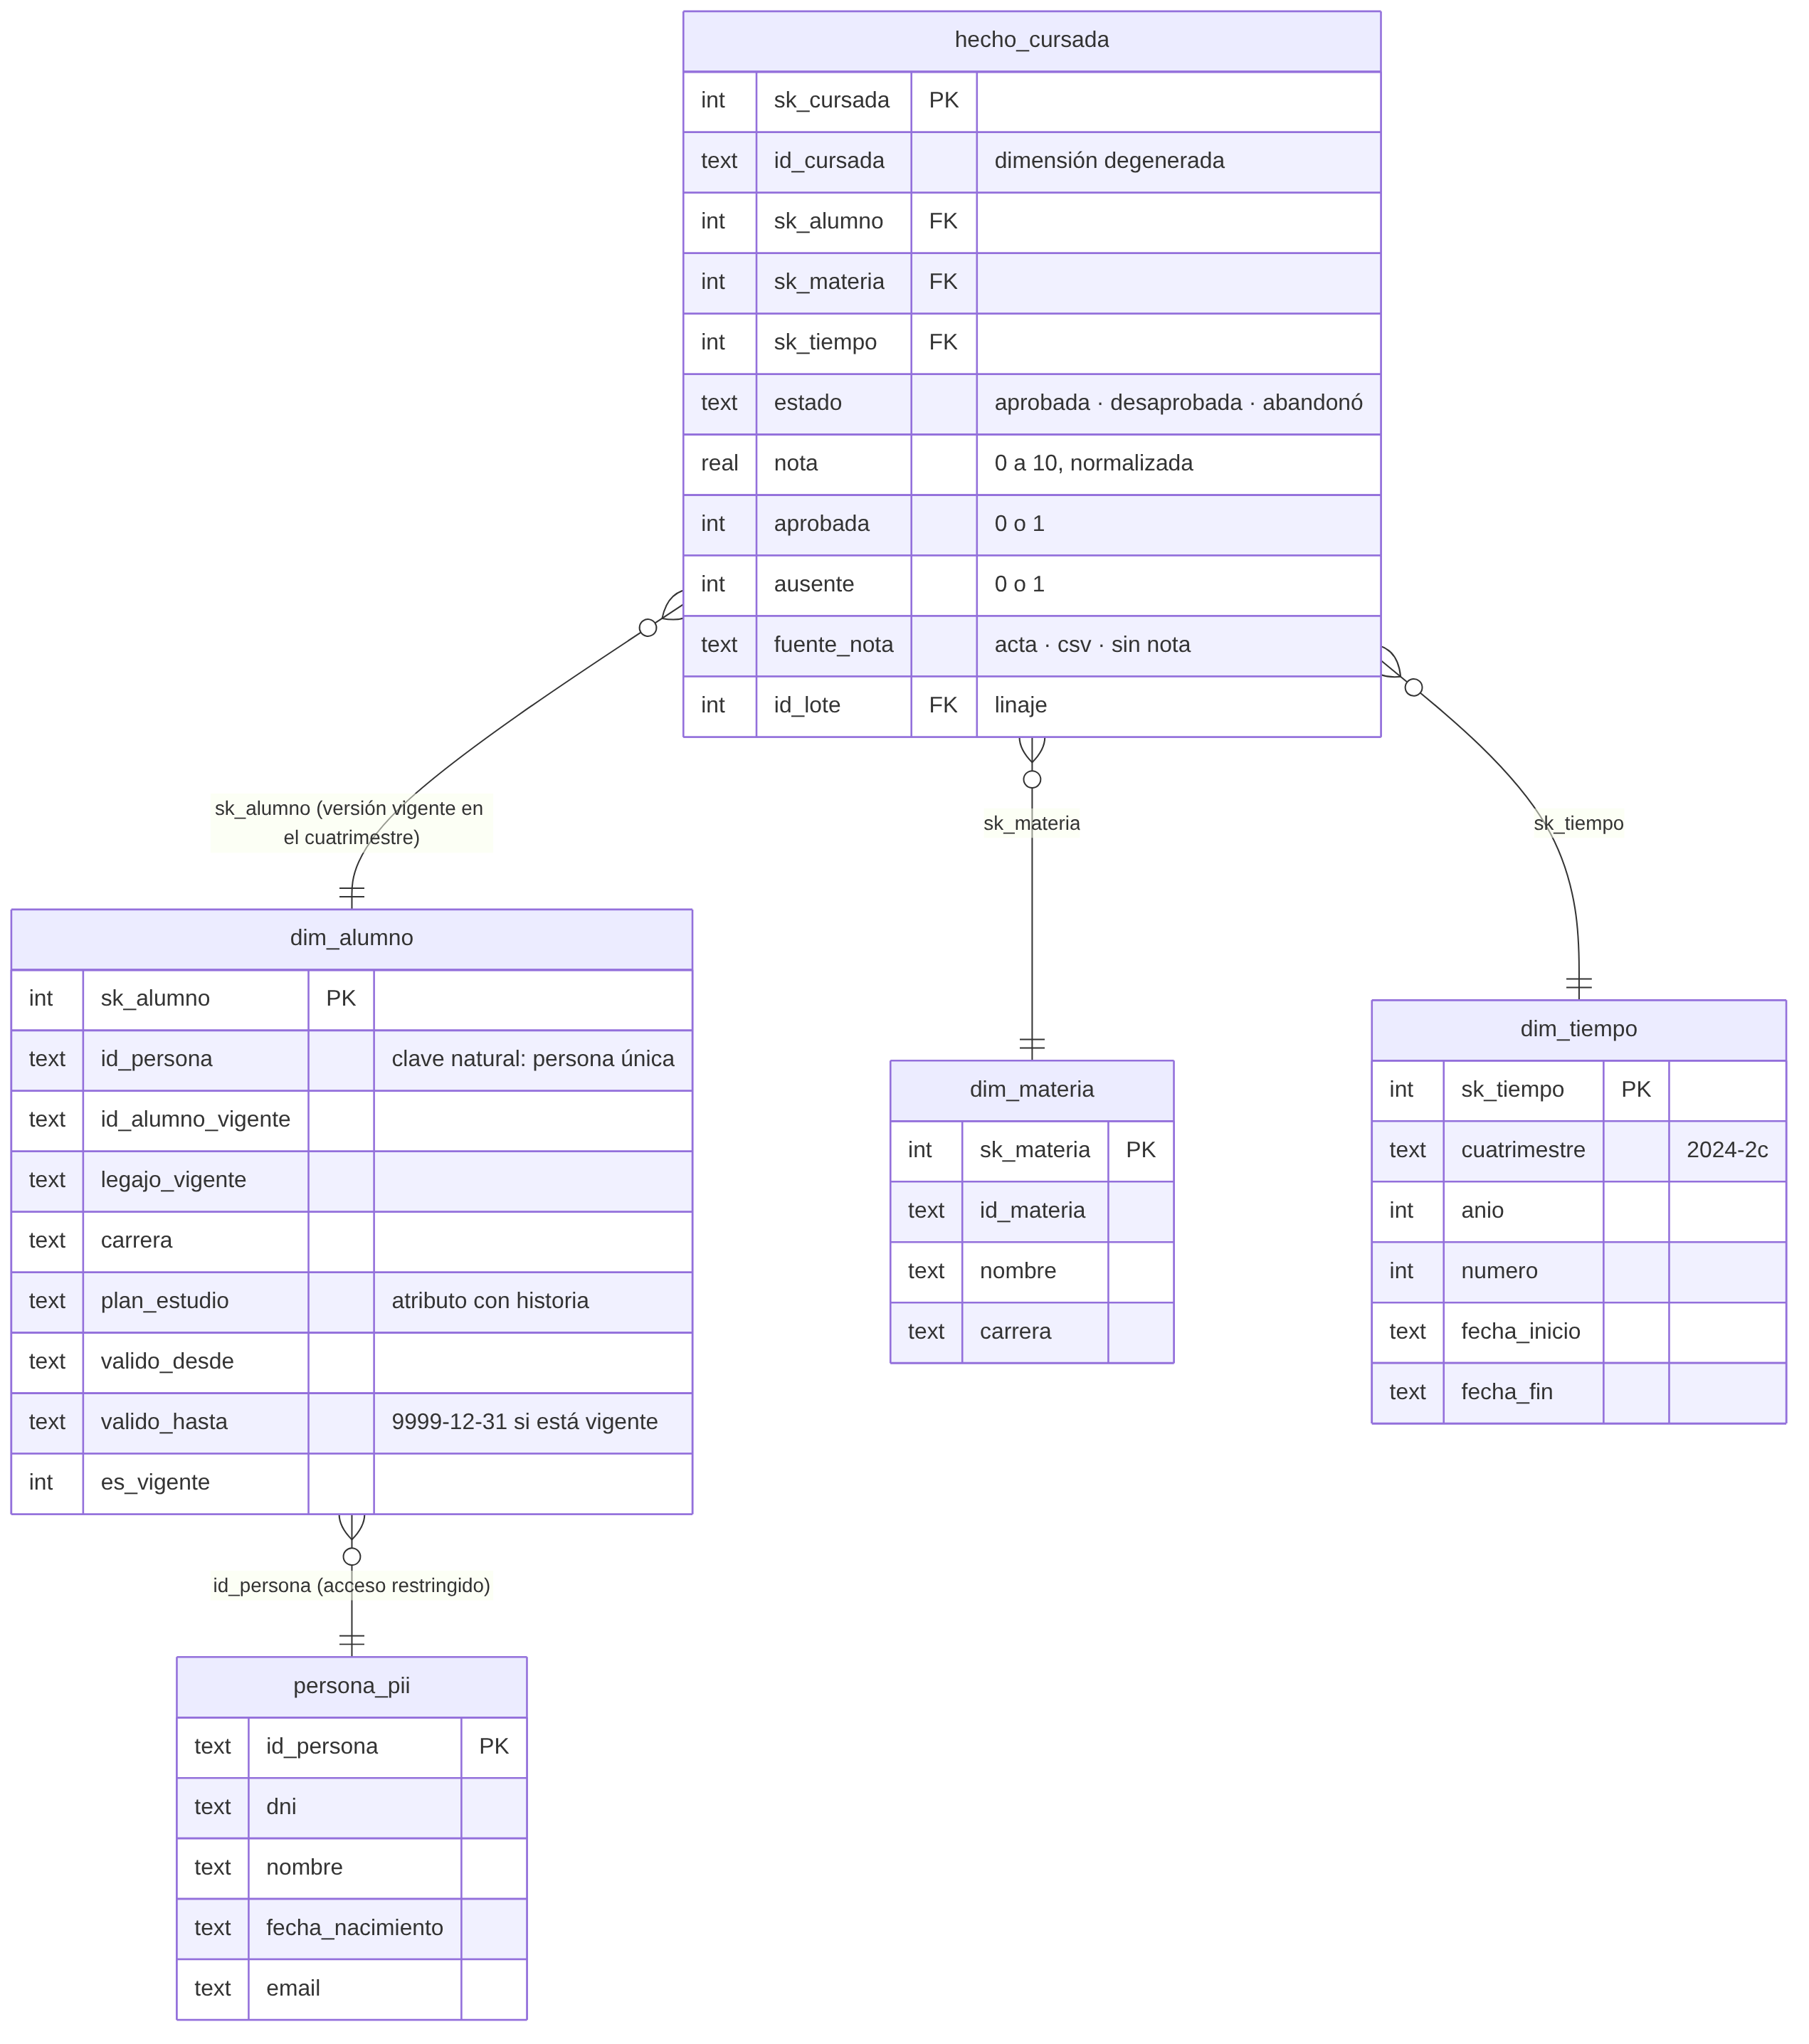

- **Grano del hecho:** una fila por **persona × materia × cuatrimestre**. Es la pregunta de negocio: cómo le fue a esta persona en esta materia este cuatrimestre.
- **Medidas:** `nota` (normalizada de 0 a 10), `aprobada` (0 o 1, para sumar y sacar tasas) y `ausente` (0 o 1).
- **Atributos de control:** `fuente_nota` (acta, CSV o sin nota) y `id_lote` (de qué carga vino la fila, para el linaje).
- **`dim_alumno` guarda historia (SCD tipo 2).** Cada cambio de plan cierra la versión anterior (`valido_hasta`) y abre una nueva. La cursada apunta a **la versión vigente al inicio del cuatrimestre**, que es el momento de la inscripción. Así, «tasa de aprobación por plan» cuenta a cada alumno en el plan en el que realmente cursó.
- **Los datos personales no están en la dimensión.** Viven en `persona_pii`, una tabla aparte con acceso restringido (módulo 9). Quien arma un tablero no necesita el DNI para contar aprobados.

| Campo | Decisión 1: grano y SCD 2 | Decisión 2: datos personales separados |
| --- | --- | --- |
| Restricción comprobable | 60 personas con dos legajos; 300 alumnos cambiaron de plan durante 2025-1c, y la base solo guarda el plan actual. | El caso marca como sensibles DNI, nombre, fecha de nacimiento, correo y legajo. |
| Opción elegida y costo que se acepta | Grano persona × materia × cuatrimestre, con `dim_alumno` en SCD 2. Costo: la carga tiene que buscar la versión vigente por fecha, y la dimensión crece con cada cambio. | Tabla `persona_pii` separada, unida por `id_persona`. Costo: un join más para quien sí está autorizado a ver datos personales. |
| **Alternativa descartada y por qué** | **SCD tipo 1** (pisar el plan). Se pierde en qué plan cursó cada alumno, y el indicador por plan queda mal para los 300 que cambiaron. **Grano por legajo:** cuenta dos veces a 60 personas. | **Enmascarar las columnas dentro de `dim_alumno`.** Todos los que leen la dimensión quedan a un permiso mal dado de ver el DNI. Separar la tabla vuelve el control más simple: se da o no se da acceso a una tabla. |
| Control que detecta el fallo y qué se hace cuando suena | Restricciones en el motor: única por grano, una sola versión vigente por persona y fechas coherentes (ver las pruebas abajo). Si una carga las viola, la transacción se revierte entera y el lote queda en «falló». | Ninguna tabla de consumo tiene columnas de datos personales: hay una prueba que lo verifica sobre el DDL. |

**Supuestos nuevos**

| # | Supuesto | Por qué |
| --- | --- | --- |
| S8 | El primer cuatrimestre va del 1/3 al 31/7 y el segundo del 1/8 al 31/12. | Los préstamos arrancan el 1/8/2024, las becas rigen desde el 1/3/2025 y los cambios de plan caen entre marzo y junio. |
| S9 | Una cursada pertenece a la versión del alumno vigente al inicio del cuatrimestre. | El alumno se inscribe con el plan que tiene en ese momento. Los cambios de plan ocurren a mitad del cuatrimestre. |

### Modelo físico: el DDL

La celda siguiente crea el almacén (`dwh.db`) con cuatro grupos de tablas:
- **control:** lotes y cuarentena;
- **zona curada:** tablas limpias del dominio;
- **zona consumo:** el modelo estrella;
- **variables:** se arma en el módulo 7.

Se puede correr de nuevo sin problema, porque borra y vuelve a crear las tablas.

En el físico, `cursada` y `prestamo` ya apuntan a la persona: la traducción de legajo a persona se hace al pasar a la zona curada.

In [6]:
DDL = """
PRAGMA foreign_keys = ON;

-- Se borra en orden inverso a las dependencias, para poder correr la celda las veces que haga falta.
DROP TABLE IF EXISTS riesgo_abandono;
DROP TABLE IF EXISTS registro_modelo;
DROP TABLE IF EXISTS etiqueta_abandono;
DROP TABLE IF EXISTS variables_abandono;
DROP TABLE IF EXISTS hecho_cursada;
DROP TABLE IF EXISTS dim_alumno;
DROP TABLE IF EXISTS dim_materia;
DROP TABLE IF EXISTS dim_tiempo;
DROP TABLE IF EXISTS respuesta_encuesta;
DROP TABLE IF EXISTS beca;
DROP TABLE IF EXISTS prestamo;
DROP TABLE IF EXISTS nota;
DROP TABLE IF EXISTS cursada;
DROP TABLE IF EXISTS legajo;
DROP TABLE IF EXISTS persona_pii;
DROP TABLE IF EXISTS materia;
DROP TABLE IF EXISTS auditoria_acceso;
DROP TABLE IF EXISTS resultado_calidad;
DROP TABLE IF EXISTS control_particion;
DROP TABLE IF EXISTS cuarentena;
DROP TABLE IF EXISTS control_lote;

-- ============ CONTROL: de dónde vino cada fila y qué quedó afuera ============
CREATE TABLE control_lote (
    id_lote           INTEGER PRIMARY KEY,
    proceso           TEXT NOT NULL,                 -- p. ej. 'ingesta_notas', 'carga_dim_alumno'
    fuente            TEXT NOT NULL,                 -- p. ej. 'notas_2025-1c.csv'
    inicio            TEXT NOT NULL,
    fin               TEXT,
    filas_leidas      INTEGER,
    filas_cargadas    INTEGER,
    filas_cuarentena  INTEGER,
    huella            TEXT,                          -- SHA-256 del archivo: si ya se ingirió igual, no se reprocesa
    estado            TEXT NOT NULL CHECK (estado IN ('en curso', 'ok', 'falló', 'omitido')),
    detalle           TEXT                           -- qué pasó, sobre todo cuando falla
);

CREATE TABLE cuarentena (
    id_cuarentena  INTEGER PRIMARY KEY,
    id_lote        INTEGER NOT NULL REFERENCES control_lote (id_lote),
    fuente         TEXT NOT NULL,
    registro       TEXT NOT NULL,                    -- la fila original, en JSON, tal como llegó
    motivo         TEXT NOT NULL,                    -- p. ej. 'nota fuera de rango', 'alumno inexistente'
    resuelto       INTEGER NOT NULL DEFAULT 0 CHECK (resuelto IN (0, 1))
);

CREATE TABLE control_particion (                     -- qué se publicó de cada cuatrimestre en la zona consumo
    cuatrimestre  TEXT PRIMARY KEY,
    huella        TEXT NOT NULL,                     -- SHA-256 de las filas curadas que se publicaron
    filas         INTEGER NOT NULL,
    id_lote       INTEGER NOT NULL REFERENCES control_lote (id_lote),
    publicada     TEXT NOT NULL
);

CREATE TABLE resultado_calidad (                     -- cada medición de cada regla de calidad (módulo 6)
    id_resultado  INTEGER PRIMARY KEY,
    id_lote       INTEGER NOT NULL REFERENCES control_lote (id_lote),
    regla         TEXT NOT NULL,
    dimensión     TEXT NOT NULL,
    valor         REAL NOT NULL,
    umbral        REAL NOT NULL,
    cumple        INTEGER NOT NULL CHECK (cumple IN (0, 1)),
    decide        TEXT NOT NULL
);

CREATE TABLE auditoria_acceso (                      -- quién pidió qué, qué vio y qué no (módulo 9)
    id_acceso     INTEGER PRIMARY KEY,
    momento       TEXT NOT NULL,
    rol           TEXT NOT NULL,
    objeto        TEXT NOT NULL,
    resultado     TEXT NOT NULL CHECK (resultado IN ('permitido', 'denegado')),
    filas         INTEGER,
    enmascaradas  TEXT,
    quitadas      TEXT
);

-- ============ ZONA CURADA: el dominio limpio ============
CREATE TABLE persona_pii (                           -- acceso restringido (módulo 9)
    id_persona        TEXT PRIMARY KEY,
    dni               TEXT NOT NULL UNIQUE CHECK (length(dni) = 8 AND dni NOT GLOB '*[^0-9]*'),
    nombre            TEXT NOT NULL,
    fecha_nacimiento  TEXT NOT NULL CHECK (date(fecha_nacimiento) IS NOT NULL),
    email             TEXT NOT NULL CHECK (email LIKE '%_@_%')
);

CREATE TABLE legajo (                                -- equivalencias: una persona, uno o más legajos
    legajo      TEXT PRIMARY KEY CHECK (legajo GLOB 'L[0-9][0-9][0-9][0-9][0-9]'),
    id_alumno   TEXT NOT NULL UNIQUE,
    id_persona  TEXT NOT NULL REFERENCES persona_pii (id_persona),
    carrera     TEXT NOT NULL,
    es_vigente  INTEGER NOT NULL CHECK (es_vigente IN (0, 1))
);
CREATE UNIQUE INDEX ux_legajo_un_vigente ON legajo (id_persona) WHERE es_vigente = 1;

CREATE TABLE materia (
    id_materia  TEXT PRIMARY KEY,
    nombre      TEXT NOT NULL UNIQUE,
    carrera     TEXT NOT NULL
);

CREATE TABLE cursada (
    id_cursada    TEXT PRIMARY KEY,
    id_persona    TEXT NOT NULL REFERENCES persona_pii (id_persona),
    id_materia    TEXT NOT NULL REFERENCES materia (id_materia),
    cuatrimestre  TEXT NOT NULL CHECK (cuatrimestre GLOB '[0-9][0-9][0-9][0-9]-[12]c'),
    estado        TEXT NOT NULL CHECK (estado IN ('aprobada', 'desaprobada', 'abandonó')),
    UNIQUE (id_persona, id_materia, cuatrimestre)
);

CREATE TABLE nota (                                  -- una nota por cursada, ya normalizada de 0 a 10
    id_cursada   TEXT PRIMARY KEY REFERENCES cursada (id_cursada),
    nota         REAL CHECK (nota IS NULL OR nota BETWEEN 0 AND 10),
    ausente      INTEGER NOT NULL DEFAULT 0 CHECK (ausente IN (0, 1)),
    docente      TEXT,
    condicion    TEXT CHECK (condicion IS NULL OR condicion IN ('Regular', 'Libre')),
    fuente_nota  TEXT NOT NULL CHECK (fuente_nota IN ('acta', 'csv')),
    id_lote      INTEGER REFERENCES control_lote (id_lote),
    CHECK (NOT (ausente = 1 AND nota IS NOT NULL))   -- un ausente no tiene nota
);

CREATE TABLE prestamo (
    id_persona  TEXT NOT NULL REFERENCES persona_pii (id_persona),
    isbn        TEXT NOT NULL CHECK (length(isbn) = 13),
    ts          TEXT NOT NULL CHECK (datetime(ts) IS NOT NULL),
    id_lote     INTEGER REFERENCES control_lote (id_lote),
    PRIMARY KEY (id_persona, isbn, ts)               -- clave natural: reprocesar no duplica
);

CREATE TABLE beca (
    id_persona  TEXT NOT NULL REFERENCES persona_pii (id_persona),
    tipo_beca   TEXT NOT NULL,
    porcentaje  INTEGER NOT NULL CHECK (porcentaje BETWEEN 1 AND 100),
    desde       TEXT NOT NULL CHECK (date(desde) IS NOT NULL),
    PRIMARY KEY (id_persona, desde)
);

CREATE TABLE respuesta_encuesta (                    -- anónima: no tiene ninguna columna de persona
    id_respuesta  INTEGER PRIMARY KEY,
    id_materia    TEXT NOT NULL REFERENCES materia (id_materia),
    cuatrimestre  TEXT NOT NULL,
    puntaje       INTEGER NOT NULL CHECK (puntaje BETWEEN 1 AND 5),
    comentario    TEXT
);

-- ============ ZONA CONSUMO: el modelo estrella ============
CREATE TABLE dim_tiempo (
    sk_tiempo     INTEGER PRIMARY KEY,
    cuatrimestre  TEXT NOT NULL UNIQUE,
    anio          INTEGER NOT NULL,
    numero        INTEGER NOT NULL CHECK (numero IN (1, 2)),
    fecha_inicio  TEXT NOT NULL,
    fecha_fin     TEXT NOT NULL,
    CHECK (fecha_inicio < fecha_fin)
);

CREATE TABLE dim_materia (
    sk_materia  INTEGER PRIMARY KEY,
    id_materia  TEXT NOT NULL UNIQUE,
    nombre      TEXT NOT NULL,
    carrera     TEXT NOT NULL
);

CREATE TABLE dim_alumno (                            -- SCD tipo 2: una fila por versión
    sk_alumno         INTEGER PRIMARY KEY,
    id_persona        TEXT NOT NULL,                 -- clave natural (sin datos personales)
    id_alumno_vigente TEXT NOT NULL,
    legajo_vigente    TEXT NOT NULL,
    carrera           TEXT NOT NULL,
    plan_estudio      TEXT NOT NULL,
    valido_desde      TEXT NOT NULL,
    valido_hasta      TEXT NOT NULL DEFAULT '9999-12-31',
    es_vigente        INTEGER NOT NULL CHECK (es_vigente IN (0, 1)),
    UNIQUE (id_persona, valido_desde),
    CHECK (valido_desde < valido_hasta),
    CHECK ((es_vigente = 1) = (valido_hasta = '9999-12-31'))
);
CREATE UNIQUE INDEX ux_dim_alumno_un_vigente ON dim_alumno (id_persona) WHERE es_vigente = 1;

CREATE TABLE hecho_cursada (                         -- grano: persona × materia × cuatrimestre
    sk_cursada   INTEGER PRIMARY KEY,
    id_cursada   TEXT NOT NULL UNIQUE,               -- dimensión degenerada
    sk_alumno    INTEGER NOT NULL REFERENCES dim_alumno (sk_alumno),
    sk_materia   INTEGER NOT NULL REFERENCES dim_materia (sk_materia),
    sk_tiempo    INTEGER NOT NULL REFERENCES dim_tiempo (sk_tiempo),
    estado       TEXT NOT NULL CHECK (estado IN ('aprobada', 'desaprobada', 'abandonó')),
    nota         REAL CHECK (nota IS NULL OR nota BETWEEN 0 AND 10),
    aprobada     INTEGER NOT NULL CHECK (aprobada IN (0, 1)),
    ausente      INTEGER NOT NULL CHECK (ausente IN (0, 1)),
    fuente_nota  TEXT NOT NULL CHECK (fuente_nota IN ('acta', 'csv', 'sin nota')),
    id_lote      INTEGER REFERENCES control_lote (id_lote),
    UNIQUE (sk_alumno, sk_materia, sk_tiempo)
);
CREATE INDEX ix_hecho_tiempo  ON hecho_cursada (sk_tiempo);

CREATE TABLE riesgo_abandono (                       -- la lista para tutores (salida del modelo)
    id_persona     TEXT NOT NULL,
    corte          TEXT NOT NULL,
    version_modelo TEXT NOT NULL,
    score          REAL NOT NULL CHECK (score BETWEEN 0 AND 1),
    puesto         INTEGER NOT NULL,
    en_lista       INTEGER NOT NULL CHECK (en_lista IN (0, 1)),
    PRIMARY KEY (id_persona, corte, version_modelo)
);

-- ============ ZONA VARIABLES: lo que ve el modelo, siempre con su fecha de corte ============
CREATE TABLE variables_abandono (
    id_persona          TEXT NOT NULL,
    corte               TEXT NOT NULL,           -- todo lo que entra en la fila ocurrió ANTES de esta fecha
    cuatrimestre_base   TEXT NOT NULL,           -- el último cuatrimestre terminado antes del corte
    prom_nota           REAL,
    n_desaprobadas      INTEGER NOT NULL,
    prestamos_90d       INTEGER NOT NULL,
    prestamos_180d      INTEGER NOT NULL,
    dias_sin_prestamo   INTEGER NOT NULL,
    porcentaje_beca     INTEGER NOT NULL,
    plan_2023           INTEGER NOT NULL CHECK (plan_2023 IN (0, 1)),
    PRIMARY KEY (id_persona, corte)
);

CREATE TABLE etiqueta_abandono (                     -- separada de las variables: el modelo nunca la ve al predecir
    id_persona  TEXT NOT NULL,
    corte       TEXT NOT NULL,
    abandono    INTEGER NOT NULL CHECK (abandono IN (0, 1)),
    PRIMARY KEY (id_persona, corte)
);

CREATE TABLE registro_modelo (                       -- versiones del modelo y cuál está en producción
    version       TEXT PRIMARY KEY,
    tipo          TEXT NOT NULL,
    registrado    TEXT NOT NULL,
    corte_datos   TEXT NOT NULL,
    huella_datos  TEXT NOT NULL,
    metricas      TEXT NOT NULL,
    estado        TEXT NOT NULL CHECK (estado IN ('candidato', 'producción', 'respaldo', 'retirado', 'rechazado')),
    motivo        TEXT
);
CREATE UNIQUE INDEX ux_un_modelo_en_produccion ON registro_modelo (estado) WHERE estado = 'producción';
CREATE INDEX ix_hecho_materia ON hecho_cursada (sk_materia);
"""

almacen = dwh()
almacen.executescript(DDL)
almacen.execute("PRAGMA foreign_keys = ON")

zona = {"control": ["control_lote", "cuarentena", "control_particion", "resultado_calidad", "auditoria_acceso"],
        "curada": ["persona_pii", "legajo", "materia", "cursada", "nota", "prestamo", "beca", "respuesta_encuesta"],
        "consumo": ["dim_tiempo", "dim_materia", "dim_alumno", "hecho_cursada", "riesgo_abandono"],
        "variables": ["variables_abandono", "etiqueta_abandono"],
        "modelos": ["registro_modelo"]}
tablas = sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", base="dwh.db").name.tolist()
pd.DataFrame([{"zona": z, "tabla": t, "creada": t in tablas} for z, ts in zona.items() for t in ts])

,zona,tabla,creada
0,control,control_lote,True
1,control,cuarentena,True
2,control,control_particion,True
3,control,resultado_calidad,True
4,control,auditoria_acceso,True
5,curada,persona_pii,True
6,curada,legajo,True
7,curada,materia,True
8,curada,cursada,True
9,curada,nota,True


### Pruebas del modelo físico

Un modelo es verificable si **rechaza los casos difíciles** que encontramos en el diagnóstico. Cada prueba intenta meter un dato malo y espera que el motor lo rechace. Las pruebas corren dentro de una transacción que después se revierte, así que el almacén queda vacío para la carga del módulo 3.

In [7]:
# Pruebas del modelo físico: cada restricción tiene que rechazar el caso difícil que encontramos en el diagnóstico.
# Todo corre dentro de una transacción que al final se revierte: el almacén queda vacío.
def debe_fallar(nombre, sentencia):
    try:
        almacen.execute(sentencia)
        return {"prueba": nombre, "resultado": "✘ lo aceptó (la restricción no funciona)", "motivo": ""}
    except sqlite3.IntegrityError as error:
        return {"prueba": nombre, "resultado": "✔ rechazado", "motivo": str(error)}

almacen.execute("SAVEPOINT pruebas")
# Filas válidas de base (un alumno que cambió de plan en 2025, con una cursada), para probar contra ellas.
for s in ["INSERT INTO dim_tiempo  VALUES (1, '2024-2c', 2024, 2, '2024-08-01', '2024-12-31')",
          "INSERT INTO dim_materia VALUES (1, 'MT000', 'Materia 00', 'Diseño')",
          "INSERT INTO dim_alumno  VALUES (1, 'P00771', 'AL00771', 'L20771', 'Administración', '2018', '2024-08-01', '2025-04-15', 0)",
          "INSERT INTO dim_alumno  VALUES (2, 'P00771', 'AL00771', 'L20771', 'Administración', '2023', '2025-04-15', '9999-12-31', 1)",
          "INSERT INTO hecho_cursada VALUES (1, 'CU000001', 1, 1, 1, 'aprobada', 7.0, 1, 0, 'acta', NULL)",
          "INSERT INTO persona_pii VALUES ('P00771', '20442824', 'Alumno 00771', '2003-01-04', 'alumno771@uniandina.test')"]:
    almacen.execute(s)

pruebas = pd.DataFrame([
    debe_fallar("Nota fuera de rango (12, como en notas_2024-2c)",
                "INSERT INTO hecho_cursada VALUES (2, 'CU000002', 2, 1, 1, 'aprobada', 12, 1, 0, 'csv', NULL)"),
    debe_fallar("Nota sin normalizar (escala 0–100 de 2025-1c)",
                "INSERT INTO nota VALUES ('CU000001', 80, 0, 'DOC09', 'Regular', 'csv', NULL)"),
    debe_fallar("Misma persona, materia y cuatrimestre dos veces (duplicado)",
                "INSERT INTO hecho_cursada VALUES (3, 'CU999999', 1, 1, 1, 'aprobada', 7.0, 1, 0, 'csv', NULL)"),
    debe_fallar("Cursada de un alumno que no existe (los AL9xxxx)",
                "INSERT INTO hecho_cursada VALUES (4, 'CX00000', 99, 1, 1, 'aprobada', 7.0, 1, 0, 'csv', NULL)"),
    debe_fallar("Dos versiones vigentes de la misma persona",
                "INSERT INTO dim_alumno VALUES (3, 'P00771', 'AL02013', 'L30013', 'Administración', '2023', '2025-05-01', '9999-12-31', 1)"),
    debe_fallar("Versión con fechas al revés",
                "INSERT INTO dim_alumno VALUES (4, 'P00999', 'AL00999', 'L20999', 'Derecho', '2018', '2025-06-01', '2025-01-01', 0)"),
    debe_fallar("Versión marcada vigente pero con fecha de cierre",
                "INSERT INTO dim_alumno VALUES (5, 'P00998', 'AL00998', 'L20998', 'Derecho', '2018', '2024-08-01', '2025-01-01', 1)"),
    debe_fallar("Mismo DNI para dos personas (los legajos duplicados)",
                "INSERT INTO persona_pii VALUES ('P02013', '20442824', 'Alumno 00771', '2003-01-04', 'alumno771@uniandina.test')"),
    debe_fallar("DNI con puntos (como llega en becas.csv)",
                "INSERT INTO persona_pii VALUES ('P00001', '35.527.738', 'X', '2000-01-01', 'x@uniandina.test')"),
    debe_fallar("Legajo sin la «L» (como llega en las actas)",
                "INSERT INTO legajo VALUES ('21464', 'AL01464', 'P00771', 'Derecho', 0)"),
    debe_fallar("Ausente con nota",
                "INSERT INTO nota VALUES ('CU000001', 7, 1, 'DOC09', 'Regular', 'acta', NULL)"),
    debe_fallar("Puntaje de encuesta fuera de 1 a 5",
                "INSERT INTO respuesta_encuesta VALUES (1, 'MT000', '2024-2c', 10, NULL)"),
])
almacen.execute("ROLLBACK TO pruebas"); almacen.execute("RELEASE pruebas")

# Y una prueba sobre el propio DDL: ninguna tabla de consumo tiene columnas de datos personales.
PII = {"dni", "nombre", "fecha_nacimiento", "email"}
columnas_consumo = {t: set(sql(f"PRAGMA table_info({t})", base="dwh.db").name) for t in zona["consumo"]}
fugas = {t: sorted(c & PII) for t, c in columnas_consumo.items() if (c & PII) - ({"nombre"} if t == "dim_materia" else set())}
print("✔ Ninguna tabla de consumo tiene datos personales." if not fugas else f"✘ Datos personales en consumo: {fugas}")
print(f"{(pruebas.resultado.str.startswith('✔')).sum()} de {len(pruebas)} restricciones rechazaron el caso difícil.")
pruebas

✔ Ninguna tabla de consumo tiene datos personales.
12 de 12 restricciones rechazaron el caso difícil.


,prueba,resultado,motivo
0,"Nota fuera de rango (12, como en notas_2024-2c)",✔ rechazado,CHECK constraint failed: nota IS NULL OR nota ...
1,Nota sin normalizar (escala 0–100 de 2025-1c),✔ rechazado,CHECK constraint failed: nota IS NULL OR nota ...
2,"Misma persona, materia y cuatrimestre dos vece...",✔ rechazado,UNIQUE constraint failed: hecho_cursada.sk_alu...
3,Cursada de un alumno que no existe (los AL9xxxx),✔ rechazado,FOREIGN KEY constraint failed
4,Dos versiones vigentes de la misma persona,✔ rechazado,UNIQUE constraint failed: dim_alumno.id_persona
5,Versión con fechas al revés,✔ rechazado,CHECK constraint failed: valido_desde < valido...
6,Versión marcada vigente pero con fecha de cierre,✔ rechazado,CHECK constraint failed: (es_vigente = 1) = (v...
7,Mismo DNI para dos personas (los legajos dupli...,✔ rechazado,UNIQUE constraint failed: persona_pii.dni
8,DNI con puntos (como llega en becas.csv),✔ rechazado,CHECK constraint failed: length(dni) = 8 AND d...
9,Legajo sin la «L» (como llega en las actas),✔ rechazado,CHECK constraint failed: legajo GLOB 'L[0-9][0...


## 3 · PL/SQL

Un procedimiento que carga la dimensión alumno con historia (SCD tipo 2) y resuelve los alumnos duplicados. SQLite no tiene PL/SQL, así que cada paso es una sentencia SQL ejecutada desde una función de Python, dentro de una transacción.

**Qué hace `cargar_dim_alumno(corte)`, paso a paso:**

1. **Resuelve a la persona.** Agrupa los legajos por DNI y elige como vigente al que tiene más cursadas. La persona toma como identificador un **seudónimo** calculado a partir del legajo vigente con una clave secreta. No repite el número de legajo: si lo repitiera, enmascarar el legajo no protegería nada (módulo 9).
2. **Controla la identidad.** Un mismo DNI con otro nombre u otra fecha de nacimiento **no se fusiona**: va a cuarentena. Unir a dos personas distintas es peor que dejar un duplicado.
3. **Da de alta o actualiza** la persona (con sus datos personales, en `persona_pii`) y sus legajos. Si ya existen, no los duplica.
4. **Une los cambios de plan por persona**, aunque vengan por el legajo duplicado. Encontramos una persona con el mismo cambio cargado en sus dos legajos, en fechas distintas: vale el primero y el otro queda registrado en cuarentena.
5. **Arma la foto de cada persona a la fecha de corte**, con el plan que tenía ese día.
6. **Compara la foto con la versión vigente.** Si algo cambió, cierra la versión vigente con la fecha del cambio y abre una nueva. Si la persona no existía, la da de alta.
7. **Controla antes y después.**
   - Antes: un cambio no puede tener fecha anterior a la versión vigente.
   - Después: tiene que haber exactamente una versión vigente por persona y ninguna versión puede pisarse con otra.
   - Si un control no pasa, se revierte **toda** la transacción y el lote queda en `control_lote` como «falló», con el motivo.

| Campo | Contenido |
| --- | --- |
| Decisión | Carga **incremental** de la SCD 2, por conjuntos (estilo MERGE), con transacción y controles antes y después. |
| Restricción comprobable | La base académica **pisa** el plan (`alumnos.plan_estudio` ya tiene el nuevo). La historia solo existe porque comparamos con lo que ya cargamos. Además, 60 personas tienen dos legajos, y una tiene el mismo cambio de plan registrado dos veces. |
| Opción elegida y costo que se acepta | Incremental: cada corrida compara con la versión vigente. El costo es que **no se puede reprocesar hacia atrás**. Corregir el pasado obliga a reconstruir la dimensión desde la primera foto. |
| **Alternativa descartada y por qué** | **Reconstruir la dimensión desde cero en cada corrida** a partir de `cambios_plan`. Hoy funcionaría, pero depende de que esa tabla exista y esté completa. Si un cambio no queda registrado ahí, la historia se pierde sin que nadie lo note. El método incremental lo detecta igual, porque compara la foto con lo que ya está cargado. |
| Control que detecta el fallo y qué se hace cuando suena | Los controles del paso 7. Si suena, no se publica nada y el tablero sigue con la última carga buena. **Decide la responsable de datos académicos.** Si es un error de la fuente, se corrige ahí y se vuelve a correr. Si hace falta reprocesar hacia atrás, autoriza la reconstrucción completa. |

**Supuestos nuevos**

| # | Supuesto | Por qué |
| --- | --- | --- |
| S10 | El legajo vigente de una persona es el que tiene más cursadas. Si empatan, el más antiguo. | Los legajos L3xxxx no tienen ninguna cursada. El desempate tiene que ser determinístico para que la carga sea idempotente. |
| S11 | Un mismo DNI con otro nombre u otra fecha de nacimiento no se fusiona: va a cuarentena. | Un DNI mal tipeado uniría a dos personas distintas. Hoy no hay ningún caso, pero la regla queda. |
| S12 | Si el mismo cambio de plan figura en los dos legajos de una persona, vale el de fecha más temprana. | El plan cambió la primera vez. El segundo registro es una carga repetida. |

<details>
<summary><b>Cómo se vería en Oracle PL/SQL</b> (referencia, no se ejecuta acá)</summary>

```sql
CREATE OR REPLACE PROCEDURE cargar_dim_alumno (p_corte IN DATE) AS
    v_lote   NUMBER;
    v_atras  NUMBER;
    e_carga_rechazada EXCEPTION;
BEGIN
    v_lote := pkg_control.abrir_lote('carga_dim_alumno');          -- con PRAGMA AUTONOMOUS_TRANSACTION

    -- (staging: stg_alumno ya resuelto a persona y a la fecha de corte)
    SELECT COUNT(*) INTO v_atras
    FROM stg_alumno s JOIN dim_alumno d ON d.id_persona = s.id_persona AND d.es_vigente = 1
    WHERE d.plan_estudio <> s.plan_estudio AND NVL(s.fecha_cambio, p_corte) <= d.valido_desde;
    IF v_atras > 0 THEN RAISE e_carga_rechazada; END IF;

    -- Cerrar la versión vigente de los que cambiaron (el ON va por sk_alumno: Oracle no deja
    -- actualizar una columna que se usa en el ON, como es_vigente)
    MERGE INTO dim_alumno d
    USING (SELECT v.sk_alumno, NVL(s.fecha_cambio, p_corte) AS fecha_efectiva
           FROM stg_alumno s JOIN dim_alumno v ON v.id_persona = s.id_persona AND v.es_vigente = 1
           WHERE v.plan_estudio <> s.plan_estudio OR v.carrera <> s.carrera
              OR v.legajo_vigente <> s.legajo_vigente) c
       ON (d.sk_alumno = c.sk_alumno)
    WHEN MATCHED THEN UPDATE SET d.valido_hasta = c.fecha_efectiva, d.es_vigente = 0;

    -- Abrir la versión nueva de los que cambiaron y dar de alta a los nuevos
    INSERT INTO dim_alumno (sk_alumno, id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                            valido_desde, valido_hasta, es_vigente)
    SELECT seq_dim_alumno.NEXTVAL, s.id_persona, s.id_alumno_vigente, s.legajo_vigente, s.carrera, s.plan_estudio,
           CASE WHEN EXISTS (SELECT 1 FROM dim_alumno x WHERE x.id_persona = s.id_persona)
                THEN NVL(s.fecha_cambio, p_corte) ELSE DATE '2024-08-01' END,
           DATE '9999-12-31', 1
    FROM stg_alumno s
    WHERE NOT EXISTS (SELECT 1 FROM dim_alumno d WHERE d.id_persona = s.id_persona AND d.es_vigente = 1);

    COMMIT;
    pkg_control.cerrar_lote(v_lote, 'ok');
EXCEPTION
    WHEN e_carga_rechazada THEN
        ROLLBACK; pkg_control.cerrar_lote(v_lote, 'falló', 'cambio con fecha anterior a la versión vigente');
    WHEN OTHERS THEN
        ROLLBACK; pkg_control.cerrar_lote(v_lote, 'falló', SQLERRM); RAISE;
END;
```

En Oracle, la versión fila por fila sería un cursor `FOR r IN (SELECT ...) LOOP ... END LOOP`. Cada vuelta del cursor alterna entre PL/SQL y SQL, y eso cuesta todavía más que en SQLite. La versión optimizada usa `MERGE` o `BULK COLLECT` con `FORALL`.
</details>

In [8]:
# ===== Procedimiento de carga de la dimensión alumno (SCD tipo 2) =====
# SQLite no tiene PL/SQL: cada paso es SQL ejecutado desde Python, dentro de una transacción.
# Si algo falla, se revierte todo y el lote queda registrado como «falló» con el motivo.

INICIO_DATOS = "2024-08-01"     # supuesto S7
FIN_DE_LOS_TIEMPOS = "9999-12-31"

almacen.isolation_level = None  # las transacciones las manejamos a mano: BEGIN, COMMIT y ROLLBACK
almacen.execute("PRAGMA foreign_keys = ON")
if "op" not in [fila[1] for fila in almacen.execute("PRAGMA database_list")]:
    almacen.execute(f"ATTACH DATABASE '{DESTINO}/operacional.db' AS op")   # la base académica, de solo lectura

# Seudónimo de la persona: no puede repetir el número de legajo (si no, enmascarar el legajo no protege nada).
# Se calcula con una clave secreta: sin la clave no se puede volver del seudónimo al legajo (módulo 9).
import hashlib
SAL_SEUDONIMO = os.environ.get("UNIANDINA_SAL", "clave-de-demostracion")   # en producción: un secreto fuera del código y del repo
def seudonimo(id_alumno):
    return "P" + hashlib.sha256((SAL_SEUDONIMO + id_alumno).encode()).hexdigest()[:10]
almacen.create_function("seudonimo", 1, seudonimo, deterministic=True)

class CargaRechazada(Exception):
    """Un control de la carga no pasó: no se publica nada."""

def abrir_lote(proceso, fuente):
    # El lote se registra FUERA de la transacción: si la carga falla, el registro del intento queda.
    return almacen.execute("INSERT INTO control_lote (proceso, fuente, inicio, estado) VALUES (?, ?, datetime('now'), 'en curso')",
                           (proceso, fuente)).lastrowid

def cerrar_lote(id_lote, estado, leidas=None, cargadas=None, cuarentena=None, detalle=None):
    almacen.execute("""UPDATE control_lote SET fin = datetime('now'), estado = ?, filas_leidas = ?, filas_cargadas = ?,
                       filas_cuarentena = ?, detalle = ? WHERE id_lote = ?""", (estado, leidas, cargadas, cuarentena, detalle, id_lote))

def uno(consulta, parametros=()):
    """Devuelve el único valor de una consulta (o None si no hay filas)."""
    fila = almacen.execute(consulta, parametros).fetchone()
    return fila[0] if fila else None

PASO_PERSONAS = """
-- 1) Staging: cada alumno con la persona a la que pertenece (resuelve los dos legajos).
DROP TABLE IF EXISTS temp.stg_legajo;
CREATE TEMP TABLE stg_legajo AS
WITH actividad AS (SELECT id_alumno, COUNT(*) AS n_cursadas FROM op.cursadas GROUP BY id_alumno),
     alumnos AS (SELECT a.*, COALESCE(ac.n_cursadas, 0) AS n_cursadas
                 FROM op.alumnos a LEFT JOIN actividad ac USING (id_alumno)),
     orden AS (SELECT alumnos.*,                -- supuesto S10: vigente = más cursadas, y si empatan, el legajo más antiguo
                      ROW_NUMBER() OVER (PARTITION BY dni ORDER BY n_cursadas DESC, legajo) AS orden
               FROM alumnos)
SELECT o.*, seudonimo(v.id_alumno) AS id_persona, CASE WHEN o.orden = 1 THEN 1 ELSE 0 END AS es_vigente
FROM orden o JOIN orden v ON v.dni = o.dni AND v.orden = 1;

-- 2) Control de identidad (supuesto S11): mismo DNI con otro nombre o fecha de nacimiento NO se fusiona.
DROP TABLE IF EXISTS temp.stg_conflicto;
CREATE TEMP TABLE stg_conflicto AS
SELECT * FROM stg_legajo
WHERE dni IN (SELECT dni FROM stg_legajo GROUP BY dni HAVING COUNT(DISTINCT nombre || '|' || fecha_nacimiento) > 1)
   OR length(dni) <> 8 OR dni GLOB '*[^0-9]*'
   OR legajo NOT GLOB 'L[0-9][0-9][0-9][0-9][0-9]';
INSERT INTO cuarentena (id_lote, fuente, registro, motivo)
SELECT :lote, 'op.alumnos', json_object('id_alumno', id_alumno, 'legajo', legajo),
       'identidad dudosa: mismo DNI con otros datos, o DNI/legajo inválido'
FROM stg_conflicto;
DELETE FROM stg_legajo WHERE id_alumno IN (SELECT id_alumno FROM stg_conflicto);

-- 3) Personas (con datos personales) y legajos: alta o actualización, sin duplicar (idempotente).
INSERT INTO persona_pii (id_persona, dni, nombre, fecha_nacimiento, email)
SELECT id_persona, dni, nombre, fecha_nacimiento, email FROM stg_legajo WHERE es_vigente = 1
ON CONFLICT (id_persona) DO UPDATE SET
    nombre = excluded.nombre, fecha_nacimiento = excluded.fecha_nacimiento, email = excluded.email;

INSERT INTO legajo (legajo, id_alumno, id_persona, carrera, es_vigente)
SELECT legajo, id_alumno, id_persona, carrera, es_vigente FROM stg_legajo WHERE true   -- el WHERE evita que SQLite lea el ON como parte de un JOIN
ON CONFLICT (legajo) DO UPDATE SET
    id_persona = excluded.id_persona, carrera = excluded.carrera, es_vigente = excluded.es_vigente;
"""

PASO_STAGING_ALUMNO = """
-- 4) Cambios de plan por persona. El cambio puede venir por cualquiera de sus dos legajos, y hay una persona
--    con el mismo cambio cargado en los dos (supuesto S12): vale el primero, el otro queda registrado.
DROP TABLE IF EXISTS temp.stg_cambio_plan;
CREATE TEMP TABLE stg_cambio_plan AS
SELECT s.id_persona, cp.id_alumno, cp.plan_anterior, cp.plan_nuevo, cp.fecha_cambio,
       ROW_NUMBER() OVER (PARTITION BY s.id_persona ORDER BY cp.fecha_cambio, cp.id_alumno) AS orden
FROM op.cambios_plan cp JOIN stg_legajo s ON s.id_alumno = cp.id_alumno;
INSERT INTO cuarentena (id_lote, fuente, registro, motivo)
SELECT :lote, 'op.cambios_plan', json_object('id_alumno', id_alumno, 'fecha_cambio', fecha_cambio),
       'cambio de plan repetido en el otro legajo de la misma persona: se toma el primero'
FROM stg_cambio_plan WHERE orden > 1;

-- 5) Cómo se ve cada persona «a la fecha de corte»: el plan depende de si el cambio ya había ocurrido.
DROP TABLE IF EXISTS temp.stg_alumno;
CREATE TEMP TABLE stg_alumno AS
SELECT l.id_persona, l.id_alumno AS id_alumno_vigente, l.legajo AS legajo_vigente, l.carrera,
       CASE WHEN c.fecha_cambio IS NULL      THEN l.plan_estudio
            WHEN c.fecha_cambio <= :corte    THEN c.plan_nuevo
            ELSE c.plan_anterior END AS plan_estudio,
       CASE WHEN c.fecha_cambio <= :corte THEN c.fecha_cambio END AS fecha_cambio
FROM stg_legajo l
LEFT JOIN stg_cambio_plan c ON c.id_persona = l.id_persona AND c.orden = 1
WHERE l.es_vigente = 1;
CREATE INDEX temp.ix_stg_alumno ON stg_alumno (id_persona);
"""

PASO_SCD2 = """
-- 6) Detectar qué personas cambiaron respecto de su versión vigente.
DROP TABLE IF EXISTS temp.stg_cambio;
CREATE TEMP TABLE stg_cambio AS
SELECT d.sk_alumno, d.valido_desde AS desde_actual, s.*,
       CASE WHEN d.plan_estudio <> s.plan_estudio THEN COALESCE(s.fecha_cambio, :corte) ELSE :corte END AS fecha_efectiva
FROM stg_alumno s JOIN dim_alumno d ON d.id_persona = s.id_persona AND d.es_vigente = 1
WHERE d.plan_estudio <> s.plan_estudio OR d.carrera <> s.carrera
   OR d.legajo_vigente <> s.legajo_vigente OR d.id_alumno_vigente <> s.id_alumno_vigente;
-- Optimización (ver la medición): el UPDATE de abajo busca en stg_cambio una vez por versión que cierra.
-- Sin este índice, cada búsqueda recorre todo stg_cambio.
CREATE INDEX temp.ix_stg_cambio ON stg_cambio (sk_alumno);
"""

PASO_SCD2_APLICAR = """
-- 7) Cerrar la versión vigente de los que cambiaron...
UPDATE dim_alumno
SET valido_hasta = (SELECT fecha_efectiva FROM stg_cambio c WHERE c.sk_alumno = dim_alumno.sk_alumno),
    es_vigente = 0
WHERE sk_alumno IN (SELECT sk_alumno FROM stg_cambio);

-- ... abrir su versión nueva ...
INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, valido_desde, valido_hasta, es_vigente)
SELECT id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, fecha_efectiva, :fin, 1 FROM stg_cambio;

-- ... y dar de alta a las personas nuevas.
INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, valido_desde, valido_hasta, es_vigente)
SELECT s.id_persona, s.id_alumno_vigente, s.legajo_vigente, s.carrera, s.plan_estudio, :inicio, :fin, 1
FROM stg_alumno s
WHERE NOT EXISTS (SELECT 1 FROM dim_alumno d WHERE d.id_persona = s.id_persona);
"""

def separar_sentencias(script):
    """Separa sentencias por ';' al final de línea (alcanza para este SQL, que no tiene ';' dentro de textos)."""
    sin_comentarios = "\n".join(l for l in script.splitlines() if not l.strip().startswith("--"))
    return [s.strip().rstrip(";") + ";" for s in sin_comentarios.split(";\n") if s.strip().strip(";")]

def ejecutar(script, parametros, con=None):
    """Corre un bloque de sentencias SQL con parámetros con nombre (executescript no acepta parámetros)."""
    for sentencia in separar_sentencias(script):
        (con or almacen).execute(sentencia, {k: v for k, v in parametros.items() if f":{k}" in sentencia})

def cargar_dim_alumno(corte):
    """Carga incremental de dim_alumno a una fecha de corte. Idempotente: correrla dos veces con el mismo corte no cambia nada."""
    lote = abrir_lote("carga_dim_alumno", f"op.alumnos + op.cambios_plan al {corte}")
    p = {"lote": lote, "corte": corte, "inicio": INICIO_DATOS, "fin": FIN_DE_LOS_TIEMPOS}
    try:
        almacen.execute("BEGIN")
        versiones_antes = uno("SELECT COUNT(*) FROM dim_alumno")
        ejecutar(PASO_PERSONAS, p)
        ejecutar(PASO_STAGING_ALUMNO, p)
        ejecutar(PASO_SCD2, p)

        # Controles ANTES de tocar la dimensión: si alguno no pasa, no se aplica nada.
        hacia_atras = uno("SELECT COUNT(*) FROM stg_cambio WHERE fecha_efectiva <= desde_actual")
        if hacia_atras:
            raise CargaRechazada(f"{hacia_atras} cambios con fecha anterior a la versión vigente: el corte {corte} es viejo. "
                                 "Para reprocesar hacia atrás hay que reconstruir la dimensión desde cero.")
        cambios = uno("SELECT COUNT(*) FROM stg_cambio")
        ejecutar(PASO_SCD2_APLICAR, p)

        # Controles DESPUÉS: la dimensión tiene que quedar coherente.
        personas = uno("SELECT COUNT(*) FROM stg_alumno")
        vigentes = uno("SELECT COUNT(*) FROM dim_alumno WHERE es_vigente = 1")
        if vigentes != personas:
            raise CargaRechazada(f"Hay {vigentes} versiones vigentes y {personas} personas: tendría que haber una por persona.")
        solapadas = uno("""SELECT COUNT(*) FROM dim_alumno a JOIN dim_alumno b
                           ON a.id_persona = b.id_persona AND a.sk_alumno < b.sk_alumno
                          AND a.valido_desde < b.valido_hasta AND b.valido_desde < a.valido_hasta""")
        if solapadas:
            raise CargaRechazada(f"{solapadas} pares de versiones con fechas que se pisan.")

        cuarentena = uno("SELECT COUNT(*) FROM cuarentena WHERE id_lote = ?", (lote,))
        leidas = uno("SELECT COUNT(*) FROM op.alumnos")
        nuevas = uno("SELECT COUNT(*) FROM dim_alumno") - versiones_antes
        almacen.execute("COMMIT")
        resumen = {"corte": corte, "legajos leídos": leidas, "personas": personas, "cuarentena": cuarentena,
                   "versiones cerradas": cambios, "versiones nuevas": nuevas, "estado": "ok"}
        cerrar_lote(lote, "ok", leidas, nuevas, cuarentena, json.dumps(resumen, ensure_ascii=False))
        return resumen
    except Exception as error:
        if almacen.in_transaction:
            almacen.execute("ROLLBACK")
        cerrar_lote(lote, "falló", detalle=f"{type(error).__name__}: {error}")
        return {"corte": corte, "estado": "falló", "motivo": f"{type(error).__name__}: {error}"}

### Tres corridas

1. **La foto inicial** (corte 1/8/2024): cada persona con el plan que tenía antes de cambiar.
2. **La foto al cierre de 2025-1c** (corte 31/7/2025): los cambios de plan cierran una versión y abren otra.
3. **La misma corrida otra vez:** tiene que dar cero cambios. Así se prueba que la carga es idempotente: se puede reprocesar sin duplicar.

In [9]:
# Tres corridas que cuentan la historia de la dimensión:
corridas = pd.DataFrame([
    cargar_dim_alumno("2024-08-01"),   # 1) la foto inicial: todos con el plan que tenían antes de cambiar
    cargar_dim_alumno("2025-07-31"),   # 2) la foto al cierre de 2025-1c: los 300 cambios de plan abren versión nueva
    cargar_dim_alumno("2025-07-31"),   # 3) la misma corrida otra vez: idempotente, no tiene que cambiar nada
])
corridas

,corte,legajos leídos,personas,cuarentena,versiones cerradas,versiones nuevas,estado
0,2024-08-01,2060,2000,1,0,2000,ok
1,2025-07-31,2060,2000,1,299,299,ok
2,2025-07-31,2060,2000,1,0,0,ok


### ¿Quedó bien?

Cada control compara la dimensión contra un número que sale directamente de las fuentes, no de la carga. Abajo, una persona con dos legajos que además cambió de plan: los dos legajos apuntan a la misma persona, y la persona tiene dos versiones.

In [10]:
# ¿La dimensión quedó como esperábamos? Cada control compara contra un número que sale de las fuentes.
con_cambio = sql("SELECT COUNT(DISTINCT a.dni) n FROM cambios_plan c JOIN alumnos a USING (id_alumno)").n[0]   # personas, no legajos
dos_legajos = sql("SELECT COUNT(*) n FROM (SELECT dni FROM alumnos GROUP BY dni HAVING COUNT(*) > 1)").n[0]
verificacion = pd.DataFrame([
    {"control": "Personas en la dimensión = DNI distintos en la base",
     "esperado": sql("SELECT COUNT(DISTINCT dni) n FROM alumnos").n[0],
     "obtenido": uno("SELECT COUNT(DISTINCT id_persona) FROM dim_alumno")},
    {"control": "Versiones = personas + personas que cambiaron de plan",
     "esperado": sql("SELECT COUNT(DISTINCT dni) n FROM alumnos").n[0] + con_cambio,
     "obtenido": uno("SELECT COUNT(*) FROM dim_alumno")},
    {"control": "Personas con dos legajos, unidas en una sola persona",
     "esperado": dos_legajos,
     "obtenido": uno("SELECT COUNT(*) FROM (SELECT id_persona FROM legajo GROUP BY id_persona HAVING COUNT(*) = 2)")},
    {"control": "Legajos duplicados (L3xxxx) marcados como no vigentes",
     "esperado": dos_legajos,
     "obtenido": uno("SELECT COUNT(*) FROM legajo WHERE legajo LIKE 'L3%' AND es_vigente = 0")},
    {"control": "Una sola versión vigente por persona",
     "esperado": 0,
     "obtenido": uno("SELECT COUNT(*) FROM (SELECT id_persona FROM dim_alumno WHERE es_vigente = 1 GROUP BY id_persona HAVING COUNT(*) > 1)")},
    {"control": "La versión cerrada termina el día del cambio de plan",
     "esperado": con_cambio,
     "obtenido": uno("""SELECT COUNT(*) FROM dim_alumno d JOIN legajo l ON l.id_persona = d.id_persona
                         JOIN op.cambios_plan c ON c.id_alumno = l.id_alumno
                        WHERE d.es_vigente = 0 AND d.valido_hasta = c.fecha_cambio AND d.plan_estudio = c.plan_anterior""")},
    {"control": "Cursadas cuyo alumno no se puede resolver a una persona (los AL9xxxx)",
     "esperado": 25,
     "obtenido": uno("SELECT COUNT(*) FROM op.cursadas c WHERE NOT EXISTS (SELECT 1 FROM legajo l WHERE l.id_alumno = c.id_alumno)")},
])
verificacion["cumple"] = verificacion.esperado == verificacion.obtenido
print("Ejemplo: una persona con dos legajos que además cambió de plan")
ejemplo = uno("""SELECT l.id_persona FROM legajo l JOIN op.cambios_plan c ON c.id_alumno = l.id_alumno
                 WHERE l.id_persona IN (SELECT id_persona FROM legajo GROUP BY id_persona HAVING COUNT(*) = 2) LIMIT 1""") \
          or uno("SELECT id_persona FROM dim_alumno WHERE es_vigente = 0 LIMIT 1")
display(sql("SELECT * FROM legajo WHERE id_persona = ?", base="dwh.db", parametros=(ejemplo,)))
display(sql("SELECT * FROM dim_alumno WHERE id_persona = ? ORDER BY valido_desde", base="dwh.db", parametros=(ejemplo,)))
verificacion

Ejemplo: una persona con dos legajos que además cambió de plan


,legajo,id_alumno,id_persona,carrera,es_vigente
0,L21109,AL01109,P43aa8637ac,Ingeniería,1
1,L30015,AL02015,P43aa8637ac,Ingeniería,0


,sk_alumno,id_persona,id_alumno_vigente,legajo_vigente,carrera,plan_estudio,valido_desde,valido_hasta,es_vigente
0,1067,P43aa8637ac,AL01109,L21109,Ingeniería,2018,2024-08-01,2025-05-31,0
1,2089,P43aa8637ac,AL01109,L21109,Ingeniería,2023,2025-05-31,9999-12-31,1


,control,esperado,obtenido,cumple
0,Personas en la dimensión = DNI distintos en la...,2000,2000,True
1,Versiones = personas + personas que cambiaron ...,2299,2299,True
2,"Personas con dos legajos, unidas en una sola p...",60,60,True
3,Legajos duplicados (L3xxxx) marcados como no v...,60,60,True
4,Una sola versión vigente por persona,0,0,True
5,La versión cerrada termina el día del cambio d...,299,299,True
6,Cursadas cuyo alumno no se puede resolver a un...,25,25,True


### Prueba del manejo de errores

Alguien reprocesa con una fecha de corte vieja. La carga tiene que darse cuenta, no tocar nada y dejar el intento registrado.

In [11]:
# Prueba del manejo de errores: alguien reprocesa con una fecha de corte vieja (15/3/2025).
# Para los que cambiaron de plan después de esa fecha, la carga querría «volver» al plan anterior con una fecha
# que es previa a la versión vigente. Eso rompería la historia: la carga tiene que rechazarlo y no tocar nada.
antes = uno("SELECT COUNT(*) FROM dim_alumno"), uno("SELECT COUNT(*) FROM persona_pii")
resultado = cargar_dim_alumno("2025-03-15")
despues = uno("SELECT COUNT(*) FROM dim_alumno"), uno("SELECT COUNT(*) FROM persona_pii")
print("Resultado:", resultado["estado"], "→", resultado.get("motivo", ""))
print(f"Versiones antes / después: {antes[0]} / {despues[0]} · personas antes / después: {antes[1]} / {despues[1]}")
print("✔ La transacción se revirtió entera: la dimensión quedó igual." if antes == despues else "✘ La carga dejó cambios a medias.")
sql("SELECT id_lote, proceso, fuente, estado, filas_leidas, filas_cargadas, filas_cuarentena, detalle FROM control_lote ORDER BY id_lote",
    base="dwh.db").astype({"filas_leidas": "Int64", "filas_cargadas": "Int64", "filas_cuarentena": "Int64"})

Resultado: falló → CargaRechazada: 268 cambios con fecha anterior a la versión vigente: el corte 2025-03-15 es viejo. Para reprocesar hacia atrás hay que reconstruir la dimensión desde cero.
Versiones antes / después: 2299 / 2299 · personas antes / después: 2000 / 2000
✔ La transacción se revirtió entera: la dimensión quedó igual.


,id_lote,proceso,fuente,estado,filas_leidas,filas_cargadas,filas_cuarentena,detalle
0,1,carga_dim_alumno,op.alumnos + op.cambios_plan al 2024-08-01,ok,2060,2000,1,"{""corte"": ""2024-08-01"", ""legajos leídos"": 2060..."
1,2,carga_dim_alumno,op.alumnos + op.cambios_plan al 2025-07-31,ok,2060,299,1,"{""corte"": ""2025-07-31"", ""legajos leídos"": 2060..."
2,3,carga_dim_alumno,op.alumnos + op.cambios_plan al 2025-07-31,ok,2060,0,1,"{""corte"": ""2025-07-31"", ""legajos leídos"": 2060..."
3,4,carga_dim_alumno,op.alumnos + op.cambios_plan al 2025-03-15,falló,<NA>,<NA>,<NA>,CargaRechazada: 268 cambios con fecha anterior...


### Medición antes y después de optimizar

Se miden tres versiones del paso SCD 2 sobre el volumen real (2.000 personas) y sobre 50 veces ese volumen (100.000), en una base aparte en memoria. Las tres tienen que dar exactamente el mismo resultado.

In [12]:
# Medición antes y después de optimizar el paso SCD 2 (detectar cambios, cerrar versiones y abrir las nuevas).
# 1) fila por fila, como un cursor de PL/SQL: por cada alumno, un SELECT de su versión vigente,
#    y si cambió, un UPDATE y un INSERT. Son miles de idas y vueltas al motor.
# 2) por conjuntos, como un MERGE: pocas sentencias que procesan a todos los alumnos juntos. Primera versión,
#    SIN índice en stg_cambio.
# 3) por conjuntos CON índice en stg_cambio: es la versión final de cargar_dim_alumno.
# Se mide sobre el volumen real y sobre 50 veces el volumen, en una base aparte en memoria (no toca el almacén).

def fotos_de_la_dimension():
    """Las dos fotos de cada persona que ya cargamos: cómo estaba al inicio y cómo está hoy."""
    inicial = sql("""SELECT id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, NULL AS fecha_cambio
                     FROM dim_alumno WHERE valido_desde = ?""", base="dwh.db", parametros=(INICIO_DATOS,))
    actual = sql("""SELECT id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                           CASE WHEN valido_desde > ? THEN valido_desde END AS fecha_cambio
                    FROM dim_alumno WHERE es_vigente = 1""", base="dwh.db", parametros=(INICIO_DATOS,))
    return inicial, actual

def banco_de_pruebas():
    con = sqlite3.connect(":memory:"); con.isolation_level = None
    con.executescript(DDL)
    return con

def multiplicar(foto, escala):
    return pd.concat([foto.assign(id_persona=foto.id_persona + f"_{k}") for k in range(escala)], ignore_index=True)

def cargar_staging(con, foto):
    con.execute("DROP TABLE IF EXISTS stg_alumno")
    foto.to_sql("stg_alumno", con, index=False)

def scd2_fila_por_fila(con, corte):
    con.execute("BEGIN")
    for id_persona, id_alumno, legajo, carrera, plan, fecha_cambio in con.execute("SELECT * FROM stg_alumno").fetchall():
        vigente = con.execute("""SELECT sk_alumno, id_alumno_vigente, legajo_vigente, carrera, plan_estudio
                                 FROM dim_alumno WHERE id_persona = ? AND es_vigente = 1""", (id_persona,)).fetchone()
        if vigente is None:
            con.execute("""INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                           valido_desde, valido_hasta, es_vigente) VALUES (?, ?, ?, ?, ?, ?, ?, 1)""",
                        (id_persona, id_alumno, legajo, carrera, plan, INICIO_DATOS, FIN_DE_LOS_TIEMPOS))
        elif (id_alumno, legajo, carrera, plan) != vigente[1:]:
            fecha = (fecha_cambio or corte) if plan != vigente[4] else corte
            con.execute("UPDATE dim_alumno SET valido_hasta = ?, es_vigente = 0 WHERE sk_alumno = ?", (fecha, vigente[0]))
            con.execute("""INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                           valido_desde, valido_hasta, es_vigente) VALUES (?, ?, ?, ?, ?, ?, ?, 1)""",
                        (id_persona, id_alumno, legajo, carrera, plan, fecha, FIN_DE_LOS_TIEMPOS))
    con.execute("COMMIT")

def scd2_por_conjuntos(con, corte, con_indice=True):
    con.execute("CREATE INDEX IF NOT EXISTS ix_stg_alumno ON stg_alumno (id_persona)")
    con.execute("BEGIN")
    p = {"corte": corte, "inicio": INICIO_DATOS, "fin": FIN_DE_LOS_TIEMPOS}
    paso = PASO_SCD2 if con_indice else PASO_SCD2.replace("CREATE INDEX temp.ix_stg_cambio ON stg_cambio (sk_alumno);", "")
    ejecutar(paso, p, con)
    ejecutar(PASO_SCD2_APLICAR, p, con)
    con.execute("COMMIT")

inicial, actual = fotos_de_la_dimension()
mediciones = []
for escala in (1, 50):
    resultado = {}
    for nombre, metodo in [("1 · fila por fila", scd2_fila_por_fila),
                           ("2 · por conjuntos, sin índice", lambda con, corte: scd2_por_conjuntos(con, corte, con_indice=False)),
                           ("3 · por conjuntos, con índice", scd2_por_conjuntos)]:
        con = banco_de_pruebas()
        cargar_staging(con, multiplicar(inicial, escala)); _, t_alta = medir(metodo, con, "2024-08-01")
        cargar_staging(con, multiplicar(actual, escala));  _, t_cambio = medir(metodo, con, "2025-07-31")
        versiones = con.execute("SELECT COUNT(*) FROM dim_alumno").fetchone()[0]
        resultado[nombre] = versiones
        mediciones.append({"personas": len(inicial) * escala, "método": nombre, "alta inicial (s)": round(t_alta, 3),
                           "aplicar cambios (s)": round(t_cambio, 3), "total (s)": round(t_alta + t_cambio, 3), "versiones": versiones})
        con.close()
    assert len(set(resultado.values())) == 1, "Los tres métodos tienen que dar el mismo resultado"

mediciones = pd.DataFrame(mediciones)
for personas, grupo in mediciones.groupby("personas"):
    t = dict(zip(grupo["método"].str[0], grupo["total (s)"]))
    print(f"{personas:>7,} personas · fila por fila {t['1']:.3f} s · conjuntos sin índice {t['2']:.3f} s · "
          f"conjuntos con índice {t['3']:.3f} s → {t['1'] / t['3']:.1f} veces más rápido que fila por fila "
          f"(mismo resultado: {grupo.versiones.iloc[0]:,} versiones)")
mediciones

  2,000 personas · fila por fila 0.026 s · conjuntos sin índice 0.011 s · conjuntos con índice 0.009 s → 2.9 veces más rápido que fila por fila (mismo resultado: 2,299 versiones)
100,000 personas · fila por fila 1.508 s · conjuntos sin índice 4.970 s · conjuntos con índice 0.583 s → 2.6 veces más rápido que fila por fila (mismo resultado: 114,950 versiones)


,personas,método,alta inicial (s),aplicar cambios (s),total (s),versiones
0,2000,1 · fila por fila,0.013,0.012,0.026,2299
1,2000,"2 · por conjuntos, sin índice",0.005,0.006,0.011,2299
2,2000,"3 · por conjuntos, con índice",0.005,0.004,0.009,2299
3,100000,1 · fila por fila,0.807,0.701,1.508,114950
4,100000,"2 · por conjuntos, sin índice",0.364,4.606,4.970,114950
5,100000,"3 · por conjuntos, con índice",0.292,0.292,0.583,114950


**Qué muestra la medición** (los segundos cambian un poco en cada corrida, el orden no):

- **Con 2.000 alumnos todo tarda centésimas de segundo.** A este volumen, optimizar no cambia nada para quien usa los datos. Se mide igual, porque el volumen puede crecer.
- **Con 100.000, la primera versión por conjuntos fue *más lenta* que la de fila por fila.** El `UPDATE` que cierra versiones busca su fecha en `stg_cambio` con una subconsulta. Sin índice, recorre la tabla entera por cada versión que cierra. Sin medir, habríamos supuesto que «por conjuntos» siempre gana.
- **Con un índice sobre `stg_cambio (sk_alumno)`, la versión por conjuntos pasa a ser la más rápida.** Es la que quedó en `cargar_dim_alumno`.
- **En SQLite, ir y volver al motor es barato**, porque corre dentro del mismo proceso que Python. En Oracle, cada vuelta de un cursor alterna entre PL/SQL y SQL, así que la ventaja de trabajar por conjuntos sería todavía mayor.

## 4 · Ingestión

No hay un entorno de NiFi, así que la consigna pide **el diagrama del flujo y un script equivalente** que cargue los datos entregados. El diagrama muestra el flujo en NiFi y el script hace lo mismo en Python, procesador por procesador.

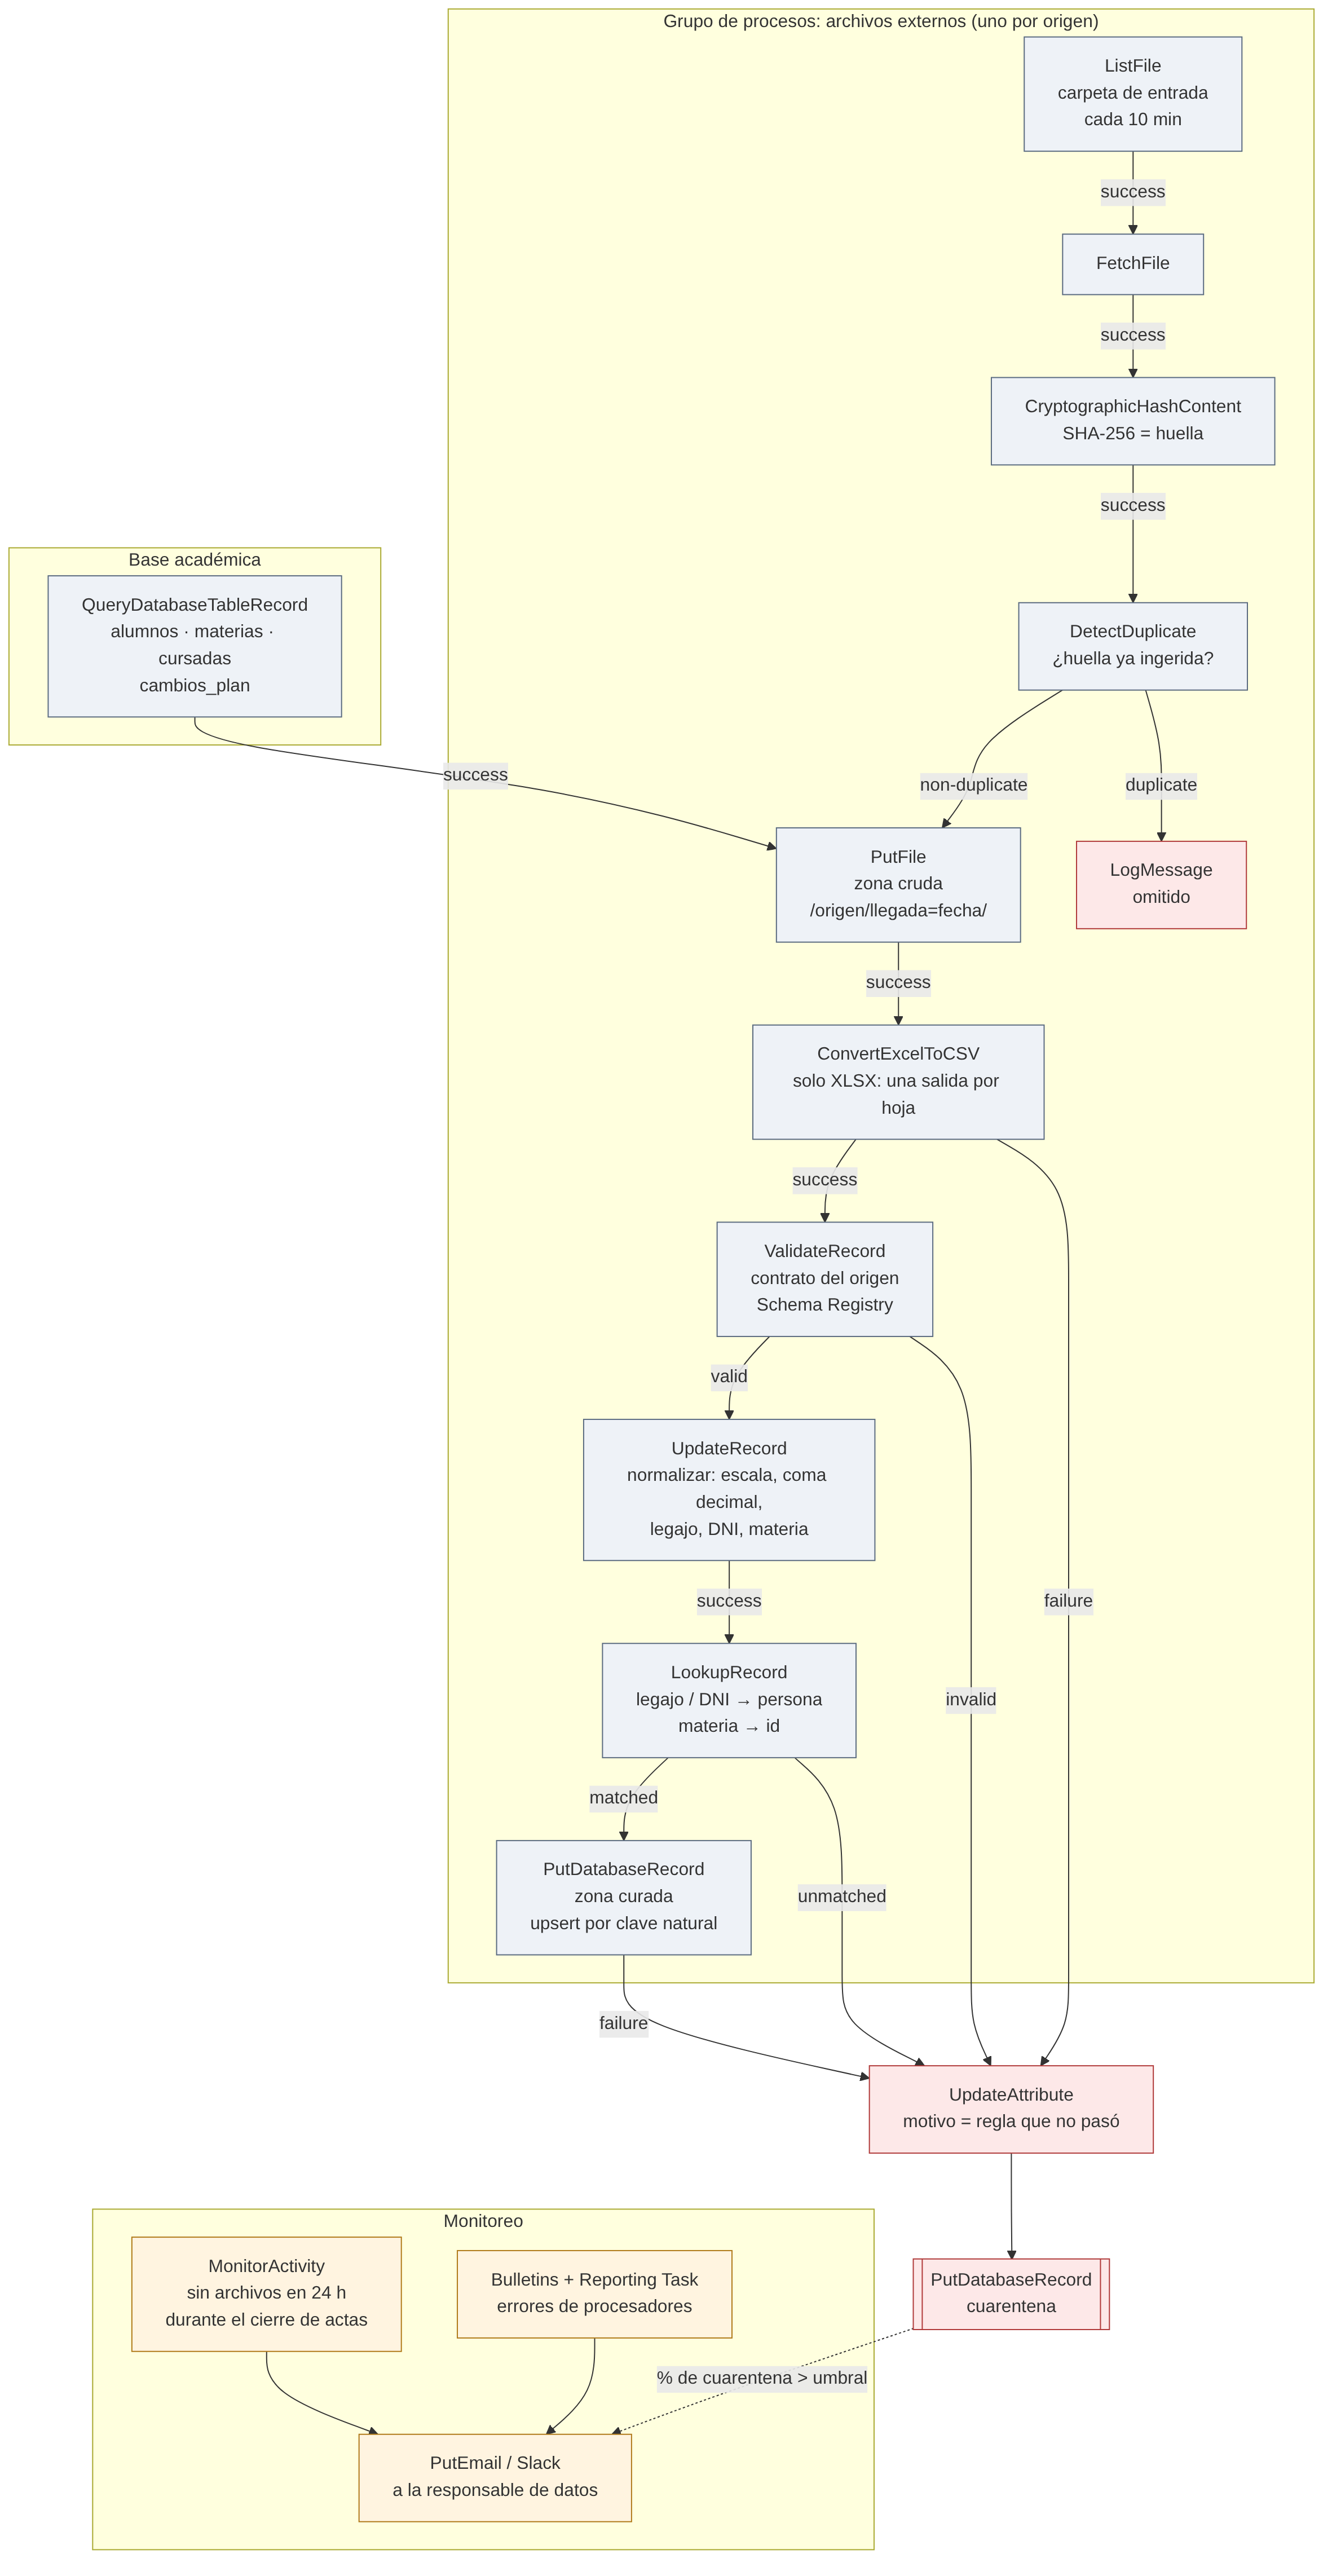

**El patrón es el mismo para los seis orígenes.** Cambia el contrato y la normalización de cada uno:
1. **Se lista y se toma el archivo**, y se le calcula una huella (SHA-256). Si esa huella ya se ingirió, se omite: reprocesar un archivo igual no hace nada.
2. **Se guarda tal cual en la zona cruda**, en una carpeta por fecha de llegada. Nunca se modifica.
3. **Se valida contra el contrato.**
   - Si se rompe la *forma* del archivo (columnas, hojas, encabezado), el archivo entero va a cuarentena y no entra ninguna fila.
   - Si fallan los *datos* de una fila (una nota fuera de rango, un DNI que no existe), va a cuarentena solo esa fila, con el motivo.
4. **Se normaliza y se cruza** con lo que ya está cargado: el legajo o el DNI pasan a persona, y el nombre de la materia a su id.
5. **Se carga en la zona curada** con un *upsert* por clave natural: si la fila ya existe se actualiza, y si no, se inserta. Todo el archivo entra en **una transacción**: o entra completo o no entra nada.
6. **Se controla el balance:** filas leídas = cargadas + cuarentena. Si no cierra, se revierte (es el control del módulo 1).

| Procesador en NiFi | En el script | Qué hace |
| --- | --- | --- |
| ListFile + FetchFile / QueryDatabaseTableRecord | `ingerir_todo()`, `extraer_base_academica()` | Toma cada origen; de la base académica saca una foto por tabla |
| CryptographicHashContent + DetectDuplicate | `huella()` y la consulta a `control_lote` | No reprocesa un archivo que ya entró igual |
| PutFile (zona cruda) | `shutil.copy2` a `lake/cruda/origen/llegada=fecha/` | Guarda el original tal cual |
| ConvertExcelToCSV | `pd.read_excel` hoja por hoja | Las actas traen una hoja por área |
| ValidateRecord + Schema Registry | `CONTRATO_*` y `exigir_columnas()` | La forma del archivo; si falla, `ContratoRoto` |
| UpdateRecord | la normalización de cada `procesar_*` | Escala, coma decimal, legajo, DNI, tildes |
| LookupRecord | `mapa()` y `cursada_de()` | Legajo o DNI → persona; materia → id; alumno + materia + cuatrimestre → cursada |
| relación *invalid* / *unmatched* / *failure* → PutDatabaseRecord | `filtrar()` y `a_cuarentena()` | Cada fila mala va a cuarentena con su motivo |
| PutDatabaseRecord | `INSERT ... ON CONFLICT DO UPDATE` | Upsert idempotente en la zona curada |
| MonitorActivity + Bulletins + PutEmail | `tablero_ingesta()` | Semáforo por origen y aviso a la responsable |

**Qué resuelve el contrato de cada origen** (los problemas son los del diagnóstico):

| Origen | Contrato y normalización | Va a cuarentena | Por qué reprocesar no duplica |
| --- | --- | --- | --- |
| Base académica | Personas y legajos: `cargar_dim_alumno` (módulo 3). Cursadas: el alumno se traduce a persona. | Cursadas de alumnos inexistentes (AL9xxxx) | Upsert por `id_cursada` |
| Biblioteca (JSONL) | Todo como texto, porque el ISBN no es un número. Si viene el legajo en vez del id, se traduce. Fecha y hora con formato fijo. | Alumno inexistente, ISBN inválido, fecha inválida | La clave es persona + ISBN + fecha y hora (`INSERT OR IGNORE`) |
| Notas (CSV) | **Dos versiones del contrato:** v1 (`id_alumno`, `nota`, escala 0–10) y v2 (`id_estudiante`, `calificacion`, escala 0–100). La escala sale del contrato, no de mirar los datos. El cuatrimestre sale del nombre del archivo. | Nota fuera de la escala, alumno o cursada inexistente | Upsert por `id_cursada`. **El CSV no pisa una nota que vino del acta.** |
| Actas (XLSX) | Título en A1, cuatrimestre en A2, encabezado en la fila 4. Al legajo se le agrega la «L» y se pasa a mayúscula. La coma decimal pasa a punto. «AUS» es ausente, sin nota. | Nota fuera de 0–10, legajo o materia inexistente | Upsert por `id_cursada`: el acta prevalece (supuesto S2) |
| Becas (CSV) | Al DNI se le sacan los puntos y se cruza contra `persona_pii`. Hay una lista cerrada de tipos de beca. | DNI que no es de ningún alumno, porcentaje o fecha inválidos | Upsert por persona + fecha desde |
| Encuesta (XLSX) | Título en A1 y encabezado en la fila 3. La materia se compara sin tildes («Matería» → «Materia»). | Puntaje fuera de 1–5, materia inexistente | Es anónima y no tiene clave: **se reemplaza la partición** (los cuatrimestres del archivo) |

| Campo | Contenido |
| --- | --- |
| Decisión | Validar contra un **contrato versionado** antes de cargar. Si se rompe la forma, el archivo entero va a cuarentena. Si fallan los datos de una fila, solo esa fila. |
| Restricción comprobable | Los archivos externos cambian de formato sin aviso: las notas de 2025-1c cambiaron de columnas y de escala. Además, hay errores de a una fila: 26 notas fuera de rango sobre 7.956. |
| Opción elegida y costo que se acepta | Contrato versionado más cuarentena en dos niveles. El costo: cada formato nuevo exige que alguien agregue una versión al contrato. Hasta que eso pase, ese archivo no se carga. |
| **Alternativa descartada y por qué** | **Inferir el esquema y la escala mirando los datos**, por ejemplo «si hay notas mayores a 10, la escala es 0–100». Un cuatrimestre con todas las notas bajas en escala 0–100 se cargaría como 0–10 sin que nadie se entere. También se descartó **rechazar el archivo entero por cualquier fila mala**: 26 notas fuera de rango frenarían 7.930 notas buenas. |
| Control que detecta el fallo y qué se hace cuando suena | El **semáforo del tablero de ingesta**. 🔴 si se rompió el contrato o no cerró el balance. 🟡 si más del 5 % de las filas fue a cuarentena. 🟢 si está todo bien. **Lo recibe la responsable de datos académicos.** Si es 🔴, actualiza el contrato o le pide al origen que reenvíe. Si es 🟡, revisa la cuarentena y decide: corregir y reprocesar, o aceptar y documentar. |

**Qué cambiaría la decisión:** si los orígenes publicaran su esquema en un registro compartido (Schema Registry), el contrato se tomaría de ahí y los cambios llegarían avisados.

### El marco común

Lo que se repite en todos los orígenes: huella, zona cruda, transacción, balance, cuarentena y registro del lote.

In [13]:
# ===== Marco común de ingestión: lo que en NiFi hacen ListFile, Hash, DetectDuplicate, PutFile y la cuarentena =====
import hashlib, unicodedata, datetime as dt

CRUDA = "lake/cruda"
zonas()                                            # crea lake/cruda, curada, variables y consumo

class ContratoRoto(Exception):
    """El archivo entero no cumple el contrato (columnas, hojas, encabezado): no se carga ninguna fila."""

def huella(ruta):
    return hashlib.sha256(open(ruta, "rb").read()).hexdigest()

def a_cuarentena(lote, fuente, filas, motivo):
    """Manda filas (un DataFrame) a cuarentena con su motivo. Devuelve cuántas mandó."""
    if len(filas) == 0:
        return 0
    registros = [(lote, fuente, json.dumps(f, ensure_ascii=False, default=str), motivo)
                 for f in filas.astype(object).where(filas.notna(), None).to_dict("records")]
    almacen.executemany("INSERT INTO cuarentena (id_lote, fuente, registro, motivo) VALUES (?, ?, ?, ?)", registros)
    return len(registros)

def ingerir(fuente, ruta, procesar, forzar=False):
    """Ingesta de un origen: huella → zona cruda → contrato y carga en una transacción → balance → registro del lote.
    procesar(ruta, lote) devuelve (leídas, cargadas, en_cuarentena, extra) o levanta ContratoRoto."""
    firma = huella(ruta)
    ya = uno("SELECT id_lote FROM control_lote WHERE fuente = ? AND huella = ? AND estado = 'ok'", (fuente, firma))
    if ya and not forzar:                                              # DetectDuplicate
        lote = abrir_lote("ingesta", fuente)
        almacen.execute("UPDATE control_lote SET huella = ? WHERE id_lote = ?", (firma, lote))
        cerrar_lote(lote, "omitido", detalle=f"mismo contenido que el lote {ya}: no se reprocesa")
        return {"fuente": fuente, "estado": "omitido", "detalle": f"igual al lote {ya}"}

    destino = os.path.join(CRUDA, fuente.split(".")[0], f"llegada={dt.date.today()}")
    os.makedirs(destino, exist_ok=True)
    shutil.copy2(ruta, destino)                                        # PutFile a la zona cruda, tal cual llegó

    lote = abrir_lote("ingesta", fuente)
    almacen.execute("UPDATE control_lote SET huella = ? WHERE id_lote = ?", (firma, lote))
    try:
        almacen.execute("BEGIN")
        leidas, cargadas, cuarentena, extra = procesar(ruta, lote)
        if leidas != cargadas + cuarentena:                            # el control del módulo 1
            raise CargaRechazada(f"balance: {leidas} leídas ≠ {cargadas} cargadas + {cuarentena} en cuarentena")
        almacen.execute("COMMIT")
        cerrar_lote(lote, "ok", leidas, cargadas, cuarentena, json.dumps(extra, ensure_ascii=False) if extra else None)
        return {"fuente": fuente, "estado": "ok", "leídas": leidas, "cargadas": cargadas, "cuarentena": cuarentena,
                "detalle": " · ".join(f"{k}: {v}" for k, v in (extra or {}).items())}
    except ContratoRoto as error:
        if almacen.in_transaction: almacen.execute("ROLLBACK")
        a_cuarentena(lote, fuente, pd.DataFrame([{"archivo": ruta, "huella": firma}]), f"contrato roto: {error}")
        cerrar_lote(lote, "falló", detalle=f"ContratoRoto: {error}")
        return {"fuente": fuente, "estado": "falló", "detalle": f"archivo entero a cuarentena: {error}"}
    except Exception as error:
        if almacen.in_transaction: almacen.execute("ROLLBACK")
        cerrar_lote(lote, "falló", detalle=f"{type(error).__name__}: {error}")
        return {"fuente": fuente, "estado": "falló", "detalle": f"{type(error).__name__}: {error}"}

def exigir_columnas(df, esperadas, donde):
    if list(df.columns) != list(esperadas):
        raise ContratoRoto(f"{donde}: columnas {list(df.columns)}, se esperaban {list(esperadas)}")

def sin_tildes(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", str(texto)) if not unicodedata.combining(c))

def mapa(consulta):
    """Diccionario clave → valor desde el almacén (para los Lookup)."""
    return dict(almacen.execute(consulta).fetchall())

### Un procesador por origen

Cada uno declara su contrato arriba de todo, normaliza, cruza contra lo que ya está cargado y deja en cuarentena lo que no pasa.

In [14]:
# ===== Un procesador por origen: contrato, normalización, lookup y carga =====
# Cada uno devuelve (leídas, cargadas, en_cuarentena, extra). Las filas que no pasan van a cuarentena con su motivo.

# --- Contratos: lo que esperamos de cada origen. Si cambia, se cambia acá y queda versionado en el repo. ---
CONTRATO_NOTAS = {                  # columnas exactas por versión → cómo se llaman en el modelo y en qué escala vienen
    "v1": {"columnas": ["id_alumno", "id_materia", "nota", "docente"], "renombrar": {}, "escala": 10},
    "v2": {"columnas": ["id_estudiante", "id_materia", "calificacion", "docente"],
           "renombrar": {"id_estudiante": "id_alumno", "calificacion": "nota"}, "escala": 100},
}
CONTRATO_ACTAS = {"titulo": "Acta de calificaciones", "fila_encabezado": 3,
                  "columnas": ["Legajo", "Materia", "Docente", "Condición", "Nota"], "escala": 10}
CONTRATO_BECAS = {"columnas": ["dni", "tipo_beca", "porcentaje", "desde"], "tipos": {"Necesidad", "Mérito", "Deporte"}}
CONTRATO_ENCUESTA = {"titulo": "Encuesta de satisfacción", "fila_encabezado": 2,
                     "columnas": ["Materia", "Cuatrimestre", "Puntaje", "Comentario"], "escala": (1, 5)}
CUATRIMESTRE = r"^\d{4}-[12]c$"

def filtrar(df, reglas, lote, fuente, columnas):
    """Aplica las reglas en orden. Cada regla es (función que marca las filas malas, motivo).
    Las filas malas van a cuarentena con su motivo y salen del DataFrame. Devuelve (buenas, cuántas a cuarentena)."""
    q = 0
    for regla, motivo in reglas:
        malas = regla(df)
        q += a_cuarentena(lote, fuente, df[malas][columnas], motivo)
        df = df[~malas]
    return df, q

def extraer_base_academica():
    """QueryDatabaseTableRecord: saca una foto de cada tabla de la base académica a un CSV de entrada."""
    carpeta = "lake/entrada/base_academica"; os.makedirs(carpeta, exist_ok=True)
    for tabla in ("alumnos", "materias", "cursadas", "cambios_plan"):
        sql(f"SELECT * FROM {tabla}").to_csv(f"{carpeta}/{tabla}.csv", index=False)
    return carpeta

def procesar_materias(ruta, lote):
    df = pd.read_csv(ruta, dtype=str)
    exigir_columnas(df, ["id_materia", "nombre", "carrera"], "materias")
    malas = df[df.id_materia.isna() | df.nombre.isna() | df.duplicated("id_materia", keep=False)]
    q = a_cuarentena(lote, "base_academica.materias", malas, "materia sin id/nombre o id repetido")
    buenas = df.drop(malas.index)
    almacen.executemany("""INSERT INTO materia VALUES (?, ?, ?) ON CONFLICT (id_materia) DO UPDATE
                           SET nombre = excluded.nombre, carrera = excluded.carrera""", buenas.values.tolist())
    return len(df), len(buenas), q, None

def procesar_cursadas(ruta, lote):
    df = pd.read_csv(ruta, dtype=str)
    exigir_columnas(df, ["id_cursada", "id_alumno", "id_materia", "cuatrimestre", "estado"], "cursadas")
    persona = mapa("SELECT id_alumno, id_persona FROM legajo")
    df["id_persona"] = df.id_alumno.map(persona)
    df, q = filtrar(df, [
        (lambda d: d.id_persona.isna(), "alumno inexistente en la base académica"),
        (lambda d: ~d.id_materia.isin(list(mapa("SELECT id_materia, 1 FROM materia"))), "materia inexistente"),
        (lambda d: ~d.cuatrimestre.str.match(CUATRIMESTRE, na=False), "cuatrimestre con formato inválido"),
        (lambda d: ~d.estado.isin(["aprobada", "desaprobada", "abandonó"]), "estado desconocido"),
    ], lote, "base_academica.cursadas", ["id_cursada", "id_alumno", "id_materia", "cuatrimestre", "estado"])
    rep = df.duplicated(["id_persona", "id_materia", "cuatrimestre"], keep="first")
    q += a_cuarentena(lote, "base_academica.cursadas", df[rep].drop(columns="id_persona"), "misma persona, materia y cuatrimestre repetida")
    df = df[~rep]
    almacen.executemany("""INSERT INTO cursada (id_cursada, id_persona, id_materia, cuatrimestre, estado) VALUES (?, ?, ?, ?, ?)
                           ON CONFLICT (id_cursada) DO UPDATE SET estado = excluded.estado""",
                        df[["id_cursada", "id_persona", "id_materia", "cuatrimestre", "estado"]].values.tolist())
    return len(pd.read_csv(ruta)), len(df), q, None

def procesar_biblioteca(ruta, lote):
    filas = [json.loads(l) for l in open(ruta, encoding="utf-8") if l.strip()]
    df = pd.DataFrame(filas, dtype=str)                       # todo como texto: el ISBN no es un número
    exigir_columnas(df[sorted(df.columns)], ["id_alumno", "isbn", "tipo", "ts"], "biblioteca")
    por_id, por_legajo = mapa("SELECT id_alumno, id_persona FROM legajo"), mapa("SELECT legajo, id_persona FROM legajo")
    df["id_persona"] = df.id_alumno.map(por_id).fillna(df.id_alumno.str.upper().map(por_legajo))   # a veces viene el legajo
    df["ts_ok"] = pd.to_datetime(df.ts, errors="coerce", format="%Y-%m-%dT%H:%M:%S")
    df, q = filtrar(df, [(lambda d: d.id_persona.isna(), "alumno o legajo inexistente"),
                         (lambda d: ~d.isbn.str.fullmatch(r"\d{13}", na=False), "ISBN inválido"),
                         (lambda d: d.ts_ok.isna(), "fecha y hora inválida"),
                         (lambda d: d.tipo != "prestamo", "tipo de evento desconocido")],
                    lote, "biblioteca", ["id_alumno", "isbn", "ts", "tipo"])
    antes = uno("SELECT COUNT(*) FROM prestamo")
    almacen.executemany("INSERT OR IGNORE INTO prestamo (id_persona, isbn, ts, id_lote) VALUES (?, ?, ?, ?)",
                        [(p, i, t, lote) for p, i, t in df[["id_persona", "isbn", "ts"]].values])
    nuevos = uno("SELECT COUNT(*) FROM prestamo") - antes
    return len(filas), len(df), q, {"nuevos": nuevos, "ya estaban": len(df) - nuevos,
                                    "por legajo": int(df.id_alumno.str.upper().str.startswith("L").sum())}

def cursada_de(df, cuatrimestre):
    """Lookup: (persona, materia, cuatrimestre) → id_cursada."""
    c = pd.read_sql_query("SELECT id_persona, id_materia, id_cursada FROM cursada WHERE cuatrimestre = ?", almacen, params=(cuatrimestre,))
    return df.merge(c, on=["id_persona", "id_materia"], how="left")

def procesar_notas(ruta, lote):
    cuatrimestre = re.search(r"notas_(\d{4}-[12]c)\.csv$", ruta)
    if not cuatrimestre: raise ContratoRoto(f"el nombre {os.path.basename(ruta)} no dice el cuatrimestre")
    cuatrimestre = cuatrimestre.group(1)
    df = pd.read_csv(ruta, dtype=str)
    version = next((v for v, c in CONTRATO_NOTAS.items() if list(df.columns) == c["columnas"]), None)
    if version is None:                                       # cambio de esquema que no conocemos: no se adivina
        raise ContratoRoto(f"columnas {list(df.columns)} no coinciden con ninguna versión del contrato {list(CONTRATO_NOTAS)}")
    c = CONTRATO_NOTAS[version]
    df = df.rename(columns=c["renombrar"])
    df["nota_num"] = pd.to_numeric(df.nota, errors="coerce")
    df["id_persona"] = df.id_alumno.map(mapa("SELECT id_alumno, id_persona FROM legajo"))
    df = cursada_de(df, cuatrimestre)
    df, q = filtrar(df, [(lambda d: d.nota_num.isna(), "nota no numérica"),
                         (lambda d: ~d.nota_num.between(0, c["escala"]), f"nota fuera de rango (0 a {c['escala']})"),
                         (lambda d: d.id_persona.isna(), "alumno inexistente"),
                         (lambda d: d.id_cursada.isna(), f"no hay cursada de ese alumno y materia en {cuatrimestre}")],
                    lote, f"notas_{cuatrimestre}", ["id_alumno", "id_materia", "nota", "docente"])
    df["nota_10"] = (df.nota_num * 10 / c["escala"]).round(2)  # normalizada a 0–10 según el contrato, no según los datos
    # El CSV no pisa una nota que ya vino del acta (el acta es la fuente de verdad, supuesto S2).
    almacen.executemany("""INSERT INTO nota (id_cursada, nota, ausente, docente, fuente_nota, id_lote) VALUES (?, ?, 0, ?, 'csv', ?)
                           ON CONFLICT (id_cursada) DO UPDATE SET nota = excluded.nota, docente = excluded.docente,
                           id_lote = excluded.id_lote WHERE nota.fuente_nota = 'csv'""",
                        [(i, n, d, lote) for i, n, d in df[["id_cursada", "nota_10", "docente"]].values])
    return len(pd.read_csv(ruta)), len(df), q, {"versión del contrato": version, "escala": c["escala"]}

def procesar_actas(ruta, lote):
    libro = pd.ExcelFile(ruta); leidas = cargadas = q = 0; difieren = ausentes = 0
    materia = mapa("SELECT nombre, id_materia FROM materia"); legajo = mapa("SELECT legajo, id_persona FROM legajo")
    for hoja in libro.sheet_names:                                   # ConvertExcelToCSV: una salida por hoja
        cabecera = pd.read_excel(ruta, sheet_name=hoja, header=None, nrows=2)
        titulo, cuat = str(cabecera.iloc[0, 0]), re.search(r"(\d{4}-[12]c)", str(cabecera.iloc[1, 0]))
        if not titulo.startswith(CONTRATO_ACTAS["titulo"]) or not cuat:
            raise ContratoRoto(f"hoja «{hoja}»: no tiene el título o el cuatrimestre en A1/A2")
        df = pd.read_excel(ruta, sheet_name=hoja, header=CONTRATO_ACTAS["fila_encabezado"], dtype=str)
        exigir_columnas(df, CONTRATO_ACTAS["columnas"], f"hoja «{hoja}»")
        leidas += len(df); cuat = cuat.group(1)
        leg = df.Legajo.str.strip().str.upper()
        df["legajo_n"] = leg.where(leg.str.startswith("L"), "L" + leg)              # «21464» y «l20849» → «L21464», «L20849»
        df["ausente"] = (df.Nota.str.strip().str.upper() == "AUS").astype(int)
        df["nota_num"] = pd.to_numeric(df.Nota.str.replace(",", ".", regex=False), errors="coerce")   # «7,0» → 7.0
        df["id_persona"], df["id_materia"] = df.legajo_n.map(legajo), df.Materia.map(materia)
        df = cursada_de(df, cuat)
        df, malas = filtrar(df, [(lambda d: (d.ausente == 0) & d.nota_num.isna(), "nota no numérica"),
                                 (lambda d: (d.ausente == 0) & ~d.nota_num.between(0, 10), "nota fuera de rango (0 a 10)"),
                                 (lambda d: d.id_persona.isna(), "legajo inexistente"),
                                 (lambda d: d.id_materia.isna(), "materia inexistente"),
                                 (lambda d: d.id_cursada.isna(), f"no hay cursada de ese alumno y materia en {cuat}")],
                            lote, f"actas_docentes.{hoja}", CONTRATO_ACTAS["columnas"])
        q += malas
        # Control cruzado con el CSV: ¿el acta dice lo mismo que la nota que ya teníamos?
        previa = pd.read_sql_query("SELECT id_cursada, nota AS nota_csv FROM nota WHERE fuente_nota = 'csv'", almacen)
        cruce = df.merge(previa, on="id_cursada")
        difieren += int(((cruce.ausente == 1) | ((cruce.nota_num - cruce.nota_csv).abs() > 0.001)).sum())
        ausentes += int(df.ausente.sum())
        almacen.executemany("""INSERT INTO nota (id_cursada, nota, ausente, docente, condicion, fuente_nota, id_lote)
                               VALUES (?, ?, ?, ?, ?, 'acta', ?)
                               ON CONFLICT (id_cursada) DO UPDATE SET nota = excluded.nota, ausente = excluded.ausente,
                               docente = excluded.docente, condicion = excluded.condicion, fuente_nota = 'acta', id_lote = excluded.id_lote""",
                            [(i, None if a else n, int(a), d, cond, lote)
                             for i, n, a, d, cond in df[["id_cursada", "nota_num", "ausente", "Docente", "Condición"]].values])
        cargadas += len(df)
    return leidas, cargadas, q, {"ausentes": ausentes, "difieren del CSV": difieren}

def procesar_becas(ruta, lote):
    df = pd.read_csv(ruta, dtype=str)
    exigir_columnas(df, CONTRATO_BECAS["columnas"], "becas")
    df["dni_n"] = df.dni.str.replace(".", "", regex=False).str.strip()          # «35.527.738» → «35527738»
    df["id_persona"] = df.dni_n.map(mapa("SELECT dni, id_persona FROM persona_pii"))
    df["pct"] = pd.to_numeric(df.porcentaje, errors="coerce")
    df, q = filtrar(df, [(lambda d: ~d.dni_n.str.fullmatch(r"\d{8}", na=False), "DNI inválido"),
                         (lambda d: d.id_persona.isna(), "DNI que no es de ningún alumno"),
                         (lambda d: ~d.pct.between(1, 100), "porcentaje fuera de 1 a 100"),
                         (lambda d: pd.to_datetime(d.desde, errors="coerce", format="%Y-%m-%d").isna(), "fecha inválida"),
                         (lambda d: ~d.tipo_beca.isin(CONTRATO_BECAS["tipos"]), "tipo de beca desconocido")],
                    lote, "becas", CONTRATO_BECAS["columnas"])
    almacen.executemany("""INSERT INTO beca VALUES (?, ?, ?, ?) ON CONFLICT (id_persona, desde)
                           DO UPDATE SET tipo_beca = excluded.tipo_beca, porcentaje = excluded.porcentaje""",
                        [(p, t, int(x), d) for p, t, x, d in df[["id_persona", "tipo_beca", "pct", "desde"]].values])
    return len(pd.read_csv(ruta)), len(df), q, {"DNI con puntos": int(pd.read_csv(ruta, dtype=str).dni.str.contains(r"\.").sum())}

def procesar_encuesta(ruta, lote):
    titulo = str(pd.read_excel(ruta, header=None, nrows=1).iloc[0, 0])
    if not titulo.startswith(CONTRATO_ENCUESTA["titulo"]): raise ContratoRoto("no tiene el título esperado en A1")
    df = pd.read_excel(ruta, header=CONTRATO_ENCUESTA["fila_encabezado"], dtype=str)
    exigir_columnas(df, CONTRATO_ENCUESTA["columnas"], "encuesta")
    materia = {sin_tildes(k): v for k, v in mapa("SELECT nombre, id_materia FROM materia").items()}
    df["id_materia"] = df.Materia.map(lambda m: materia.get(sin_tildes(m)))             # «Matería 11» → MT011
    df["puntaje"] = pd.to_numeric(df.Puntaje, errors="coerce")
    lo, hi = CONTRATO_ENCUESTA["escala"]
    df, q = filtrar(df, [(lambda d: d.id_materia.isna(), "materia inexistente"),
                         (lambda d: ~d.Cuatrimestre.str.match(CUATRIMESTRE, na=False), "cuatrimestre inválido"),
                         (lambda d: ~d.puntaje.between(lo, hi), f"puntaje fuera de {lo} a {hi}")],
                    lote, "encuesta", CONTRATO_ENCUESTA["columnas"])
    # Es anónima: no hay clave natural. Se reemplaza la partición (los cuatrimestres del archivo) entera: reprocesar no duplica.
    for cuat in df.Cuatrimestre.unique():
        almacen.execute("DELETE FROM respuesta_encuesta WHERE cuatrimestre = ?", (cuat,))
    almacen.executemany("INSERT INTO respuesta_encuesta (id_materia, cuatrimestre, puntaje, comentario) VALUES (?, ?, ?, ?)",
                        [(m, c, int(p), None if pd.isna(t) else t) for m, c, p, t in df[["id_materia", "Cuatrimestre", "puntaje", "Comentario"]].values])
    return len(pd.read_excel(ruta, header=CONTRATO_ENCUESTA["fila_encabezado"])), len(df), q, \
           {"materia corregida (tilde)": int((df.Materia != df.Materia.map(sin_tildes)).sum())}

### Correr la ingestión

In [15]:
# El flujo completo, en el orden en que dependen unos de otros:
# primero la base académica (personas, materias, cursadas) porque todo lo demás se cruza contra ella.
# Las personas y los legajos ya los cargó cargar_dim_alumno (módulo 3), que es el paso de «alumnos + cambios_plan».
def ingerir_todo(forzar=False):
    base = extraer_base_academica()
    E = EXTERNOS
    pasos = [("base_academica.materias", f"{base}/materias.csv",           procesar_materias),
             ("base_academica.cursadas", f"{base}/cursadas.csv",           procesar_cursadas),
             ("biblioteca",              f"{DESTINO}/eventos/biblioteca.jsonl", procesar_biblioteca),
             ("notas_2024-2c",           f"{E}/notas_2024-2c.csv",         procesar_notas),
             ("notas_2025-1c",           f"{E}/notas_2025-1c.csv",         procesar_notas),
             ("actas_docentes",          f"{E}/actas_docentes.xlsx",       procesar_actas),   # después de las notas: el acta prevalece
             ("becas",                   f"{E}/becas.csv",                 procesar_becas),
             ("encuesta",                f"{E}/encuesta_satisfaccion.xlsx", procesar_encuesta)]
    return pd.DataFrame([ingerir(fuente, ruta, procesar, forzar) for fuente, ruta, procesar in pasos])

ingesta = ingerir_todo()
ingesta

,fuente,estado,leídas,cargadas,cuarentena,detalle
0,base_academica.materias,ok,40,40,0,
1,base_academica.cursadas,ok,15315,15290,25,
2,biblioteca,ok,10946,10946,0,nuevos: 10946 · ya estaban: 0 · por legajo: 1126
3,notas_2024-2c,ok,7956,7930,26,versión del contrato: v1 · escala: 10
4,notas_2025-1c,ok,7334,7302,32,versión del contrato: v2 · escala: 100
5,actas_docentes,ok,1500,1490,10,ausentes: 45 · difieren del CSV: 45
6,becas,ok,320,300,20,DNI con puntos: 94
7,encuesta,ok,800,785,15,materia corregida (tilde): 44


### Monitoreo

In [16]:
# Monitoreo: el último lote de cada origen, con su balance y un semáforo.
UMBRAL_CUARENTENA = 0.05     # más de 5 % de filas en cuarentena es una alerta: algo cambió en el origen

def tablero_ingesta():
    t = sql("""SELECT fuente, id_lote, estado, filas_leidas, filas_cargadas, filas_cuarentena, detalle
               FROM control_lote WHERE proceso = 'ingesta'
                 AND id_lote IN (SELECT MAX(id_lote) FROM control_lote WHERE proceso = 'ingesta' AND estado <> 'omitido' GROUP BY fuente)
               ORDER BY id_lote""", base="dwh.db")
    t["% cuarentena"] = (100 * t.filas_cuarentena / t.filas_leidas).round(1)
    t["balance"] = (t.filas_leidas == t.filas_cargadas + t.filas_cuarentena).map({True: "cierra", False: "NO cierra"})
    t["semáforo"] = [ "🔴 falló" if e == "falló" else ("🟡 revisar" if p > 100 * UMBRAL_CUARENTENA else "🟢 ok")
                      for e, p in zip(t.estado, t["% cuarentena"].fillna(0))]
    return t.astype({"filas_leidas": "Int64", "filas_cargadas": "Int64", "filas_cuarentena": "Int64"})

display(tablero_ingesta().drop(columns="detalle"))
print("Qué hay en cuarentena y por qué:")
sql("""SELECT fuente, motivo, COUNT(*) AS filas FROM cuarentena
       WHERE id_lote IN (SELECT MAX(id_lote) FROM control_lote WHERE proceso = 'ingesta' AND estado <> 'omitido' GROUP BY fuente)
       GROUP BY fuente, motivo ORDER BY fuente, filas DESC""", base="dwh.db")

,fuente,id_lote,estado,filas_leidas,filas_cargadas,filas_cuarentena,% cuarentena,balance,semáforo
0,base_academica.materias,5,ok,40,40,0,0.000,cierra,🟢 ok
1,base_academica.cursadas,6,ok,15315,15290,25,0.200,cierra,🟢 ok
2,biblioteca,7,ok,10946,10946,0,0.000,cierra,🟢 ok
3,notas_2024-2c,8,ok,7956,7930,26,0.300,cierra,🟢 ok
4,notas_2025-1c,9,ok,7334,7302,32,0.400,cierra,🟢 ok
5,actas_docentes,10,ok,1500,1490,10,0.700,cierra,🟢 ok
6,becas,11,ok,320,300,20,6.200,cierra,🟡 revisar
7,encuesta,12,ok,800,785,15,1.900,cierra,🟢 ok


Qué hay en cuarentena y por qué:


,fuente,motivo,filas
0,actas_docentes.Ciencias,nota fuera de rango (0 a 10),5
1,actas_docentes.Gestión,nota fuera de rango (0 a 10),1
2,actas_docentes.Humanidades,nota fuera de rango (0 a 10),4
3,base_academica.cursadas,alumno inexistente en la base académica,25
4,becas,DNI que no es de ningún alumno,20
5,encuesta,puntaje fuera de 1 a 5,15
6,notas_2024-2c,nota fuera de rango (0 a 10),26
7,notas_2025-1c,nota fuera de rango (0 a 100),32


**Qué muestra la ingestión:**
- **Todos los orígenes cierran el balance.** Cada fila leída está cargada o en cuarentena con su motivo: no se pierde ninguna.
- **Lo que fue a cuarentena coincide con el diagnóstico:**
  - las notas fuera de rango de los dos CSV y de las actas;
  - las 25 cursadas de alumnos inexistentes;
  - los 20 DNI de becas que no son de ningún alumno;
  - los 15 puntajes de encuesta fuera de escala.
- **Los problemas que tenían arreglo se arreglaron sin cuarentena:**
  - los 1.126 préstamos identificados por legajo;
  - los legajos sin «L» de las actas y los 45 ausentes;
  - los 94 DNI con puntos;
  - las 44 respuestas válidas con «Matería».
- **Becas queda en 🟡:** el 6,2 % de las filas fue a cuarentena. Es el caso que el semáforo tiene que mostrar. ¿Son becas de personas que todavía no se inscribieron, o un error del área de becas? El caso no lo dice: lo decide la responsable de datos académicos, no la carga.
- **En los 45 ausentes, el acta y el CSV no coinciden:** el CSV trae una nota donde el acta dice «AUS». Vale el acta (supuesto S2), y la diferencia queda registrada en el lote para revisarla.

### Pruebas de los casos difíciles

1. **Idempotencia:** con los mismos archivos, una segunda corrida no hace nada.
2. **Reproceso forzado:** aunque se recargue todo, no se duplica ninguna fila y el CSV no pisa las notas del acta.
3. **Cambio de esquema sin aviso:** llega un archivo de notas con columnas que ninguna versión del contrato conoce.

In [17]:
# Prueba 1 · Idempotencia: correr todo otra vez. Como los archivos no cambiaron, cada origen se omite.
print("1) Segunda corrida con los mismos archivos:")
display(ingerir_todo()[["fuente", "estado", "detalle"]])

# Prueba 2 · Reproceso forzado: aunque se vuelva a cargar todo, no se duplica nada
#           y el CSV no pisa las notas que vinieron del acta.
foto = lambda: {t: uno(f"SELECT COUNT(*) FROM {t}") for t in ("cursada", "nota", "prestamo", "beca", "respuesta_encuesta")} | \
               {"notas del acta": uno("SELECT COUNT(*) FROM nota WHERE fuente_nota = 'acta'")}
antes = foto(); ingerir_todo(forzar=True); despues = foto()
print("2) Reproceso forzado de todos los orígenes:")
display(pd.DataFrame({"antes": antes, "después": despues}).assign(igual=lambda d: d.antes == d.después))

# Prueba 3 · Cambio de esquema sin aviso: llega un archivo de notas con columnas nuevas.
#           No se adivina: el archivo entero va a cuarentena y no entra ninguna fila.
os.makedirs("lake/pruebas", exist_ok=True)
nuevo = leer_externo("notas_2025-1c.csv").rename(columns={"id_estudiante": "legajo", "calificacion": "nota_final"}).head(50)
nuevo.to_csv("lake/pruebas/notas_2025-2c.csv", index=False)
notas_antes = uno("SELECT COUNT(*) FROM nota")
r = ingerir("notas_2025-2c", "lake/pruebas/notas_2025-2c.csv", procesar_notas)
print("3) Archivo con columnas nuevas →", r["estado"], "·", r["detalle"])
print(f"   Notas antes / después: {notas_antes} / {uno('SELECT COUNT(*) FROM nota')} · "
      f"en cuarentena: {uno('SELECT COUNT(*) FROM cuarentena WHERE fuente = ?', ('notas_2025-2c',))} registro (el archivo)")

1) Segunda corrida con los mismos archivos:


,fuente,estado,detalle
0,base_academica.materias,omitido,igual al lote 5
1,base_academica.cursadas,omitido,igual al lote 6
2,biblioteca,omitido,igual al lote 7
3,notas_2024-2c,omitido,igual al lote 8
4,notas_2025-1c,omitido,igual al lote 9
5,actas_docentes,omitido,igual al lote 10
6,becas,omitido,igual al lote 11
7,encuesta,omitido,igual al lote 12


2) Reproceso forzado de todos los orígenes:


,antes,después,igual
cursada,15290,15290,True
nota,15232,15232,True
prestamo,10946,10946,True
beca,300,300,True
respuesta_encuesta,785,785,True
notas del acta,1490,1490,True


3) Archivo con columnas nuevas → falló · archivo entero a cuarentena: columnas ['legajo', 'id_materia', 'nota_final', 'docente'] no coinciden con ninguna versión del contrato ['v1', 'v2']
   Notas antes / después: 15232 / 15232 · en cuarentena: 1 registro (el archivo)


## 5 · Orquestación

El DAG junta todo lo anterior en una corrida: extrae la base académica, actualiza la dimensión alumno, ingiere los orígenes, publica el modelo estrella y avisa. En el notebook corre con `correr_dag(...)`. Al final está cómo se escribiría en Airflow.

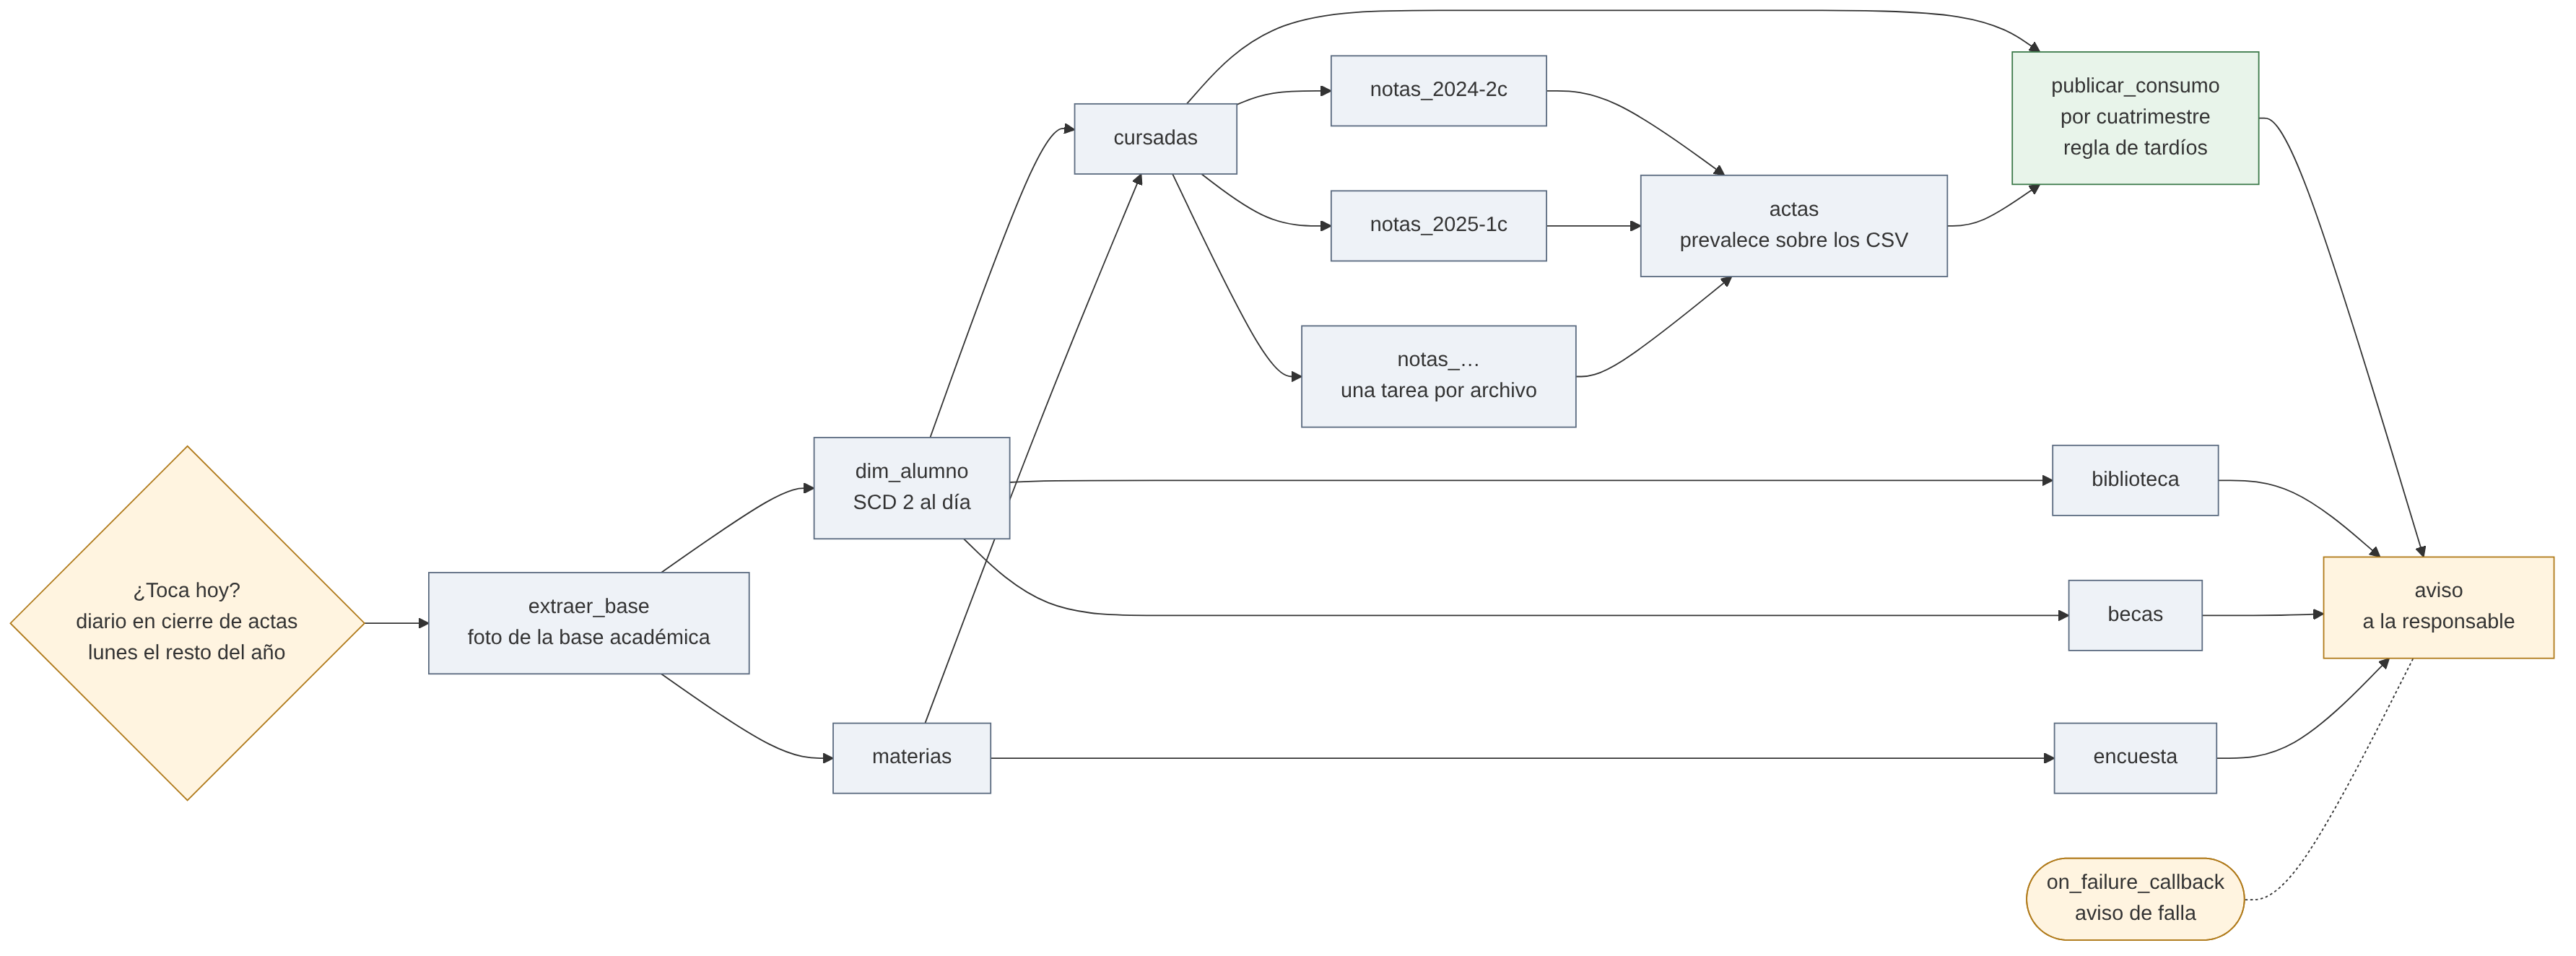

**Por qué las dependencias van en ese orden:**
- **`dim_alumno` va antes que cursadas, biblioteca y becas.** Las tres se traducen a persona, así que la persona tiene que existir.
- **Las notas cuelgan de las cursadas,** porque cada nota se asigna a una cursada.
- **Las notas se descubren en la carpeta:** hay una tarea por archivo. Si llega `notas_2025-2c.csv`, aparece una tarea nueva sin tocar el código. En Airflow esto se llama *dynamic task mapping*.
- **Las actas van después de todos los CSV de notas,** porque prevalecen sobre ellos. Si corrieran en paralelo, el resultado dependería de cuál termina último.
- **`publicar_consumo` espera a cursadas y actas.** Biblioteca, becas y encuesta no alimentan el hecho, así que corren en paralelo y no lo frenan.

| Campo | Decisión 1: calendario | Decisión 2: reintentos e idempotencia | Decisión 3: datos que llegan tarde |
| --- | --- | --- | --- |
| Restricción comprobable | Diario durante el cierre de actas y semanal el resto del año (consigna). | La base académica puede no responder. Un archivo puede llegar roto. Y el DAG puede correr varias veces sobre los mismos datos. | Las actas se rectifican después del cierre. En los datos, un acta de 2025-1c trae 45 ausentes donde el CSV traía nota. |
| Opción elegida y costo que se acepta | **El DAG corre todos los días y la primera tarea decide si sigue** (`ShortCircuitOperator`). Costo: 365 corridas que arrancan, de las que más de la mitad termina enseguida. | **Reintentos solo para las fallas transitorias.** Las permanentes (contrato roto, control que no pasa) fallan una vez y avisan. Cada tarea es idempotente: huella, upsert y SCD 2 incremental. Costo: hay que clasificar cada error. | **Un cuatrimestre queda abierto hasta 60 días después de su fin.** Mientras está abierto, cada corrida reconstruye su partición del hecho. Cuando cierra, no se toca. Si llega un cambio, hay **alerta y una persona decide reabrirlo**. Costo: una rectificación tardía espera a que alguien la apruebe. |
| **Alternativa descartada y por qué** | **Dos DAGs, uno diario y otro semanal.** Pueden correr a la vez sobre las mismas tablas y duplican la lógica. **Un *timetable* a medida en Airflow** resuelve lo mismo, pero es código más difícil de mantener para un equipo chico. | **Reintentar todo por igual.** Un archivo con columnas desconocidas falla igual en el tercer intento, y entre tanto demora el aviso. | **Aplicar siempre lo último que llega.** Un número que ya se informó (la tasa de aprobación de 2024-2c) cambiaría sin que nadie se entere. **Ignorar lo tardío** dejaría el hecho en desacuerdo con la zona curada para siempre. |
| Control y quién decide | La tabla de corridas por mes de abajo: tienen que salir 123 días de cierre y 35 lunes. | El aviso de falla (`on_failure_callback`): la zona consumo sigue con la última publicación buena. **Decide la responsable de datos académicos.** | La huella de cada partición, en `control_particion`: si la zona curada cambió después de publicar, salta la alerta. **Reabre la responsable de datos académicos**, después de revisar la rectificación. |

**Qué cambiaría las decisiones.**
- Si se necesitara la alerta de abandono en el día en que pasa algo, el calendario dejaría de servir. Haría falta disparar por evento (un sensor que corra el DAG cuando llega el archivo).
- Si la universidad publicara un calendario académico con fechas exactas de cierre, la ventana de 60 días se reemplazaría por esas fechas.

**Supuestos nuevos**

| # | Supuesto | Por qué |
| --- | --- | --- |
| S13 | El cierre de actas va del 1/7 al 15/8 en el primer cuatrimestre, y del 1/12 al 15/2 en el segundo (incluye las mesas de febrero). | El caso no da fechas. Cubre las últimas semanas de cursada y la carga de notas posterior. |
| S14 | Un cuatrimestre queda abierto hasta 60 días después de su fin. Después, cambiarlo requiere aprobación. | Da tiempo a las rectificaciones normales y deja fijos los indicadores ya informados. |
| S15 | La corrida semanal es los lunes. | Así los tableros quedan actualizados al empezar la semana. |

<details>
<summary><b>Cómo se vería en Airflow</b> (referencia, no se ejecuta acá)</summary>

```python
from datetime import date, datetime, timedelta
from airflow import DAG
from airflow.operators.python import PythonOperator, ShortCircuitOperator
from airflow.exceptions import AirflowFailException      # falla permanente: no se reintenta

default_args = {
    "owner": "datos_academicos",
    "retries": 3, "retry_delay": timedelta(minutes=5), "retry_exponential_backoff": True,   # solo para las transitorias
    "on_failure_callback": avisar_falla,
}

with DAG("uniandina_academico", start_date=datetime(2025, 3, 1), schedule="0 6 * * *",   # todos los días a las 6
         catchup=False, max_active_runs=1,                  # nunca dos corridas a la vez sobre el mismo almacén
         params={"reabrir": []},                            # la responsable lo completa al disparar a mano
         default_args=default_args) as dag:

    toca_hoy = ShortCircuitOperator(task_id="toca_hoy",
                                    python_callable=lambda ds, **_: debe_correr(date.fromisoformat(ds))[0])
    extraer = PythonOperator(task_id="extraer_base", python_callable=extraer_base_academica)
    dim_alumno = PythonOperator(task_id="dim_alumno", python_callable=cargar_dim_alumno, op_kwargs={"corte": "{{ ds }}"})
    materias = PythonOperator(task_id="materias", python_callable=ingerir_materias)
    cursadas = PythonOperator(task_id="cursadas", python_callable=ingerir_cursadas)
    biblioteca, becas, encuesta = (PythonOperator(task_id=t, python_callable=f) for t, f in
                                   [("biblioteca", ingerir_biblioteca), ("becas", ingerir_becas), ("encuesta", ingerir_encuesta)])
    notas = PythonOperator.partial(task_id="notas", python_callable=ingerir_notas).expand(op_args=listar_archivos_de_notas())
    actas = PythonOperator(task_id="actas", python_callable=ingerir_actas)
    publicar = PythonOperator(task_id="publicar_consumo", python_callable=publicar_consumo,
                              op_kwargs={"fecha_logica": "{{ ds }}", "reabrir": "{{ params.reabrir }}"})
    aviso = PythonOperator(task_id="aviso", python_callable=avisar, trigger_rule="all_done")   # corre aunque algo falle

    toca_hoy >> extraer >> [dim_alumno, materias]
    [dim_alumno, materias] >> cursadas >> notas >> actas >> publicar
    dim_alumno >> [biblioteca, becas]
    materias >> encuesta
    [publicar, biblioteca, becas, encuesta] >> aviso
```

En Airflow, la tarea `aviso` lleva `trigger_rule="all_done"`, así que corre aunque haya fallado algo. El `correr_dag` del notebook no tiene reglas de disparo: por eso el aviso de falla va por fuera, como un *callback*.
</details>

### El calendario

In [18]:
# ===== Calendario: diario durante el cierre de actas, semanal (los lunes) el resto del año =====
# En Airflow, el DAG corre todos los días y la primera tarea decide si sigue o se saltea (ShortCircuitOperator).
CIERRE_DE_ACTAS = [((7, 1), (8, 15)),     # 1er cuatrimestre: del 1/7 al 15/8 (supuesto S13)
                   ((12, 1), (2, 15))]    # 2do cuatrimestre: del 1/12 al 15/2, cruza el año (incluye las mesas de febrero)
DIA_SEMANAL = 0                           # lunes (supuesto S15)

def en_cierre_de_actas(fecha):
    md = (fecha.month, fecha.day)
    for desde, hasta in CIERRE_DE_ACTAS:
        if (desde <= md <= hasta) if desde <= hasta else (md >= desde or md <= hasta):
            return True
    return False

def debe_correr(fecha):
    """¿Corre el DAG en esta fecha lógica? Devuelve (sí/no, por qué)."""
    if en_cierre_de_actas(fecha):
        return True, "cierre de actas: diario"
    if fecha.weekday() == DIA_SEMANAL:
        return True, "resto del año: semanal (lunes)"
    return False, "se saltea"

# ¿Cuántas veces corre en un año? Se cuenta día por día de 2025.
dias = pd.DataFrame({"fecha": pd.date_range("2025-01-01", "2025-12-31")})
dias["corre"], dias["motivo"] = zip(*[debe_correr(f.date()) for f in dias.fecha])
corridas_por_mes = dias.groupby(dias.fecha.dt.month).agg(dias_del_mes=("corre", "size"), corridas=("corre", "sum"))
corridas_por_mes.index = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
print(f"En 2025 el DAG corre {dias.corre.sum()} días de 365: "
      f"{(dias.motivo == 'cierre de actas: diario').sum()} en cierre de actas y {(dias.motivo == 'resto del año: semanal (lunes)').sum()} lunes del resto del año.")
corridas_por_mes.T

En 2025 el DAG corre 158 días de 365: 123 en cierre de actas y 35 lunes del resto del año.


,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
dias_del_mes,31,28,31,30,31,30,31,31,30,31,30,31
corridas,31,17,5,4,4,5,31,17,5,4,4,31


### Publicar la zona consumo

Las dimensiones se actualizan con *upsert*. El hecho se publica **por partición**: borra y vuelve a cargar el cuatrimestre entero dentro de una transacción. Por eso reprocesar no duplica. La regla de los datos tardíos decide qué particiones se tocan.

In [19]:
# ===== Publicar la zona consumo: dimensiones y hecho, por partición (cuatrimestre) =====
# Política de datos tardíos (supuesto S14): un cuatrimestre queda «abierto» hasta 60 días después de su fin.
# - Abierto: cada corrida reconstruye su partición del hecho con lo que haya en la zona curada (los tardíos entran solos).
# - Cerrado: no se toca. Si la zona curada cambió después de publicarlo (llegó una rectificación), se da una alerta y la
#   partición solo se reconstruye si la responsable la reabre explícitamente.
DIAS_ABIERTO = 60

def cuatrimestre_fechas(cuat):
    anio, n = int(cuat[:4]), int(cuat[5])
    return (f"{anio}-03-01", f"{anio}-07-31") if n == 1 else (f"{anio}-08-01", f"{anio}-12-31")   # supuesto S8

def huella_particion(cuat):
    """Huella de lo que hay en la zona curada para un cuatrimestre: si cambia una nota o un estado, cambia la huella."""
    filas = almacen.execute("""SELECT c.id_cursada, c.id_persona, c.id_materia, c.estado,
                                      COALESCE(n.nota, ''), COALESCE(n.ausente, ''), COALESCE(n.fuente_nota, '')
                               FROM cursada c LEFT JOIN nota n USING (id_cursada)
                               WHERE c.cuatrimestre = ? ORDER BY c.id_cursada""", (cuat,)).fetchall()
    return hashlib.sha256(repr(filas).encode()).hexdigest(), len(filas)

PUBLICAR_DIMENSIONES = """
INSERT INTO dim_materia (id_materia, nombre, carrera) SELECT id_materia, nombre, carrera FROM materia WHERE true
ON CONFLICT (id_materia) DO UPDATE SET nombre = excluded.nombre, carrera = excluded.carrera;
"""

PUBLICAR_PARTICION = """
DELETE FROM hecho_cursada WHERE sk_tiempo = (SELECT sk_tiempo FROM dim_tiempo WHERE cuatrimestre = :cuat);
INSERT INTO hecho_cursada (id_cursada, sk_alumno, sk_materia, sk_tiempo, estado, nota, aprobada, ausente, fuente_nota, id_lote)
SELECT c.id_cursada, d.sk_alumno, m.sk_materia, t.sk_tiempo, c.estado, n.nota,
       CASE WHEN c.estado = 'aprobada' THEN 1 ELSE 0 END,           -- el estado lo define la base académica (decisión 10)
       COALESCE(n.ausente, 0), COALESCE(n.fuente_nota, 'sin nota'), :lote
FROM cursada c
JOIN dim_tiempo  t ON t.cuatrimestre = c.cuatrimestre
JOIN dim_materia m ON m.id_materia = c.id_materia
JOIN dim_alumno  d ON d.id_persona = c.id_persona                     -- la versión vigente al inicio del cuatrimestre (S9)
                  AND t.fecha_inicio >= d.valido_desde AND t.fecha_inicio < d.valido_hasta
LEFT JOIN nota n ON n.id_cursada = c.id_cursada
WHERE c.cuatrimestre = :cuat;
"""

def publicar_consumo(fecha_logica, reabrir=()):
    lote = abrir_lote("publicar_consumo", f"zona curada al {fecha_logica}")
    try:
        almacen.execute("BEGIN")
        ejecutar(PUBLICAR_DIMENSIONES, {})
        decisiones = []
        for (cuat,) in almacen.execute("SELECT DISTINCT cuatrimestre FROM cursada ORDER BY 1").fetchall():
            inicio, fin = cuatrimestre_fechas(cuat)
            almacen.execute("""INSERT INTO dim_tiempo (cuatrimestre, anio, numero, fecha_inicio, fecha_fin) VALUES (?, ?, ?, ?, ?)
                               ON CONFLICT (cuatrimestre) DO NOTHING""", (cuat, int(cuat[:4]), int(cuat[5]), inicio, fin))
            firma, filas = huella_particion(cuat)
            publicada = almacen.execute("SELECT huella FROM control_particion WHERE cuatrimestre = ?", (cuat,)).fetchone()
            abierto = dt.date.fromisoformat(fecha_logica) <= dt.date.fromisoformat(fin) + dt.timedelta(days=DIAS_ABIERTO)
            if publicada is None:                     accion = "carga inicial"
            elif cuat in reabrir:                     accion = "reabierta por la responsable: se reconstruye"
            elif abierto:                             accion = "abierta: se reconstruye"
            elif publicada[0] == firma:               accion = "cerrada, sin cambios"
            else:                                     accion = "⚠ cerrada CON cambios tardíos: no se aplica"
            if accion.startswith(("carga", "reabierta", "abierta")):
                ejecutar(PUBLICAR_PARTICION, {"cuat": cuat, "lote": lote})
                almacen.execute("""INSERT INTO control_particion VALUES (?, ?, ?, ?, datetime('now'))
                                   ON CONFLICT (cuatrimestre) DO UPDATE SET huella = excluded.huella, filas = excluded.filas,
                                   id_lote = excluded.id_lote, publicada = excluded.publicada""", (cuat, firma, filas, lote))
            en_hecho = uno("SELECT COUNT(*) FROM hecho_cursada h JOIN dim_tiempo t USING (sk_tiempo) WHERE t.cuatrimestre = ?", (cuat,))
            decisiones.append({"cuatrimestre": cuat, "fin": fin, "abierto hasta": str(dt.date.fromisoformat(fin) + dt.timedelta(days=DIAS_ABIERTO)),
                               "acción": accion, "cursadas curadas": filas, "filas en el hecho": en_hecho})
        # Control: en las particiones publicadas, cada cursada curada tiene que estar en el hecho (ninguna sin versión de alumno).
        for d in decisiones:
            if not d["acción"].startswith("⚠") and d["cursadas curadas"] != d["filas en el hecho"]:
                raise CargaRechazada(f"{d['cuatrimestre']}: {d['cursadas curadas']} cursadas curadas y {d['filas en el hecho']} en el hecho")
        almacen.execute("COMMIT")
        tardios = [d["cuatrimestre"] for d in decisiones if d["acción"].startswith("⚠")]
        cerrar_lote(lote, "ok", sum(d["cursadas curadas"] for d in decisiones), sum(d["filas en el hecho"] for d in decisiones), 0,
                    json.dumps({"alerta: datos tardíos en": tardios} if tardios else {}, ensure_ascii=False))
        return pd.DataFrame(decisiones)
    except Exception as error:
        if almacen.in_transaction: almacen.execute("ROLLBACK")
        cerrar_lote(lote, "falló", detalle=f"{type(error).__name__}: {error}")
        raise

### El DAG

In [20]:
# ===== El DAG: tareas, dependencias, reintentos =====
import glob
# correr_dag reintenta toda tarea que falla. Pero reintentar un contrato roto no sirve: va a fallar igual.
# Por eso los errores se separan en dos clases (en Airflow: AirflowFailException para los permanentes).
class ErrorPermanente(Exception):
    """No se arregla reintentando: contrato roto, carga rechazada por un control. Necesita a una persona."""

SIMULAR_CAIDAS = {}            # nombre de tarea → cuántas veces falla antes de andar (para probar los reintentos)

def tarea(nombre, funcion):
    def ejecutar_tarea():
        if SIMULAR_CAIDAS.get(nombre, 0) > 0:
            SIMULAR_CAIDAS[nombre] -= 1
            raise ConnectionError("la base académica no respondió (falla transitoria simulada)")
        return funcion()
    ejecutar_tarea.__name__ = nombre
    return ejecutar_tarea

def permanente_una_vez(funcion):
    """Si la tarea ya falló de forma permanente en esta corrida, el reintento no la vuelve a procesar."""
    estado = {"error": None}
    def envoltura():
        if estado["error"]:
            raise ErrorPermanente(f"no se reintenta: {estado['error']}")
        try:
            return funcion()
        except ErrorPermanente as e:
            estado["error"] = str(e); raise
    return envoltura

def ingesta(fuente, ruta, procesar):
    def f():
        r = ingerir(fuente, ruta, procesar)
        if r["estado"] == "falló":
            raise ErrorPermanente(r["detalle"]) if "contrato" in r["detalle"] else RuntimeError(r["detalle"])
        return r
    return permanente_una_vez(f)

def dim_alumno_al(fecha_logica):
    def f():
        r = cargar_dim_alumno(fecha_logica)
        if r["estado"] == "falló": raise ErrorPermanente(r["motivo"])
    return permanente_una_vez(f)

def armar_dag(fecha_logica, reabrir=(), carpeta_notas=None):
    """Arma las tareas y dependencias de una corrida. Las notas se descubren en la carpeta (ListFile): una tarea por archivo."""
    base = "lake/entrada/base_academica"; E = EXTERNOS
    notas = sorted(glob.glob(os.path.join(carpeta_notas or E, "notas_*.csv")))
    publicacion = {}
    tareas = {
        "extraer_base":     extraer_base_academica,
        "dim_alumno":       dim_alumno_al(fecha_logica),
        "materias":         ingesta("base_academica.materias", f"{base}/materias.csv", procesar_materias),
        "cursadas":         ingesta("base_academica.cursadas", f"{base}/cursadas.csv", procesar_cursadas),
        "biblioteca":       ingesta("biblioteca", f"{DESTINO}/eventos/biblioteca.jsonl", procesar_biblioteca),
        "becas":            ingesta("becas", f"{E}/becas.csv", procesar_becas),
        "encuesta":         ingesta("encuesta", f"{E}/encuesta_satisfaccion.xlsx", procesar_encuesta),
        **{f"notas_{os.path.basename(n)[6:13]}": ingesta(f"notas_{os.path.basename(n)[6:13]}", n, procesar_notas) for n in notas},
        "actas":            ingesta("actas_docentes", f"{E}/actas_docentes.xlsx", procesar_actas),
        "publicar_consumo": lambda: publicacion.setdefault("resultado", publicar_consumo(fecha_logica, reabrir)),
        "aviso":            lambda: avisar(publicacion),
    }
    tareas = {n: tarea(n, f) for n, f in tareas.items()}
    tareas_notas = [n for n in tareas if n.startswith("notas_")]
    dependencias = {
        "dim_alumno":   ["extraer_base"],
        "materias":     ["extraer_base"],
        "cursadas":     ["dim_alumno", "materias"],      # la cursada se traduce a persona y a materia
        "biblioteca":   ["dim_alumno"],                  # el préstamo se traduce a persona
        "becas":        ["dim_alumno"],                  # la beca se cruza por DNI
        "encuesta":     ["materias"],
        **{n: ["cursadas"] for n in tareas_notas},       # la nota se cuelga de una cursada
        "actas":        tareas_notas,                    # el acta va después de los CSV: prevalece sobre ellos
        "publicar_consumo": ["cursadas", "actas"],
        "aviso":        ["publicar_consumo", "biblioteca", "becas", "encuesta"],
    }
    return tareas, dependencias, publicacion


def avisar(publicacion):
    """Última tarea: el resumen que recibe la responsable de datos académicos (en Airflow, un correo o un mensaje)."""
    t = tablero_ingesta()
    amarillos = t[t["semáforo"] != "🟢 ok"][["fuente", "semáforo", "% cuarentena"]].to_dict("records")
    p = publicacion.get("resultado")
    tardios = [] if p is None else p.loc[p["acción"].str.startswith("⚠"), "cuatrimestre"].tolist()
    print("   📨 Aviso a la responsable:",
          ("orígenes para revisar: " + ", ".join(f"{a['fuente']} {a['semáforo']}" + ("" if pd.isna(a["% cuarentena"]) else f" ({a['% cuarentena']} % en cuarentena)")
                                                 for a in amarillos)) if amarillos else "ingesta sin alertas",
          "·", ("DATOS TARDÍOS en cuatrimestres cerrados: " + ", ".join(tardios) + " (decidir si se reabren)") if tardios else "sin datos tardíos")

def correr_dia(fecha_logica, reabrir=(), carpeta_notas=None):
    """Lo que hace el planificador cada día: si toca, arma el DAG de esa fecha y lo corre."""
    toca, motivo = debe_correr(dt.date.fromisoformat(fecha_logica))
    print(f"— {fecha_logica}: {motivo}")
    if not toca:
        return None, None
    tareas, dependencias, publicacion = armar_dag(fecha_logica, reabrir, carpeta_notas)
    estados = correr_dag(tareas, dependencias)
    # Si algo falló, la tarea «aviso» no llega a correr (depende de todo). El aviso de falla va por fuera del DAG,
    # como el on_failure_callback de Airflow: la responsable se entera igual.
    fallidas = [n for n, e in estados.items() if e == "falló"]
    if fallidas:
        omitidas = [n for n, e in estados.items() if e == "omitida"]
        print(f"   🚨 Aviso de FALLA a la responsable: fallaron {', '.join(fallidas)}; no corrieron {', '.join(omitidas)}. "
              "La zona consumo sigue con la última publicación buena.")
    return estados, publicacion.get("resultado")

### Corrida 1 · lunes 4/8/2025, en pleno cierre de actas

Los archivos ya se ingirieron en el módulo 4, así que esas tareas los omiten: es la idempotencia funcionando dentro del DAG. Lo nuevo de esta corrida es que publica la zona consumo por primera vez. Como ninguno de los dos cuatrimestres estaba publicado, los dos se cargan como «carga inicial», aunque 2024-2c ya esté cerrado: una carga inicial no es un dato tardío.

In [21]:
# Corrida 1 · lunes 4/8/2025, en pleno cierre de actas del 1er cuatrimestre.
# Los archivos ya se ingirieron en el módulo 4, así que esas tareas se omiten solas (idempotencia):
# la novedad de esta corrida es que publica la zona consumo por primera vez.
estados, publicacion = correr_dia("2025-08-04")
publicacion

— 2025-08-04: cierre de actas: diario
  ✔ extraer_base
  ✔ dim_alumno


  ✔ materias
  ✔ cursadas
  ✔ biblioteca
  ✔ becas
  ✔ encuesta
  ✔ notas_2024-2c


  ✔ notas_2025-1c
  ✔ actas


  ✔ publicar_consumo
   📨 Aviso a la responsable: orígenes para revisar: becas 🟡 revisar (6.2 % en cuarentena), notas_2025-2c 🔴 falló · sin datos tardíos
  ✔ aviso


,cuatrimestre,fin,abierto hasta,acción,cursadas curadas,filas en el hecho
0,2024-2c,2024-12-31,2025-03-01,carga inicial,7956,7956
1,2025-1c,2025-07-31,2025-09-29,carga inicial,7334,7334


### Datos tardíos: una rectificación de un cuatrimestre cerrado

Llega un acta rectificativa de 2024-2c. La zona curada la acepta, porque es la fuente de verdad. El hecho publicado no cambia hasta que una persona lo decide.

In [22]:
# Datos tardíos: el 5/8/2025 llega una rectificación de un acta de 2024-2c (un cuatrimestre ya cerrado).
# Se arma como llegaría: un XLSX con el mismo formato que las actas, con una sola fila corregida.
cursada = sql("""SELECT l.legajo, m.nombre AS materia, n.docente, n.nota FROM cursada c
                 JOIN legajo l ON l.id_persona = c.id_persona AND l.es_vigente = 1
                 JOIN materia m USING (id_materia) JOIN nota n USING (id_cursada)
                 WHERE c.cuatrimestre = '2024-2c' AND c.estado = 'aprobada' AND n.nota = 6 LIMIT 1""", base="dwh.db").iloc[0]
with pd.ExcelWriter("lake/pruebas/actas_rectificacion_2024-2c.xlsx") as w:
    pd.DataFrame([["Acta de calificaciones · Rectificación"], ["Cuatrimestre 2024-2c"], [None]]).to_excel(w, sheet_name="Rectificación", header=False, index=False)
    pd.DataFrame([[cursada.legajo, cursada.materia, cursada.docente, "Regular", "8"]],
                 columns=CONTRATO_ACTAS["columnas"]).to_excel(w, sheet_name="Rectificación", startrow=3, index=False)
print(f"Rectificación: {cursada.legajo} en {cursada.materia} (2024-2c), la nota pasa de {cursada.nota:g} a 8.")
print(ingerir("actas_rectificacion", "lake/pruebas/actas_rectificacion_2024-2c.xlsx", procesar_actas))

def nota_publicada():
    return uno("""SELECT h.nota FROM hecho_cursada h JOIN dim_tiempo t USING (sk_tiempo) JOIN dim_materia m USING (sk_materia)
                  JOIN dim_alumno d USING (sk_alumno) WHERE t.cuatrimestre = '2024-2c' AND d.legajo_vigente = ? AND m.nombre = ?""",
               (cursada.legajo, cursada.materia))

# Corrida 2 · martes 5/8: 2024-2c está cerrado (cerró el 1/3/2025). La zona curada ya tiene la nota nueva,
# pero el hecho publicado no cambia: se da la alerta y decide una persona.
estados, publicacion = correr_dia("2025-08-05")
display(publicacion)
print(f"Nota publicada en el hecho después de la corrida 2: {nota_publicada():g}  (la rectificación quedó esperando)")

# Corrida 3 · miércoles 6/8: la responsable revisó la rectificación y reabre 2024-2c.
estados, publicacion = correr_dia("2025-08-06", reabrir=("2024-2c",))
display(publicacion)
print(f"Nota publicada en el hecho después de la corrida 3: {nota_publicada():g}  (la reapertura aplicó la rectificación)")

Rectificación: L20000 en Materia 37 (2024-2c), la nota pasa de 6 a 8.
{'fuente': 'actas_rectificacion', 'estado': 'ok', 'leídas': 1, 'cargadas': 1, 'cuarentena': 0, 'detalle': 'ausentes: 0 · difieren del CSV: 1'}
— 2025-08-05: cierre de actas: diario


  ✔ extraer_base
  ✔ dim_alumno
  ✔ materias
  ✔ cursadas
  ✔ biblioteca
  ✔ becas
  ✔ encuesta
  ✔ notas_2024-2c


  ✔ notas_2025-1c
  ✔ actas


  ✔ publicar_consumo
   📨 Aviso a la responsable: orígenes para revisar: becas 🟡 revisar (6.2 % en cuarentena), notas_2025-2c 🔴 falló · DATOS TARDÍOS en cuatrimestres cerrados: 2024-2c (decidir si se reabren)
  ✔ aviso


,cuatrimestre,fin,abierto hasta,acción,cursadas curadas,filas en el hecho
0,2024-2c,2024-12-31,2025-03-01,⚠ cerrada CON cambios tardíos: no se aplica,7956,7956
1,2025-1c,2025-07-31,2025-09-29,abierta: se reconstruye,7334,7334


Nota publicada en el hecho después de la corrida 2: 6  (la rectificación quedó esperando)
— 2025-08-06: cierre de actas: diario


  ✔ extraer_base
  ✔ dim_alumno
  ✔ materias
  ✔ cursadas
  ✔ biblioteca
  ✔ becas
  ✔ encuesta
  ✔ notas_2024-2c
  ✔ notas_2025-1c
  ✔ actas


  ✔ publicar_consumo
   📨 Aviso a la responsable: orígenes para revisar: becas 🟡 revisar (6.2 % en cuarentena), notas_2025-2c 🔴 falló · sin datos tardíos
  ✔ aviso


,cuatrimestre,fin,abierto hasta,acción,cursadas curadas,filas en el hecho
0,2024-2c,2024-12-31,2025-03-01,reabierta por la responsable: se reconstruye,7956,7956
1,2025-1c,2025-07-31,2025-09-29,abierta: se reconstruye,7334,7334


Nota publicada en el hecho después de la corrida 3: 8  (la reapertura aplicó la rectificación)


### Reintentos: una falla transitoria y una permanente

In [23]:
# Reintentos 1 · falla transitoria: la base académica no responde en el primer intento (simulado).
# El reintento la resuelve y el resto del DAG sigue. Como todo es idempotente, reintentar no duplica nada.
SIMULAR_CAIDAS = {"extraer_base": 1}
estados, _ = correr_dia("2025-08-07")

# Reintentos 2 · falla permanente: llega un archivo de notas con columnas desconocidas (el de la prueba del módulo 4).
# No se reintenta (no serviría), y lo que depende de él no corre: el consumo publicado sigue siendo el último bueno.
os.makedirs("lake/pruebas/entrada_notas", exist_ok=True)
for f in glob.glob(f"{EXTERNOS}/notas_*.csv") + ["lake/pruebas/notas_2025-2c.csv"]:
    shutil.copy(f, "lake/pruebas/entrada_notas/")
filas_hecho = uno("SELECT COUNT(*) FROM hecho_cursada")
estados, _ = correr_dia("2025-08-08", carpeta_notas="lake/pruebas/entrada_notas")
print(f"Filas del hecho antes / después: {filas_hecho} / {uno('SELECT COUNT(*) FROM hecho_cursada')} (no se publicó nada a medias)")

# Un sábado fuera del cierre de actas: el planificador no corre el DAG.
correr_dia("2025-09-06");

— 2025-08-07: cierre de actas: diario
  ✘ extraer_base, intento 1: ConnectionError: la base académica no respondió (falla transitoria simulada)
  ✔ extraer_base (intento 2)
  ✔ dim_alumno
  ✔ materias
  ✔ cursadas
  ✔ biblioteca
  ✔ becas
  ✔ encuesta


  ✔ notas_2024-2c
  ✔ notas_2025-1c
  ✔ actas


  ✔ publicar_consumo
   📨 Aviso a la responsable: orígenes para revisar: becas 🟡 revisar (6.2 % en cuarentena), notas_2025-2c 🔴 falló · sin datos tardíos
  ✔ aviso
— 2025-08-08: cierre de actas: diario
  ✔ extraer_base


  ✔ dim_alumno
  ✔ materias
  ✔ cursadas
  ✔ biblioteca
  ✔ becas
  ✔ encuesta
  ✔ notas_2024-2c
  ✔ notas_2025-1c
  ✘ notas_2025-2c, intento 1: ErrorPermanente: archivo entero a cuarentena: columnas ['legajo', 'id_materia', 'nota_final', 'docente'] no coinciden con ninguna versión del contrato ['v1', 'v2']
  ✘ notas_2025-2c, intento 2: ErrorPermanente: no se reintenta: archivo entero a cuarentena: columnas ['legajo', 'id_materia', 'nota_final', 'docente'] no coinciden con ninguna versión del contrato ['v1', 'v2']
  ✘ notas_2025-2c, intento 3: ErrorPermanente: no se reintenta: archivo entero a cuarentena: columnas ['legajo', 'id_materia', 'nota_final', 'docente'] no coinciden con ninguna versión del contrato ['v1', 'v2']
  ⏭  actas: omitida (falló una dependencia)
  ⏭  publicar_consumo: omitida (falló una dependencia)
  ⏭  aviso: omitida (falló una dependencia)
   🚨 Aviso de FALLA a la responsable: fallaron notas_2025-2c; no corrieron actas, publicar_consumo, aviso. La zona consumo sig

**Qué muestran las corridas:**
- **Idempotencia:** el DAG corrió cinco veces sobre los mismos archivos (el sábado 6/9 se salteó por calendario) y el hecho siempre tiene una fila por cursada curada. Nunca duplica.
- **Datos tardíos:** la rectificación entró a la zona curada en el momento. Al hecho llegó recién cuando la responsable reabrió 2024-2c. Mientras tanto, cada corrida avisó.
- **Falla transitoria:** el segundo intento la resolvió y el resto del DAG siguió normal.
- **Falla permanente:** no se reprocesó en los reintentos. Las actas y la publicación no corrieron, y el aviso de falla salió igual. El hecho quedó exactamente como estaba: nada se publica a medias.

## 6 · Governance

### Roles: quién responde por cada dato

Hay dos roles distintos, y el caso pide nombrar los dos:
- El **dueño** rinde cuentas por el dato. Define qué es un dato bueno, fija los umbrales y aprueba las excepciones. Es un área de la universidad, no el equipo de datos.
- El **responsable** (*data steward*) opera la calidad día a día. Revisa la cuarentena, atiende las alertas y **decide cuando un control no pasa**.

El equipo de datos es el **custodio técnico**: hace funcionar la plataforma, pero no decide si una nota es correcta.

| Dato | Dueño | Responsable (decide cuando falla un control) | Produce el dato | Custodio técnico |
| --- | --- | --- | --- | --- |
| Base académica: alumnos, legajos, cursadas, planes | Secretaría Académica | Responsable de datos académicos | Sistema de gestión académica | Equipo de datos |
| Notas por cuatrimestre y actas | Secretaría Académica · Dirección de Alumnos | Responsable de datos académicos | Docentes | Equipo de datos |
| Préstamos de biblioteca | Dirección de Biblioteca | Referente de datos de Biblioteca | Sistema de préstamos | Equipo de datos |
| Becas | Área de Becas | Referente de datos de Becas | Área de Becas | Equipo de datos |
| Encuesta de satisfacción | Área de Evaluación Institucional | Referente de Evaluación | Plataforma de encuestas | Equipo de datos |
| Modelo de riesgo de abandono y lista para tutores | Secretaría Académica · Tutorías | Equipo de datos (ciencia de datos) | Equipo de datos | Equipo de datos |
| Plataforma: zonas, DAG, catálogo, accesos | Dirección del área de datos | Equipo de datos | — | Equipo de datos |

**La «responsable de datos académicos»** que aparece en todos los módulos es una persona designada por la Secretaría Académica, no alguien del equipo de datos. Eso es a propósito: la plataforma puede detectar que 42 alumnos figuran aprobados y ausentes a la vez, pero no puede decidir cuál de los dos registros está mal.

### Reglas de calidad

Cada regla mide una **dimensión** distinta de la calidad, sobre un dato concreto. Tiene un umbral **con su razón** y dice **qué se hace si no pasa y quién decide**. Algunas se miden **en el origen** y no solo en lo que quedó cargado. La plataforma ya resuelve los legajos duplicados, pero si solo midiéramos el resultado limpio, nadie le avisaría a la Dirección de Alumnos que su alta de alumnos no controla el DNI.

| Campo | Contenido |
| --- | --- |
| Decisión | Diez reglas con umbral explícito y un responsable por regla. Se miden en cada corrida y se guardan en `resultado_calidad`. |
| Restricción comprobable | La consigna pide al menos cinco reglas medibles. El diagnóstico encontró problemas en el origen que la carga corrige sola, y que sin una regla quedarían invisibles. |
| Opción elegida y costo que se acepta | Reglas en el destino **y** en el origen. El costo es que algunas reglas van a fallar mientras el origen no se corrija, y alguien tiene que hacerse cargo de esas alertas recurrentes. |
| **Alternativa descartada y por qué** | **Que la calidad sea solo que la carga no falle**, o sea solo los controles de los módulos 3 y 4. La carga «arregla» y sigue: el origen nunca mejora. También se descartó **«cero errores» como umbral único**. Con 15.000 cursadas, un solo error dispararía la alerta todos los días, y una alerta que suena siempre deja de mirarse. |
| Control que detecta el fallo y qué se hace cuando suena | La tabla de resultados que sigue, guardada por lote. Cada regla que falla tiene su acción y quién decide. Que una regla falle **no frena la publicación**: frenan los controles de carga. Las reglas de calidad informan y generan trabajo para el dueño. |

In [24]:
# ===== Reglas de calidad medibles =====
# Cada regla dice: qué dimensión mide, sobre qué dato, con qué fórmula, con qué umbral (y por qué ese),
# qué se hace si no pasa y quién decide. Se miden sobre lo que efectivamente quedó cargado y sobre los orígenes.
resultados_calidad.clear()
ficha_reglas = []

def medir_regla(codigo, dimension, dato, nombre, valor, umbral, mayor_es_mejor, por_que_umbral, si_falla, decide):
    valor = round(float(valor), 4)
    regla(f"{codigo} · {nombre}", valor, umbral, mayor_es_mejor, descripcion=f"{dimension} · {dato}")
    ficha_reglas.append({"código": codigo, "dimensión": dimension, "dato": dato, "por qué ese umbral": por_que_umbral,
                         "si no pasa": si_falla, "decide": decide})

h = lambda consulta: uno(consulta)          # una medida = una consulta al almacén

medir_regla("R1", "Unicidad", "dim_alumno", "personas con más de una versión vigente",
    h("SELECT COUNT(*) FROM (SELECT id_persona FROM dim_alumno WHERE es_vigente = 1 GROUP BY id_persona HAVING COUNT(*) > 1)"),
    0, False, "Una sola es posible: si hay dos, la persona cuenta doble en cualquier indicador.",
    "La carga se revierte (control del módulo 3).", "Responsable de datos académicos")

medir_regla("R2", "Unicidad en el origen", "base académica · alumnos", "% de personas con dos legajos",
    100 * h("SELECT COUNT(*) FROM legajo WHERE es_vigente = 0") / h("SELECT COUNT(*) FROM persona_pii"),
    1.0, False, "La plataforma ya los resuelve, pero más de 1 % indica que el alta de alumnos no controla el DNI.",
    "Se informa a la Dirección de Alumnos para depurar y agregar el control de DNI en el alta.", "Dueño: Secretaría Académica")

medir_regla("R3", "Integridad referencial", "base académica · cursadas", "% de cursadas de alumnos inexistentes",
    100 * h("SELECT COUNT(*) FROM cuarentena WHERE fuente = 'base_academica.cursadas' AND id_lote = "
            "(SELECT MAX(id_lote) FROM control_lote WHERE fuente = 'base_academica.cursadas' AND estado = 'ok')")
        / sql("SELECT COUNT(*) n FROM cursadas").n[0],
    0.1, False, "En un sistema transaccional tendría que ser 0; se tolera un margen mínimo por altas en curso.",
    "Quedan en cuarentena; Bedelía las revisa (¿alumno dado de baja? ¿id mal cargado?).", "Responsable de datos académicos")

medir_regla("R4", "Consistencia entre datos", "hecho_cursada", "% de cursadas cuyo estado contradice la nota",
    100 * h("""SELECT COUNT(*) FROM hecho_cursada WHERE (estado = 'aprobada' AND (nota < 4 OR ausente = 1))
                                                  OR (estado = 'desaprobada' AND nota >= 4)""")
        / h("SELECT COUNT(*) FROM hecho_cursada WHERE estado IN ('aprobada', 'desaprobada')"),
    0.1, False, "Estado y nota salen de dos registros oficiales: deberían coincidir siempre.",
    "Se publica igual (el estado manda), y la lista va a Bedelía para corregir el estado o el acta.", "Dueño: Secretaría Académica")

medir_regla("R5", "Completitud", "hecho_cursada", "% de cursadas aprobadas o desaprobadas con nota o ausente",
    100 * h("SELECT COUNT(*) FROM hecho_cursada WHERE estado IN ('aprobada', 'desaprobada') AND (nota IS NOT NULL OR ausente = 1)")
        / h("SELECT COUNT(*) FROM hecho_cursada WHERE estado IN ('aprobada', 'desaprobada')"),
    99.0, True, "Una cursada terminada sin nota no se puede usar ni en el tablero ni en el modelo. Las que «abandonó» no cuentan.",
    "Se reclama la nota al docente por el circuito de actas.", "Responsable de datos académicos")

# R6 compara dos copias de la misma nota: el acta (ya cargada) y el CSV de 2025-1c leído de nuevo del origen.
csv_25 = leer_externo("notas_2025-1c.csv", dtype=str).rename(columns={"id_estudiante": "id_alumno"})
csv_25["nota_csv"] = pd.to_numeric(csv_25.calificacion, errors="coerce") / 10
acta = sql("""SELECT l.id_alumno, c.id_materia, n.nota AS nota_acta FROM nota n JOIN cursada c USING (id_cursada)
              JOIN legajo l ON l.id_persona = c.id_persona AND l.es_vigente = 1
              WHERE n.fuente_nota = 'acta' AND n.ausente = 0 AND c.cuatrimestre = '2025-1c'""", base="dwh.db")
cruce = acta.merge(csv_25, on=["id_alumno", "id_materia"])
medir_regla("R6", "Exactitud entre fuentes", "actas vs notas_2025-1c", "% de notas numéricas del acta que coinciden con el CSV",
    100 * ((cruce.nota_acta - cruce.nota_csv).abs() < 0.001).mean(),
    99.0, True, "Son dos copias de la misma nota: cualquier diferencia es un error de carga en una de las dos.",
    "Vale el acta (S2); la diferencia se informa al docente.", "Responsable de datos académicos")

medir_regla("R7", "Cobertura", "becas", "% de becas cuyo DNI corresponde a un alumno",
    100 * h("SELECT COUNT(*) FROM beca") / len(leer_externo("becas.csv")),
    95.0, True, "Las becas son para alumnos: más de 5 % sin alumno indica un padrón desactualizado de un lado o del otro.",
    "Quedan en cuarentena; el área de Becas confirma si son ingresantes que todavía no están en la base.", "Dueño: Área de Becas")

medir_regla("R8", "Validez", "encuesta", "% de respuestas válidas (materia existente y puntaje de 1 a 5)",
    100 * h("SELECT COUNT(*) FROM respuesta_encuesta") / len(leer_externo("encuesta_satisfaccion.xlsx", header=2)),
    95.0, True, "Por debajo, el promedio por materia deja de ser confiable.",
    "Se publica el promedio con la cantidad de respuestas válidas al lado.", "Dueño: Área de Evaluación Institucional")

medir_regla("R9", "Oportunidad", "notas y actas", "horas desde la última carga correcta de actas",
    h("SELECT (julianday('now') - julianday(MAX(fin))) * 24 FROM control_lote WHERE fuente = 'actas_docentes' AND estado = 'ok'"),
    24, False, "En cierre de actas el DAG corre a diario: más de 24 horas es una corrida perdida.",
    "Se revisa el DAG; si el origen no entregó, se reclama a Alumnos.", "Responsable de datos académicos")

medir_regla("R10", "Exactitud del proceso", "todos los lotes de ingesta", "% de lotes con balance que cierra",
    100 * h("""SELECT AVG(CASE WHEN filas_leidas = filas_cargadas + filas_cuarentena THEN 1.0 ELSE 0 END)
               FROM control_lote WHERE proceso = 'ingesta' AND estado = 'ok'"""),
    100.0, True, "Cada fila leída tiene que estar cargada o en cuarentena: si no, se perdió un dato.",
    "Ese lote no se publica (control del módulo 1).", "Responsable de datos académicos")

✔ R1 · personas con más de una versión vigente → 0.0 (umbral 0)
✘ R2 · % de personas con dos legajos → 3.0 (umbral 1.0)
✘ R3 · % de cursadas de alumnos inexistentes → 0.1632 (umbral 0.1)
✘ R4 · % de cursadas cuyo estado contradice la nota → 0.3731 (umbral 0.1)
✔ R5 · % de cursadas aprobadas o desaprobadas con nota o ausente → 99.6134 (umbral 99.0)
✔ R6 · % de notas numéricas del acta que coinciden con el CSV → 100.0 (umbral 99.0)
✘ R7 · % de becas cuyo DNI corresponde a un alumno → 93.75 (umbral 95.0)


✔ R8 · % de respuestas válidas (materia existente y puntaje de 1 a 5) → 98.125 (umbral 95.0)
✔ R9 · horas desde la última carga correcta de actas → 0.0006 (umbral 24)
✔ R10 · % de lotes con balance que cierra → 100.0 (umbral 100.0)


In [25]:
# Resultados: lo que pide la consigna (pd.DataFrame(resultados_calidad)) más la ficha de cada regla.
resultado = pd.DataFrame(resultados_calidad).assign(código=lambda d: d.regla.str.split(" · ").str[0]).merge(pd.DataFrame(ficha_reglas), on="código")
# Se guardan en el almacén: son la evidencia que lee el catálogo (módulo 9) y el tablero de calidad.
lote_calidad = abrir_lote("controles_calidad", "zona curada y consumo")
resultado[["regla", "dimensión", "valor", "umbral", "cumple", "decide"]].assign(id_lote=lote_calidad) \
    .to_sql("resultado_calidad", almacen, if_exists="append", index=False)
cerrar_lote(lote_calidad, "ok", len(resultado), int(resultado.cumple.sum()), int((~resultado.cumple).sum()),
            f"{int(resultado.cumple.sum())} de {len(resultado)} reglas cumplen")
print(f"{int(resultado.cumple.sum())} de {len(resultado)} reglas cumplen.")
resultado[["regla", "valor", "umbral", "cumple", "dimensión", "si no pasa", "decide"]]

6 de 10 reglas cumplen.


,regla,valor,umbral,cumple,dimensión,si no pasa,decide
0,R1 · personas con más de una versión vigente,0.000,0.000,True,Unicidad,La carga se revierte (control del módulo 3).,Responsable de datos académicos
1,R2 · % de personas con dos legajos,3.000,1.000,False,Unicidad en el origen,Se informa a la Dirección de Alumnos para depu...,Dueño: Secretaría Académica
2,R3 · % de cursadas de alumnos inexistentes,0.163,0.100,False,Integridad referencial,Quedan en cuarentena; Bedelía las revisa (¿alu...,Responsable de datos académicos
3,R4 · % de cursadas cuyo estado contradice la nota,0.373,0.100,False,Consistencia entre datos,"Se publica igual (el estado manda), y la lista...",Dueño: Secretaría Académica
4,R5 · % de cursadas aprobadas o desaprobadas co...,99.613,99.000,True,Completitud,Se reclama la nota al docente por el circuito ...,Responsable de datos académicos
5,R6 · % de notas numéricas del acta que coincid...,100.000,99.000,True,Exactitud entre fuentes,Vale el acta (S2); la diferencia se informa al...,Responsable de datos académicos
6,R7 · % de becas cuyo DNI corresponde a un alumno,93.750,95.000,False,Cobertura,Quedan en cuarentena; el área de Becas confirm...,Dueño: Área de Becas
7,R8 · % de respuestas válidas (materia existent...,98.125,95.000,True,Validez,Se publica el promedio con la cantidad de resp...,Dueño: Área de Evaluación Institucional
8,R9 · horas desde la última carga correcta de a...,0.001,24.000,True,Oportunidad,"Se revisa el DAG; si el origen no entregó, se ...",Responsable de datos académicos
9,R10 · % de lotes con balance que cierra,100.000,100.000,True,Exactitud del proceso,Ese lote no se publica (control del módulo 1).,Responsable de datos académicos


**Qué dicen los resultados: 6 de 10 reglas cumplen.** Las 4 que fallan no son errores de la plataforma: son problemas del origen que ahora tienen dueño.

- **R2 · El 3 % de las personas tiene dos legajos.** La plataforma ya los unifica, pero el alta de alumnos sigue sin controlar el DNI. Le toca a la Secretaría Académica.
- **R3 · 25 cursadas de alumnos que no existen.** Superan el umbral por poco (0,16 % contra 0,1 %). Están en cuarentena para que Bedelía las revise.
- **R4 · 55 cursadas en las que el estado contradice la nota.** Es el hallazgo más relevante del módulo:
  - **42 alumnos figuran «aprobados» en la base académica y «ausentes» en el acta del docente;**
  - los otros 13 son aprobados con menos de 4 o desaprobados con 4 o más.

  Ninguna carga lo habría detectado, porque cada registro por separado es válido. Aparece recién al cruzarlos.
- **R7 · El 6,25 % de las becas es de DNI que no son alumnos.** Coincide con el 🟡 del módulo 4. El área de Becas tiene que confirmar si son ingresantes o un padrón viejo.

Las reglas que cumplen también dicen algo. **R6 da 100 %:** el acta y el CSV coinciden en todas las notas numéricas, así que las 45 diferencias que vimos en el módulo 4 son todas de ausentes. **R10 da 100 %:** ningún lote perdió filas.

### Contrato de datos: notas por cuatrimestre

Elegimos las notas porque es el origen que **cambió de formato sin aviso**. Un contrato es un acuerdo escrito entre quien produce el dato (Alumnos, con los docentes) y quien lo consume (la plataforma, el tablero y el modelo). Dice:
- qué columnas y qué escala tiene el archivo;
- cuándo se entrega;
- qué calidad mínima tiene que cumplir;
- y, sobre todo, **cómo se cambia**: con aviso previo y subiendo la versión.

Está escrito en YAML para que lo lean las personas y las máquinas a la vez: **el mismo texto que se acuerda es el que se ejecuta**. Si mañana Alumnos avisa una versión 3, se agrega al contrato y el archivo nuevo entra sin tocar el código de la ingestión.

In [26]:
# ===== Contrato de datos: notas por cuatrimestre (lo escribe el área de Alumnos, lo consume la plataforma) =====
# Está en YAML para que lo lean personas y máquinas. El mismo texto que se acuerda es el que se ejecuta abajo.
import yaml

CONTRATO_YAML = """
contrato: notas_por_cuatrimestre
version: 2.0.0                        # 1.x = escala 0-10 · 2.x = escala 0-100 (cambio incompatible: sube la versión mayor)
estado: vigente
dueño: Secretaría Académica · Dirección de Alumnos
productor: Sistema de carga de notas docentes
consumidores: [plataforma de datos (zona curada), tablero académico, modelo de riesgo de abandono]
responsable_de_calidad: responsable de datos académicos
entrega:
  formato: CSV, UTF-8, separador coma, una fila por alumno y materia
  nombre_de_archivo: notas_AAAA-Nc.csv      # el cuatrimestre sale del nombre
  frecuencia: diaria durante el cierre de actas, semanal el resto del año
  plazo: a más tardar 15 días después del fin del cuatrimestre
esquema:
  "1":
    columnas: {id_alumno: texto, id_materia: texto, nota: decimal, docente: texto}
    escala: [0, 10]
  "2":
    columnas: {id_estudiante: texto, id_materia: texto, calificacion: decimal, docente: texto}
    escala: [0, 100]
clave: [alumno, id_materia]                  # no puede repetirse dentro de un archivo
calidad:                                     # umbral máximo de filas que pueden fallar cada regla
  nota_fuera_de_escala: 0.01
  alumno_inexistente: 0.001
  clave_repetida: 0.0
  nota_vacia: 0.0
cambios:
  aviso_previo_dias: 15                      # un cambio de columnas o de escala se avisa antes y sube la versión
  si_no_se_avisa: el archivo entero va a cuarentena y no se carga
  soporte: la versión anterior se acepta hasta el fin del cuatrimestre siguiente
"""
contrato = yaml.safe_load(CONTRATO_YAML)

def evaluar_contrato(ruta):
    """Evalúa un archivo de notas contra el contrato: cada cláusula, lo medido y si cumple."""
    nombre, df = os.path.basename(ruta), pd.read_csv(ruta, dtype=str)
    filas = [{"archivo": nombre, "cláusula": "nombre del archivo con el cuatrimestre", "esperado": contrato["entrega"]["nombre_de_archivo"],
              "medido": nombre, "cumple": bool(re.fullmatch(r"notas_\d{4}-[12]c\.csv", nombre))}]
    version = next((v for v, e in contrato["esquema"].items() if list(df.columns) == list(e["columnas"])), None)
    filas.append({"archivo": nombre, "cláusula": "columnas de una versión vigente", "esperado": "versión 1 o 2",
                  "medido": f"versión {version}" if version else ", ".join(df.columns), "cumple": version is not None})
    if version:
        e = contrato["esquema"][version]; id_col, nota_col = list(e["columnas"])[0], list(e["columnas"])[2]
        nota = pd.to_numeric(df[nota_col], errors="coerce"); lo, hi = e["escala"]; u = contrato["calidad"]
        medidas = {"nota_fuera_de_escala": (~nota.between(lo, hi) & nota.notna()).mean(),
                   "alumno_inexistente": (~df[id_col].isin(alumnos.id_alumno)).mean(),
                   "clave_repetida": df.duplicated([id_col, "id_materia"]).mean(),
                   "nota_vacia": nota.isna().mean()}
        for regla_c, valor in medidas.items():
            filas.append({"archivo": nombre, "cláusula": regla_c.replace("_", " "), "esperado": f"≤ {u[regla_c]:.1%}",
                          "medido": f"{valor:.2%}", "cumple": valor <= u[regla_c]})
    return filas

cumplimiento = pd.DataFrame(sum([evaluar_contrato(r) for r in sorted(glob.glob(f"{EXTERNOS}/notas_*.csv")) +
                                 ["lake/pruebas/notas_2025-2c.csv"]], []))
cumplimiento

,archivo,cláusula,esperado,medido,cumple
0,notas_2024-2c.csv,nombre del archivo con el cuatrimestre,notas_AAAA-Nc.csv,notas_2024-2c.csv,True
1,notas_2024-2c.csv,columnas de una versión vigente,versión 1 o 2,versión 1,True
2,notas_2024-2c.csv,nota fuera de escala,≤ 1.0%,0.33%,True
3,notas_2024-2c.csv,alumno inexistente,≤ 0.1%,0.00%,True
4,notas_2024-2c.csv,clave repetida,≤ 0.0%,0.00%,True
5,notas_2024-2c.csv,nota vacia,≤ 0.0%,0.00%,True
6,notas_2025-1c.csv,nombre del archivo con el cuatrimestre,notas_AAAA-Nc.csv,notas_2025-1c.csv,True
7,notas_2025-1c.csv,columnas de una versión vigente,versión 1 o 2,versión 2,True
8,notas_2025-1c.csv,nota fuera de escala,≤ 1.0%,0.44%,True
9,notas_2025-1c.csv,alumno inexistente,≤ 0.1%,0.00%,True


**El contrato aplicado a los tres archivos de notas:**
- Los dos archivos reales cumplen todas las cláusulas, cada uno con su versión: 2024-2c con la 1 y 2025-1c con la 2.
- El archivo con columnas desconocidas, el de la prueba del módulo 4, **no cumple la cláusula de columnas**. Según la sección `cambios` del contrato, un cambio no avisado va entero a cuarentena. Eso es exactamente lo que hizo la ingestión.

**Qué faltaría para cerrar el circuito:** que Alumnos firme este contrato. Hoy es un acuerdo que escribimos nosotros y lo cumplimos de un solo lado. Queda en el backlog (módulo 10).

## 7 · MLOps

Un modelo de riesgo de abandono, con su ficha de versión, sus criterios de promoción, su monitoreo y su marcha atrás, cuidando que no use información posterior al evento.

### La pregunta y el momento

**Qué decide el modelo:** a qué 200 alumnos contacta Tutorías al empezar el cuatrimestre. No decide nada sobre un alumno: ordena una lista de llamados.

**Cuándo se predice:** el **1/3/2025**, al inicio de 2025-1c. El modelo usa **solo lo que se sabía ese día**:
- notas y materias desaprobadas de 2024-2c;
- préstamos de biblioteca hasta el 28/2;
- becas vigentes;
- y el plan de estudio que el alumno tenía *ese día*. Sale de la versión de `dim_alumno` vigente al corte, no del plan actual: acá la SCD 2 del módulo 3 se vuelve imprescindible.

**La etiqueta** es el `estado_final` del legajo vigente. Se conoce al cierre del cuatrimestre siguiente, así que vive en otra tabla (`etiqueta_abandono`) y el modelo nunca la ve al predecir.

### La trampa del caso

El diagnóstico mostró que el estado «abandonó» de una cursada aparece **solo** en quienes terminan abandonando. Además, de los 247 que abandonan, **209 ya tenían materias abandonadas en 2024-2c**: para ellos, el abandono ya había empezado antes del corte. Un modelo que usa ese dato «acierta» porque ve la respuesta, y no anticipa nada.

| Campo | Contenido |
| --- | --- |
| Decisión | Predecir al **inicio del cuatrimestre**, con información anterior al corte y **sin las cursadas «abandonó»**. Se excluyen las filas enteras, también para contar aprobadas o promediar notas. |
| Restricción comprobable | La consigna pide no usar información posterior al evento. En los datos, «abandonó» aparece en el 100 % de los casos en alumnos que abandonan. Las pruebas de fuga de abajo lo miden. |
| Opción elegida y costo que se acepta | Un modelo honesto y **modesto**: ordena unas dos veces mejor que el azar. El costo es que encuentra a una parte de los que van a abandonar, no a la mayoría. |
| **Alternativa descartada y por qué** | **Usar las materias abandonadas** (AUC ≈ 0,95). Es un modelo que «detecta» a quienes ya se fueron. **Predecir a mitad de cuatrimestre** con datos en curso: no hay notas parciales, solo préstamos, así que no agrega señal y llega tarde para intervenir. |
| Control que detecta el fallo y qué se hace cuando suena | Controles *point-in-time* dentro de `construir_variables`: si el cuatrimestre base no terminó antes del corte, si hay un préstamo posterior o si aparecen datos personales, no se guarda nada. Además, el criterio de promoción «AUC < 0,90» rechaza un modelo sospechosamente bueno. |

**Lo que ya pasó no se predice: se informa.** Los alumnos con materias abandonadas el cuatrimestre anterior no necesitan un modelo. Son un hecho que el tablero académico puede listar directamente desde la zona consumo. El modelo es para los demás: los que todavía no dieron ninguna señal visible.

**Supuestos nuevos**

| # | Supuesto | Por qué |
| --- | --- | --- |
| S16 | Tutorías puede contactar a 200 alumnos por cuatrimestre (10 % de la matrícula). | El caso no dice la capacidad. Las métricas se miden sobre esa lista (recall@200), porque es lo que se va a usar. |
| S17 | El `estado_final` se observa al cierre del cuatrimestre siguiente al corte. | Es la única etiqueta del caso. Si se observara antes, el corte tendría que moverse. |

In [27]:
# ===== Variables con fecha de corte (point-in-time) =====
# Regla de oro: una fila de variables con corte C solo puede usar hechos que ocurrieron ANTES de C.
# - Notas y estados: solo del último cuatrimestre TERMINADO antes del corte.
# - Préstamos: solo con fecha y hora anterior al corte.
# - Becas: solo las vigentes al corte.
# - Plan de estudio: el de la versión de dim_alumno vigente al corte (no el plan actual: eso es la SCD 2 trabajando).
# Excluido a propósito: las cursadas «abandonó» (filas enteras, también para contar o promediar), la edad y la carrera.
CORTE = "2025-03-01"            # inicio de 2025-1c: se predice antes de que empiece el cuatrimestre
CAPACIDAD_TUTORES = 200         # supuesto S16: las tutorías pueden contactar a 200 alumnos por cuatrimestre (10 %)

def construir_variables(corte):
    base = uno("SELECT MAX(cuatrimestre) FROM dim_tiempo WHERE fecha_fin < ?", (corte,))
    v = sql("""
        WITH poblacion AS (                     -- personas con cursadas en el cuatrimestre base
            SELECT DISTINCT id_persona FROM cursada WHERE cuatrimestre = :base),
        notas AS (                              -- sin las cursadas «abandonó»: son la etiqueta escrita de otra forma
            SELECT c.id_persona, AVG(n.nota) AS prom_nota,
                   SUM(CASE WHEN c.estado = 'desaprobada' THEN 1 ELSE 0 END) AS n_desaprobadas
            FROM cursada c LEFT JOIN nota n USING (id_cursada)
            WHERE c.cuatrimestre = :base AND c.estado <> 'abandonó' GROUP BY c.id_persona),
        prestamos AS (
            SELECT id_persona,
                   SUM(CASE WHEN ts >= datetime(:corte, '-90 days')  THEN 1 ELSE 0 END) AS prestamos_90d,
                   SUM(CASE WHEN ts >= datetime(:corte, '-180 days') THEN 1 ELSE 0 END) AS prestamos_180d,
                   CAST(julianday(:corte) - julianday(MAX(ts)) AS INTEGER) AS dias_sin_prestamo,
                   MAX(ts) AS ultimo_prestamo
            FROM prestamo WHERE ts < :corte GROUP BY id_persona),
        becas AS (
            SELECT id_persona, MAX(porcentaje) AS porcentaje_beca FROM beca WHERE desde <= :corte GROUP BY id_persona),
        plan AS (
            SELECT id_persona, CASE WHEN plan_estudio = '2023' THEN 1 ELSE 0 END AS plan_2023
            FROM dim_alumno WHERE valido_desde <= :corte AND :corte < valido_hasta)
        SELECT p.id_persona, :corte AS corte, :base AS cuatrimestre_base,
               n.prom_nota, COALESCE(n.n_desaprobadas, 0) AS n_desaprobadas,
               COALESCE(pr.prestamos_90d, 0) AS prestamos_90d, COALESCE(pr.prestamos_180d, 0) AS prestamos_180d,
               MIN(COALESCE(pr.dias_sin_prestamo, 365), 365) AS dias_sin_prestamo,
               COALESCE(b.porcentaje_beca, 0) AS porcentaje_beca, pl.plan_2023, pr.ultimo_prestamo
        FROM poblacion p LEFT JOIN notas n USING (id_persona) LEFT JOIN prestamos pr USING (id_persona)
        LEFT JOIN becas b USING (id_persona) JOIN plan pl USING (id_persona)
        ORDER BY p.id_persona""", base="dwh.db", parametros={"base": base, "corte": corte})

    # Controles point-in-time: si alguno falla, no se guarda nada.
    assert uno("SELECT fecha_fin FROM dim_tiempo WHERE cuatrimestre = ?", (base,)) < corte, "el cuatrimestre base no terminó antes del corte"
    assert (v.ultimo_prestamo.dropna() < corte).all(), "hay un préstamo con fecha igual o posterior al corte"
    v = v.drop(columns="ultimo_prestamo")
    assert not set(v.columns) & {"dni", "nombre", "fecha_nacimiento", "email", "legajo"}, "datos personales en las variables"
    return v

def guardar_variables(v):
    """Zona variables: tabla en el almacén + foto en archivo con su huella (la huella identifica con qué datos se entrenó)."""
    corte = v.corte.iloc[0]
    almacen.execute("DELETE FROM variables_abandono WHERE corte = ?", (corte,))          # idempotente por corte
    v.to_sql("variables_abandono", almacen, if_exists="append", index=False)
    carpeta = f"lake/variables/abandono/corte={corte}"; os.makedirs(carpeta, exist_ok=True)
    v.sort_values("id_persona").to_csv(f"{carpeta}/variables.csv", index=False)
    return huella(f"{carpeta}/variables.csv")

def guardar_etiquetas(corte):
    """Etiqueta: el estado_final del legajo VIGENTE (decisión del módulo 3 para los 14 pares que no coinciden).
    Se observa al cierre del cuatrimestre siguiente al corte: por eso vive en otra tabla y el modelo nunca la ve al predecir."""
    e = pd.read_sql_query("""SELECT l.id_persona, ? AS corte, CASE WHEN a.estado_final = 'abandono' THEN 1 ELSE 0 END AS abandono
                             FROM legajo l JOIN op.alumnos a USING (id_alumno) WHERE l.es_vigente = 1""", almacen, params=(corte,))
    almacen.execute("DELETE FROM etiqueta_abandono WHERE corte = ?", (corte,))
    e.to_sql("etiqueta_abandono", almacen, if_exists="append", index=False)
    return e

variables = construir_variables(CORTE)
huella_datos = guardar_variables(variables)
etiquetas = guardar_etiquetas(CORTE)
datos = variables.merge(etiquetas[["id_persona", "abandono"]], on="id_persona")
print(f"Corte {CORTE} · cuatrimestre base {variables.cuatrimestre_base.iloc[0]} · {len(datos):,} personas · "
      f"{datos.abandono.sum()} abandonos ({datos.abandono.mean():.1%}) · huella de los datos {huella_datos[:12]}…")
datos.drop(columns=["corte", "cuatrimestre_base"]).groupby("abandono").mean(numeric_only=True).round(2) \
     .rename(index={0: "no abandona", 1: "abandona"})

Corte 2025-03-01 · cuatrimestre base 2024-2c · 2,000 personas · 247 abandonos (12.3%) · huella de los datos 3864a1f89b31…


,prom_nota,n_desaprobadas,prestamos_90d,prestamos_180d,dias_sin_prestamo,porcentaje_beca,plan_2023
abandono,,,,,,,
no abandona,6.740,0.090,1.540,3.060,70.640,9.530,0.300
abandona,6.470,0.060,1.110,2.150,93.130,7.790,0.290


### Dos candidatos contra la regla que ya existe

Antes de cualquier modelo, Tutorías ya ordena con una **regla (v0)**: primero los que menos libros pidieron y, a igualdad, el peor promedio. Ningún modelo se justifica si no le gana a eso.

Se prueban dos candidatos, con validación cruzada (cada alumno se puntúa con un modelo que no lo vio al entrenar):
- **v1, regresión logística:** simple y fácil de explicar.
- **v2, *gradient boosting*:** árboles poco profundos, que capturan relaciones no lineales. Por ejemplo, que no haber pedido libros en meses pesa más que haber pedido pocos.

**Cómo se leen las métricas:**
- **recall@200:** de todos los que abandonan, qué parte queda en la lista de 200.
- **precisión@200:** de la lista, qué parte abandona.
- **lift:** cuántas veces mejor que elegir 200 al azar. El 12,3 % abandona: al azar, la precisión sería 0,123.

In [28]:
# ===== Entrenamiento y evaluación: dos candidatos contra la regla que hoy está en producción =====
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

VARIABLES = ["prom_nota", "n_desaprobadas", "prestamos_90d", "prestamos_180d", "dias_sin_prestamo", "porcentaje_beca", "plan_2023"]
SEMILLA = 42
CANDIDATOS = {   # versión → (descripción, cómo se construye el modelo)
    "v1": ("regresión logística", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))),
    "v2": ("gradient boosting (árboles de profundidad 3)",
           lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEMILLA)),
}

def preparar(df, columnas):
    X = df[columnas].astype(float).copy()
    if "prom_nota" in X: X["prom_nota"] = X.prom_nota.fillna(X.prom_nota.median())    # sin notas terminadas: la mediana
    return X

def metricas(y, score, k=CAPACIDAD_TUTORES):
    orden = np.argsort(-np.asarray(score))[:k]
    y = np.asarray(y)
    return {"AUC": round(roc_auc_score(y, score), 3),
            f"recall@{k}": round(y[orden].sum() / y.sum(), 3),            # de todos los que abandonan, cuántos llegan a la lista
            f"precisión@{k}": round(y[orden].mean(), 3),                   # de la lista, cuántos abandonan
            "lift": round(y[orden].mean() / y.mean(), 2)}                  # cuántas veces mejor que elegir al azar

def evaluar_cv(df, columnas, version="v1", semilla=SEMILLA):
    """Validación cruzada de 5 particiones: cada alumno se puntúa con un modelo que no lo vio al entrenar."""
    score = cross_val_predict(CANDIDATOS[version][1](), preparar(df, columnas), df.abandono,
                              cv=StratifiedKFold(5, shuffle=True, random_state=semilla), method="predict_proba")[:, 1]
    return score, metricas(df.abandono, score)

# v0 · la regla que está hoy en producción (no es Machine Learning): primero los que menos libros pidieron; a igualdad, peor promedio.
def regla_v0(df):
    p = preparar(df, ["prestamos_180d", "prom_nota"])
    s = -p.prestamos_180d - p.prom_nota / 100
    return (s - s.min()) / (s.max() - s.min())                              # llevado a 0–1 para guardarlo igual que un modelo

carrera = sql("SELECT id_persona, carrera FROM legajo WHERE es_vigente = 1", base="dwh.db")
def recall_por_carrera(score):
    """El modelo no usa la carrera, pero tiene que encontrar abandonos en todas."""
    d = datos.assign(score=np.asarray(score)).merge(carrera, on="id_persona")
    d["en_lista"] = d.score.rank(ascending=False, method="first") <= CAPACIDAD_TUTORES
    return d[d.abandono == 1].groupby("carrera").en_lista.mean().round(3)

SEMILLAS = (42, 1, 7, 99, 123)    # 5 repeticiones de la validación cruzada, cada una con otra partición
def evaluar_repetido(df, columnas, version):
    """La métrica de UNA partición depende de qué alumnos cayeron juntos. Se repite 5 veces y se informa el promedio."""
    corridas = [evaluar_cv(df, columnas, version, s) for s in SEMILLAS]
    promedio = {k: round(float(np.mean([m[k] for _, m in corridas])), 3) for k in corridas[0][1]}
    return corridas[0][0], promedio, [m["recall@200"] for _, m in corridas]

evaluacion = {"v0": {"score": regla_v0(datos)}}
evaluacion["v0"]["métricas"] = metricas(datos.abandono, evaluacion["v0"]["score"])       # la regla no se entrena: no varía
evaluacion["v0"]["recalls"] = [evaluacion["v0"]["métricas"]["recall@200"]]
for v in CANDIDATOS:
    evaluacion[v] = dict(zip(["score", "métricas", "recalls"], evaluar_repetido(datos, VARIABLES, v)))
for v in evaluacion:
    evaluacion[v]["por carrera"] = recall_por_carrera(evaluacion[v]["score"])

nombres = {"v0": "v0 · regla en producción", "v1": "v1 · regresión logística", "v2": "v2 · gradient boosting"}
comparacion = pd.DataFrame({nombres[v]: {**e["métricas"], "recall@200 (mín – máx)": f"{min(e['recalls']):.3f} – {max(e['recalls']):.3f}"}
                            for v, e in evaluacion.items()}).T
print("Promedio de 5 repeticiones de la validación cruzada (la regla v0 no se entrena: da siempre lo mismo):")
display(comparacion)
print("Recall@200 por carrera (de los que abandonan en cada carrera, cuántos quedan en la lista):")
pd.DataFrame({nombres[v]: e["por carrera"] for v, e in evaluacion.items()}).T

Promedio de 5 repeticiones de la validación cruzada (la regla v0 no se entrena: da siempre lo mismo):


,AUC,recall@200,precisión@200,lift,recall@200 (mín – máx)
v0 · regla en producción,0.640,0.174,0.215,1.740,0.174 – 0.174
v1 · regresión logística,0.638,0.186,0.230,1.860,0.166 – 0.206
v2 · gradient boosting,0.701,0.214,0.264,2.140,0.190 – 0.231


Recall@200 por carrera (de los que abandonan en cada carrera, cuántos quedan en la lista):


carrera,Administración,Derecho,Diseño,Ingeniería,Psicología
v0 · regla en producción,0.214,0.214,0.227,0.100,0.163
v1 · regresión logística,0.250,0.143,0.091,0.200,0.163
v2 · gradient boosting,0.250,0.161,0.136,0.214,0.140


### Prueba de fuga: qué pasa si entra lo que no tiene que entrar

Al modelo limpio (v2) se le agrega, de a una, información que no debería ver:
- **Materias abandonadas:** el AUC salta de 0,69 a 0,95 y la precisión de la lista llega a 1,0. Es la etiqueta escrita de otra forma.
- **Materias aprobadas:** parece inocente, pero también salta a 0,88. El que abandona materias aprueba menos (todos se inscriben en unas 4), así que es una fuga indirecta. Por eso se excluyen las filas «abandonó» enteras, no solo la columna.
- **Préstamos posteriores al corte:** el AUC sube poco (0,69 → 0,71). **Una fuga no siempre se nota en la métrica.** Por eso no se controla mirando el AUC, sino por construcción: `construir_variables` no deja pasar ningún hecho posterior al corte.

In [29]:
# ===== Prueba de fuga: ¿qué pasaría si dejáramos entrar información que no corresponde? =====
# Si un modelo da «demasiado bien», lo primero es sospechar que ve la respuesta. Se prueba con el modelo v2.
extra = sql(f"""SELECT c.id_persona,
                       SUM(CASE WHEN c.estado = 'abandonó' THEN 1 ELSE 0 END) AS materias_abandonadas,
                       SUM(CASE WHEN c.estado = 'aprobada' THEN 1 ELSE 0 END) AS materias_aprobadas
                FROM cursada c WHERE c.cuatrimestre = '{variables.cuatrimestre_base.iloc[0]}' GROUP BY c.id_persona""", base="dwh.db") \
        .merge(sql("SELECT id_persona, COUNT(*) AS prestamos_despues_del_corte FROM prestamo WHERE ts >= ? GROUP BY id_persona",
                   base="dwh.db", parametros=(CORTE,)), on="id_persona", how="left").fillna(0)
con_extra = datos.merge(extra, on="id_persona")

pruebas_fuga = []
for nombre, columnas, que_es in [
        ("v2 · limpio", VARIABLES, "solo información anterior al corte, sin las cursadas «abandonó»"),
        ("+ materias abandonadas", VARIABLES + ["materias_abandonadas"], "el estado «abandonó»: solo aparece en quienes abandonan"),
        ("+ materias aprobadas", VARIABLES + ["materias_aprobadas"], "fuga indirecta: el que abandona materias aprueba menos"),
        ("+ préstamos después del corte", VARIABLES + ["prestamos_despues_del_corte"], "información del futuro: al predecir no existe")]:
    _, m = evaluar_cv(con_extra, columnas, "v2")
    pruebas_fuga.append({"variante": nombre, "qué agrega": que_es, **m})
pruebas_fuga = pd.DataFrame(pruebas_fuga)
afectados = (con_extra.materias_abandonadas > 0) & (con_extra.abandono == 1)
print(f"De los {con_extra.abandono.sum()} que abandonan, {afectados.sum()} ya tenían materias abandonadas en "
      f"{variables.cuatrimestre_base.iloc[0]}: para ellos el abandono ya había empezado antes del corte.")
pruebas_fuga

De los 247 que abandonan, 209 ya tenían materias abandonadas en 2024-2c: para ellos el abandono ya había empezado antes del corte.


,variante,qué agrega,AUC,recall@200,precisión@200,lift
0,v2 · limpio,"solo información anterior al corte, sin las cu...",0.688,0.190,0.235,1.900
1,+ materias abandonadas,el estado «abandonó»: solo aparece en quienes ...,0.945,0.810,1.000,8.100
2,+ materias aprobadas,fuga indirecta: el que abandona materias aprue...,0.883,0.587,0.725,5.870
3,+ préstamos después del corte,información del futuro: al predecir no existe,0.706,0.215,0.265,2.150


### Criterios de promoción y registro de modelos

Un candidato pasa a producción solo si cumple **todos** los criterios. Los fija el dueño (Tutorías) con el equipo de datos. El registro guarda cada versión, sus métricas, la huella de los datos con que se entrenó y su estado:
- **producción:** hay exactamente una;
- **respaldo:** es la versión a la que se vuelve si algo sale mal;
- **rechazado** y **retirado.**

In [30]:
# ===== Registro de modelos y promoción =====
REGISTRO = "lake/modelos/riesgo_abandono"

def registrar(version, tipo, artefacto, metricas_, estado, motivo=""):
    carpeta = f"{REGISTRO}/{version}"; os.makedirs(carpeta, exist_ok=True)
    pickle.dump(artefacto, open(f"{carpeta}/modelo.pkl", "wb"))
    almacen.execute("INSERT INTO registro_modelo VALUES (?, ?, datetime('now'), ?, ?, ?, ?, ?)",
                    (version, tipo, CORTE, huella_datos, json.dumps(metricas_, ensure_ascii=False), estado, motivo))

def cambiar_estado(version, estado, motivo):
    almacen.execute("UPDATE registro_modelo SET estado = ?, motivo = ? WHERE version = ?", (estado, motivo, version))

def registro():
    return sql("SELECT version, tipo, estado, substr(huella_datos, 1, 12) AS huella_datos, metricas, motivo "
               "FROM registro_modelo ORDER BY version", base="dwh.db")

def criterios_de_promocion(version):
    """Los fija el dueño (Tutorías) con el equipo de datos. TODOS tienen que cumplirse."""
    m, m0, pc = evaluacion[version]["métricas"], evaluacion["v0"]["métricas"], evaluacion[version]["por carrera"]
    recalls = evaluacion[version]["recalls"]
    repetido = evaluar_repetido(datos, VARIABLES, version)[1]
    return pd.DataFrame([
        {"criterio": "Discrimina mejor que el azar con margen", "exigido": "AUC promedio ≥ 0,60",
         "medido": f"{m['AUC']:.3f}", "cumple": m["AUC"] >= 0.60},
        {"criterio": "Encuentra más abandonos que la regla en producción", "exigido": f"recall@200 promedio ≥ {m0['recall@200'] + 0.02:.3f} (v0 + 0,02)",
         "medido": f"{m['recall@200']:.3f}", "cumple": m["recall@200"] >= m0["recall@200"] + 0.02},
        {"criterio": "Nunca pierde contra la regla (no fue suerte)", "exigido": f"recall@200 > {m0['recall@200']:.3f} en las 5 repeticiones",
         "medido": f"{min(recalls):.3f} a {max(recalls):.3f}", "cumple": min(recalls) > m0["recall@200"]},
        {"criterio": "No es «demasiado bueno» (sospecha de fuga)", "exigido": "AUC < 0,90",
         "medido": f"{m['AUC']:.3f}", "cumple": m["AUC"] < 0.90},
        {"criterio": "Funciona en todas las carreras", "exigido": "recall@200 de cada carrera ≥ la mitad del global",
         "medido": f"mínimo {pc.min():.3f} ({pc.idxmin()}) · mitad del global {m['recall@200'] / 2:.3f}", "cumple": pc.min() >= m["recall@200"] / 2},
        {"criterio": "Sin datos personales ni variables sensibles", "exigido": "sin DNI, nombre, edad, correo, legajo ni carrera",
         "medido": "ninguna", "cumple": not set(VARIABLES) & {"dni", "nombre", "fecha_nacimiento", "edad", "email", "legajo", "carrera"}},
        {"criterio": "Reproducible", "exigido": "misma huella de datos y semillas → mismas métricas",
         "medido": "iguales" if repetido == m else "distintas", "cumple": repetido == m},
    ])

almacen.execute("DELETE FROM registro_modelo")   # la demostración arma el registro desde cero en cada corrida
registrar("v0", "regla: menos préstamos y peor promedio", {"regla": "regla_v0"}, evaluacion["v0"]["métricas"], "producción", "regla inicial, sin ML")

resultados_promocion = {}
for v, (tipo, construir) in CANDIDATOS.items():
    modelo = construir().fit(preparar(datos, VARIABLES), datos.abandono)                 # entrenado con todos los datos del corte
    registrar(v, tipo, {"modelo": modelo, "variables": VARIABLES}, evaluacion[v]["métricas"], "candidato")
    c = criterios_de_promocion(v); resultados_promocion[v] = c
    if not c.cumple.all():
        cambiar_estado(v, "rechazado", "no cumple: " + "; ".join(c.loc[~c.cumple, "criterio"]))
    else:
        actual, = almacen.execute("SELECT version FROM registro_modelo WHERE estado = 'producción'").fetchone()
        cambiar_estado(actual, "respaldo", f"reemplazada por {v}; queda lista para la marcha atrás")
        cambiar_estado(v, "producción", "cumple todos los criterios de promoción")

display(pd.concat({nombres[v]: c.set_index(["criterio", "exigido"])[["medido", "cumple"]] for v, c in resultados_promocion.items()}, axis=1))
registro()

v1 · regresión logística         \
                                                                                                                                               medido cumple   
criterio                                           exigido                                                                                                     
Discrimina mejor que el azar con margen            AUC promedio ≥ 0,60                                                                          0.638   True   
Encuentra más abandonos que la regla en producción recall@200 promedio ≥ 0.194 (v0 + 0,02)                                                      0.186  False   
Nunca pierde contra la regla (no fue suerte)       recall@200 > 0.174 en las 5 repeticiones                                             0.166 a 0.206  False   
No es «demasiado bueno» (sospecha de fuga)         AUC < 0,90                                                                                   0.638   True   
Funciona en todas las carreras                     recall@200 de cada carrera ≥ la mitad del global    mínimo 0.091 (Diseño) · mitad del global 0.093  False   
Sin datos personales ni variables sensibles        sin DNI, nombre, edad, correo, legajo ni carrera                                           ninguna   True   
Reproducible                                       misma huella de datos y semillas → mismas métricas                                         iguales   True   

                                                                                                                               v2 · gradient boosting         
                                                                                                                                               medido cumple  
criterio                                           exigido                                                                                                    
Discrimina mejor que el azar con margen            AUC promedio ≥ 0,60                                                                          0.701   True  
Encuentra más abandonos que la regla en producción recall@200 promedio ≥ 0.194 (v0 + 0,02)                                                      0.214   True  
Nunca pierde contra la regla (no fue suerte)       recall@200 > 0.174 en las 5 repeticiones                                             0.190 a 0.231   True  
No es «demasiado bueno» (sospecha de fuga)         AUC < 0,90                                                                                   0.701   True  
Funciona en todas las carreras                     recall@200 de cada carrera ≥ la mitad del global    mínimo 0.136 (Diseño) · mitad del global 0.107   True  
Sin datos personales ni variables sensibles        sin DNI, nombre, edad, correo, legajo ni carrera                                           ninguna   True  
Reproducible                                       misma huella de datos y semillas → mismas métricas                                         iguales   True

,version,tipo,estado,huella_datos,metricas,motivo
0,v0,regla: menos préstamos y peor promedio,respaldo,3864a1f89b31,"{""AUC"": 0.64, ""recall@200"": 0.174, ""precisión@...",reemplazada por v2; queda lista para la marcha...
1,v1,regresión logística,rechazado,3864a1f89b31,"{""AUC"": 0.638, ""recall@200"": 0.186, ""precisión...",no cumple: Encuentra más abandonos que la regl...
2,v2,gradient boosting (árboles de profundidad 3),producción,3864a1f89b31,"{""AUC"": 0.701, ""recall@200"": 0.214, ""precisión...",cumple todos los criterios de promoción


**El resultado:**
- **v1 se rechaza.** Casi empata con la regla: en promedio encuentra 3 alumnos más de 247, y en una de las cinco repeticiones encuentra menos que la regla. Además, en Diseño encuentra a 2 de 22. Un modelo que no le gana a una regla de una línea no justifica su complejidad.
- **v2 se promueve.** En promedio encuentra un 23 % más de abandonos que la regla (0,214 contra 0,174), y le gana en las cinco repeticiones (de 0,190 a 0,231). **v0 queda como respaldo.**

### Ficha de versión del modelo en producción

In [31]:
# ===== Ficha de versión del modelo en producción (model card) =====
from sklearn.inspection import permutation_importance
version_prod, = almacen.execute("SELECT version FROM registro_modelo WHERE estado = 'producción'").fetchone()
modelo_prod = pickle.load(open(f"{REGISTRO}/{version_prod}/modelo.pkl", "rb"))["modelo"]
# Qué variables pesan más: cuánto empeora el AUC si se desordena cada una (importancia por permutación).
imp = permutation_importance(modelo_prod, preparar(datos, VARIABLES), datos.abandono, scoring="roc_auc",
                             n_repeats=5, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=VARIABLES).sort_values(ascending=False)
m, m0 = evaluacion[version_prod]["métricas"], evaluacion["v0"]["métricas"]
ficha = {
    "Modelo": f"Riesgo de abandono · {version_prod} · {CANDIDATOS[version_prod][0]} (scikit-learn {__import__('sklearn').__version__})",
    "Estado": "producción desde la promoción de este notebook · respaldo: v0 (regla)",
    "Dueño / responsable": "Secretaría Académica · Tutorías / equipo de datos (ciencia de datos)",
    "Para qué sirve": f"Ordenar a los alumnos por riesgo al inicio del cuatrimestre para que Tutorías contacte a los primeros {CAPACIDAD_TUTORES}",
    "Para qué NO se usa": "Becas, sanciones, admisión ni ninguna decisión sobre un alumno sin una persona en el medio",
    "Datos de entrenamiento": f"Corte {CORTE} · cuatrimestre base {variables.cuatrimestre_base.iloc[0]} · {len(datos):,} personas · "
                              f"{datos.abandono.sum()} abandonos ({datos.abandono.mean():.1%}) · huella {huella_datos[:12]}…",
    "Etiqueta": "estado_final = abandono del legajo vigente, observado al cierre del cuatrimestre siguiente al corte",
    "Variables": ", ".join(VARIABLES),
    "Excluidas y por qué": "cursadas «abandonó» y todo lo derivado de ellas (fuga: es la etiqueta); información posterior al corte; "
                           "edad, DNI, nombre, correo y legajo (datos personales); carrera (para no ordenar a nadie por su carrera)",
    "Qué pesa más": " · ".join(f"{v} ({x:.3f})" for v, x in importancia.items()),
    "Métricas (promedio de 5 repeticiones de validación cruzada)": " · ".join(f"{k} {v}" for k, v in m.items()),
    "Contra la regla v0": " · ".join(f"{k} {v}" for k, v in m0.items()),
    "Recall@200 por carrera": " · ".join(f"{k} {v:.2f}" for k, v in evaluacion[version_prod]["por carrera"].items()),
    "Limitaciones": f"Señal moderada (AUC {m['AUC']:.2f}): sirve para ordenar, no para afirmar que alguien va a abandonar. Una sola cohorte "
                    "de entrenamiento. No ve lo que pasa durante el cuatrimestre. Pocos casos en Diseño (22): su recall es inestable.",
    "Monitoreo": "PSI de cada variable en cada corte (alerta > 0,25) y recall@200 real cuando se conoce la etiqueta",
    "Marcha atrás": "Si alguna variable supera PSI 0,25 o el recall@200 real queda por debajo del de v0: vuelve v0 (respaldo), automático",
    "Reproducir": f"construir_variables('{CORTE}') → misma huella → evaluar_repetido(..., '{version_prod}') con las semillas {SEMILLAS}",
}
pd.DataFrame(ficha.items(), columns=["campo", "contenido"]).style.hide(axis="index").set_properties(**{"text-align": "left"})

campo,contenido
Modelo,Riesgo de abandono · v2 · gradient boosting (árboles de profundidad 3) (scikit-learn 1.9.1)
Estado,producción desde la promoción de este notebook · respaldo: v0 (regla)
Dueño / responsable,Secretaría Académica · Tutorías / equipo de datos (ciencia de datos)
Para qué sirve,Ordenar a los alumnos por riesgo al inicio del cuatrimestre para que Tutorías contacte a los primeros 200
Para qué NO se usa,"Becas, sanciones, admisión ni ninguna decisión sobre un alumno sin una persona en el medio"
Datos de entrenamiento,"Corte 2025-03-01 · cuatrimestre base 2024-2c · 2,000 personas · 247 abandonos (12.3%) · huella 3864a1f89b31…"
Etiqueta,"estado_final = abandono del legajo vigente, observado al cierre del cuatrimestre siguiente al corte"
Variables,"prom_nota, n_desaprobadas, prestamos_90d, prestamos_180d, dias_sin_prestamo, porcentaje_beca, plan_2023"
Excluidas y por qué,"cursadas «abandonó» y todo lo derivado de ellas (fuga: es la etiqueta); información posterior al corte; edad, DNI, nombre, correo y legajo (datos personales); carrera (para no ordenar a nadie por su carrera)"
Qué pesa más,prom_nota (0.204) · prestamos_180d (0.113) · dias_sin_prestamo (0.079) · n_desaprobadas (0.041) · plan_2023 (0.014) · porcentaje_beca (0.009) · prestamos_90d (0.008)


### La lista para Tutorías

El modelo en producción puntúa a todos y se publica `riesgo_abandono` en la zona consumo, con el puesto de cada alumno y la versión que lo puntuó. La tabla **no tiene datos personales**: Tutorías ve nombre y correo a través de su rol (módulo 9). Republicar el mismo corte con la misma versión reemplaza la lista: no la duplica.

In [32]:
# ===== Puntuar con el modelo que está en producción y publicar la lista para Tutorías =====
def modelo_en_produccion():
    version, = almacen.execute("SELECT version FROM registro_modelo WHERE estado = 'producción'").fetchone()
    return version, pickle.load(open(f"{REGISTRO}/{version}/modelo.pkl", "rb"))

def puntuar(corte):
    v = sql("SELECT * FROM variables_abandono WHERE corte = ?", base="dwh.db", parametros=(corte,))
    version, artefacto = modelo_en_produccion()
    score = regla_v0(v) if "regla" in artefacto else artefacto["modelo"].predict_proba(preparar(v, artefacto["variables"]))[:, 1]
    salida = v[["id_persona", "corte"]].assign(version_modelo=version, score=np.round(score, 4))
    salida["puesto"] = salida.score.rank(ascending=False, method="first").astype(int)
    salida["en_lista"] = (salida.puesto <= CAPACIDAD_TUTORES).astype(int)
    almacen.execute("DELETE FROM riesgo_abandono WHERE corte = ? AND version_modelo = ?", (corte, version))   # idempotente
    salida.to_sql("riesgo_abandono", almacen, if_exists="append", index=False)
    return version, salida

version, lista = puntuar(CORTE)
print(f"Lista publicada con el modelo {version}: {lista.en_lista.sum()} alumnos para Tutorías (sin datos personales: "
      "Tutorías ve nombre y correo por su acceso, módulo 9).")
lista.sort_values("puesto").head(10)

Lista publicada con el modelo v2: 200 alumnos para Tutorías (sin datos personales: Tutorías ve nombre y correo por su acceso, módulo 9).


,id_persona,corte,version_modelo,score,puesto,en_lista
1886,Pf3594fd4b5,2025-03-01,v2,0.642,1,1
1935,Pf854674d68,2025-03-01,v2,0.586,2,1
1279,Pa2a2398f19,2025-03-01,v2,0.574,3,1
838,P662500344b,2025-03-01,v2,0.562,4,1
1299,Pa4deb62691,2025-03-01,v2,0.556,5,1
445,P35a8134850,2025-03-01,v2,0.549,6,1
23,P025440ea20,2025-03-01,v2,0.526,7,1
1520,Pc03a262dc4,2025-03-01,v2,0.525,8,1
704,P550a780d71,2025-03-01,v2,0.524,9,1
841,P6674174be4,2025-03-01,v2,0.524,10,1


### Monitoreo y marcha atrás

Al cierre de 2025-1c se arma el corte siguiente (1/8/2025) y cada variable se compara con la del entrenamiento con el **PSI** (índice de estabilidad de la población). El PSI mide cuánto cambió la distribución de una variable:

| PSI | Estado | Qué significa |
| --- | --- | --- |
| menos de 0,10 | 🟢 estable | La variable se parece a la del entrenamiento |
| de 0,10 a 0,25 | 🟡 revisar | Cambió algo: hay que mirarlo |
| más de 0,25 | 🔴 alerta | El modelo está viendo una población distinta de la que aprendió |

**Regla de marcha atrás:** si alguna variable del modelo en producción entra en 🔴, vuelve automáticamente la versión de respaldo y se avisa. Es conservadora a propósito: una lista con la regla simple es peor que una con un buen modelo, pero mejor que una con un modelo que está mirando datos rotos. La otra causa de marcha atrás llega más tarde: que el recall@200 real, cuando se conozca la etiqueta, quede por debajo del de v0.

In [33]:
# ===== Monitoreo y marcha atrás =====
# Al cerrar 2025-1c se arma el corte siguiente (1/8/2025, base 2025-1c) y se compara con el de entrenamiento.
# PSI (índice de estabilidad de la población): cuánto cambió la distribución de cada variable.
# < 0,10 estable · 0,10 a 0,25 revisar · > 0,25 alerta: el modelo está viendo una población distinta a la que aprendió.
def psi(esperado, actual, cortes=10):
    if esperado.nunique() <= 10:                       # variables con pocos valores (plan, beca): se comparan las frecuencias de cada valor
        valores = sorted(set(esperado.dropna()) | set(actual.dropna()))
        e = esperado.value_counts(normalize=True).reindex(valores, fill_value=0).values + 1e-4
        a = actual.value_counts(normalize=True).reindex(valores, fill_value=0).values + 1e-4
        return float(np.sum((a - e) * np.log(a / e)))
    bordes = np.unique(np.quantile(esperado.dropna(), np.linspace(0, 1, cortes + 1)))
    bordes[0], bordes[-1] = -np.inf, np.inf
    e = np.histogram(esperado.dropna(), bordes)[0] / esperado.notna().sum() + 1e-4
    a = np.histogram(actual.dropna(), bordes)[0] / actual.notna().sum() + 1e-4
    return float(np.sum((a - e) * np.log(a / e)))

def tablero_deriva(entrenamiento, nuevo):
    t = pd.DataFrame([{"variable": c, "PSI": round(psi(entrenamiento[c], nuevo[c]), 3),
                       "media entrenamiento": round(entrenamiento[c].mean(), 2), "media nueva": round(nuevo[c].mean(), 2)} for c in VARIABLES])
    t["estado"] = pd.cut(t.PSI, [-1, 0.10, 0.25, np.inf], labels=["🟢 estable", "🟡 revisar", "🔴 alerta"])
    return t

def monitorear(nuevo, titulo, aplicar=True):
    t = tablero_deriva(variables, nuevo)
    alerta = t.loc[t.estado == "🔴 alerta", "variable"].tolist()
    print(f"{titulo}: {len(alerta)} variables en alerta" + (f" ({', '.join(alerta)})" if alerta else ""))
    actual, = almacen.execute("SELECT version FROM registro_modelo WHERE estado = 'producción'").fetchone()
    if alerta and aplicar and actual != "v0":
        cambiar_estado(actual, "retirado", f"marcha atrás: deriva en {', '.join(alerta)}")
        cambiar_estado("v0", "producción", f"vuelve por la marcha atrás de {actual}")
        print(f"   ↩ Marcha atrás automática: {actual} retirado, v0 vuelve a producción. Aviso a Tutorías y al equipo de datos.")
    elif alerta and not aplicar:
        print("   (simulación: se muestra la detección, no se aplica)")
    return t

nuevo_corte = construir_variables("2025-08-01")
guardar_variables(nuevo_corte)

# Caso 1 · simulación: ¿y si las notas de 2025-1c hubieran entrado sin pasar de 0–100 a 0–10? (lo que evita el contrato del módulo 4)
display(monitorear(nuevo_corte.assign(prom_nota=nuevo_corte.prom_nota * 10), "Caso 1 · simulación con la escala rota", aplicar=False))

# Caso 2 · el corte real del 1/8/2025.
display(monitorear(nuevo_corte, "Caso 2 · corte real del 1/8/2025"))

Caso 1 · simulación con la escala rota: 2 variables en alerta (prom_nota, dias_sin_prestamo)
   (simulación: se muestra la detección, no se aplica)


,variable,PSI,media entrenamiento,media nueva,estado
0,prom_nota,8.286,6.710,67.690,🔴 alerta
1,n_desaprobadas,0.001,0.090,0.090,🟢 estable
2,prestamos_90d,0.227,1.490,0.930,🟡 revisar
3,prestamos_180d,0.059,2.950,2.490,🟢 estable
4,dias_sin_prestamo,2.994,73.420,100.640,🔴 alerta
5,porcentaje_beca,0.000,9.310,9.600,🟢 estable
6,plan_2023,0.098,0.300,0.450,🟢 estable


Caso 2 · corte real del 1/8/2025: 1 variables en alerta (dias_sin_prestamo)
   ↩ Marcha atrás automática: v2 retirado, v0 vuelve a producción. Aviso a Tutorías y al equipo de datos.


,variable,PSI,media entrenamiento,media nueva,estado
0,prom_nota,0.014,6.710,6.770,🟢 estable
1,n_desaprobadas,0.001,0.090,0.090,🟢 estable
2,prestamos_90d,0.227,1.490,0.930,🟡 revisar
3,prestamos_180d,0.059,2.950,2.490,🟢 estable
4,dias_sin_prestamo,2.994,73.420,100.640,🔴 alerta
5,porcentaje_beca,0.000,9.310,9.600,🟢 estable
6,plan_2023,0.098,0.300,0.450,🟢 estable


**El monitoreo encontró un problema real, que no estaba planeado.** En el corte del 1/8/2025, `dias_sin_prestamo` entra en alerta, con un PSI cercano a 3. La causa:
- el último préstamo del archivo de la biblioteca es del 26/6/2025;
- o la biblioteca no entregó julio, o cerró por el receso de invierno;
- en cualquiera de los dos casos, todos los alumnos parecen «alejados» de la biblioteca, y el modelo los ordenaría mal.

La marcha atrás fue correcta. La regla v0 usa préstamos de 180 días, que siguen estables (PSI 0,06). La responsable de datos académicos le consulta a Biblioteca. Si fue el receso, el próximo modelo tiene que contar los días sin préstamo descontando los períodos sin clases.

In [34]:
# ¿Por qué saltó dias_sin_prestamo en el corte real? Préstamos por mes en todo el archivo de la biblioteca:
por_mes = sql("SELECT substr(ts, 1, 7) AS mes, COUNT(*) AS prestamos FROM prestamo GROUP BY 1 ORDER BY 1", base="dwh.db")
print(f"Último préstamo registrado: {uno('SELECT MAX(ts) FROM prestamo')}. El corte es el 1/8/2025: "
      "nadie tiene un préstamo en julio, así que todos parecen «alejados» de la biblioteca.")
display(por_mes.set_index("mes").T)
version, lista_respaldo = puntuar("2025-08-01")
print(f"La lista del 1/8/2025 se publicó con {version}, la regla de respaldo: usa préstamos de 180 días, que siguen estables (PSI bajo).")
registro()

Último préstamo registrado: 2025-06-26T23:50:34. El corte es el 1/8/2025: nadie tiene un préstamo en julio, así que todos parecen «alejados» de la biblioteca.


mes,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
prestamos,1054,952,1031,977,985,1037,950,1045,1020,1062,833


La lista del 1/8/2025 se publicó con v0, la regla de respaldo: usa préstamos de 180 días, que siguen estables (PSI bajo).


,version,tipo,estado,huella_datos,metricas,motivo
0,v0,regla: menos préstamos y peor promedio,producción,3864a1f89b31,"{""AUC"": 0.64, ""recall@200"": 0.174, ""precisión@...",vuelve por la marcha atrás de v2
1,v1,regresión logística,rechazado,3864a1f89b31,"{""AUC"": 0.638, ""recall@200"": 0.186, ""precisión...",no cumple: Encuentra más abandonos que la regl...
2,v2,gradient boosting (árboles de profundidad 3),retirado,3864a1f89b31,"{""AUC"": 0.701, ""recall@200"": 0.214, ""precisión...",marcha atrás: deriva en dias_sin_prestamo


**El ciclo de vida completo quedó registrado:**
- **v0** es la regla inicial. Fue respaldo y volvió a producción por la marcha atrás.
- **v1** fue rechazado: no le ganaba a la regla.
- **v2** fue promovido y después retirado por la deriva en los datos de la biblioteca.

Todas las versiones apuntan a la misma foto de variables (misma huella). Cualquiera se puede reproducir.

## 8 · Plataformas

### Las zonas y sus reglas de paso

Un dato pasa a la zona siguiente **solo si cumple la regla de paso**. Cada regla está implementada en algún módulo anterior y se verifica abajo sobre lo que quedó cargado.

| Zona | Qué guarda | Dónde vive | Regla para entrar | Quién lee |
| --- | --- | --- | --- | --- |
| **Cruda** | Cada archivo tal como llegó, sin tocar | `lake/cruda/origen/llegada=fecha/` | Huella SHA-256 registrada en `control_lote`; nunca se modifica | Solo el equipo de datos (para reprocesar o investigar) |
| **Curada** | El dominio limpio: personas, legajos, cursadas, notas, préstamos, becas, encuesta; más la cuarentena | Tablas en `dwh.db` | Cumple el contrato (módulo 4), cierra el balance y cada fila sabe de qué lote vino | Equipo de datos y responsables de datos (con los datos personales enmascarados, módulo 9) |
| **Variables** | Lo que ve el modelo, una fila por persona y fecha de corte | `variables_abandono` + foto CSV con huella en `lake/variables/` | Solo hechos anteriores al corte, sin datos personales ni etiqueta (módulo 7) | Ciencia de datos |
| **Consumo** | El modelo estrella y la lista de riesgo | Tablas en `dwh.db` | Publicado por cuatrimestre con huella; sin datos personales; con las reglas de calidad medidas (módulos 5 y 6) | Tableros, directores, Tutorías |

En este trabajo, las zonas curada y consumo son **tablas** y no archivos: el volumen es chico y las restricciones del motor (claves, `CHECK`) son parte de la regla de paso. Las carpetas `lake/curada` y `lake/consumo` que crea `zonas()` quedan para exportaciones.

### La arquitectura para Machine Learning

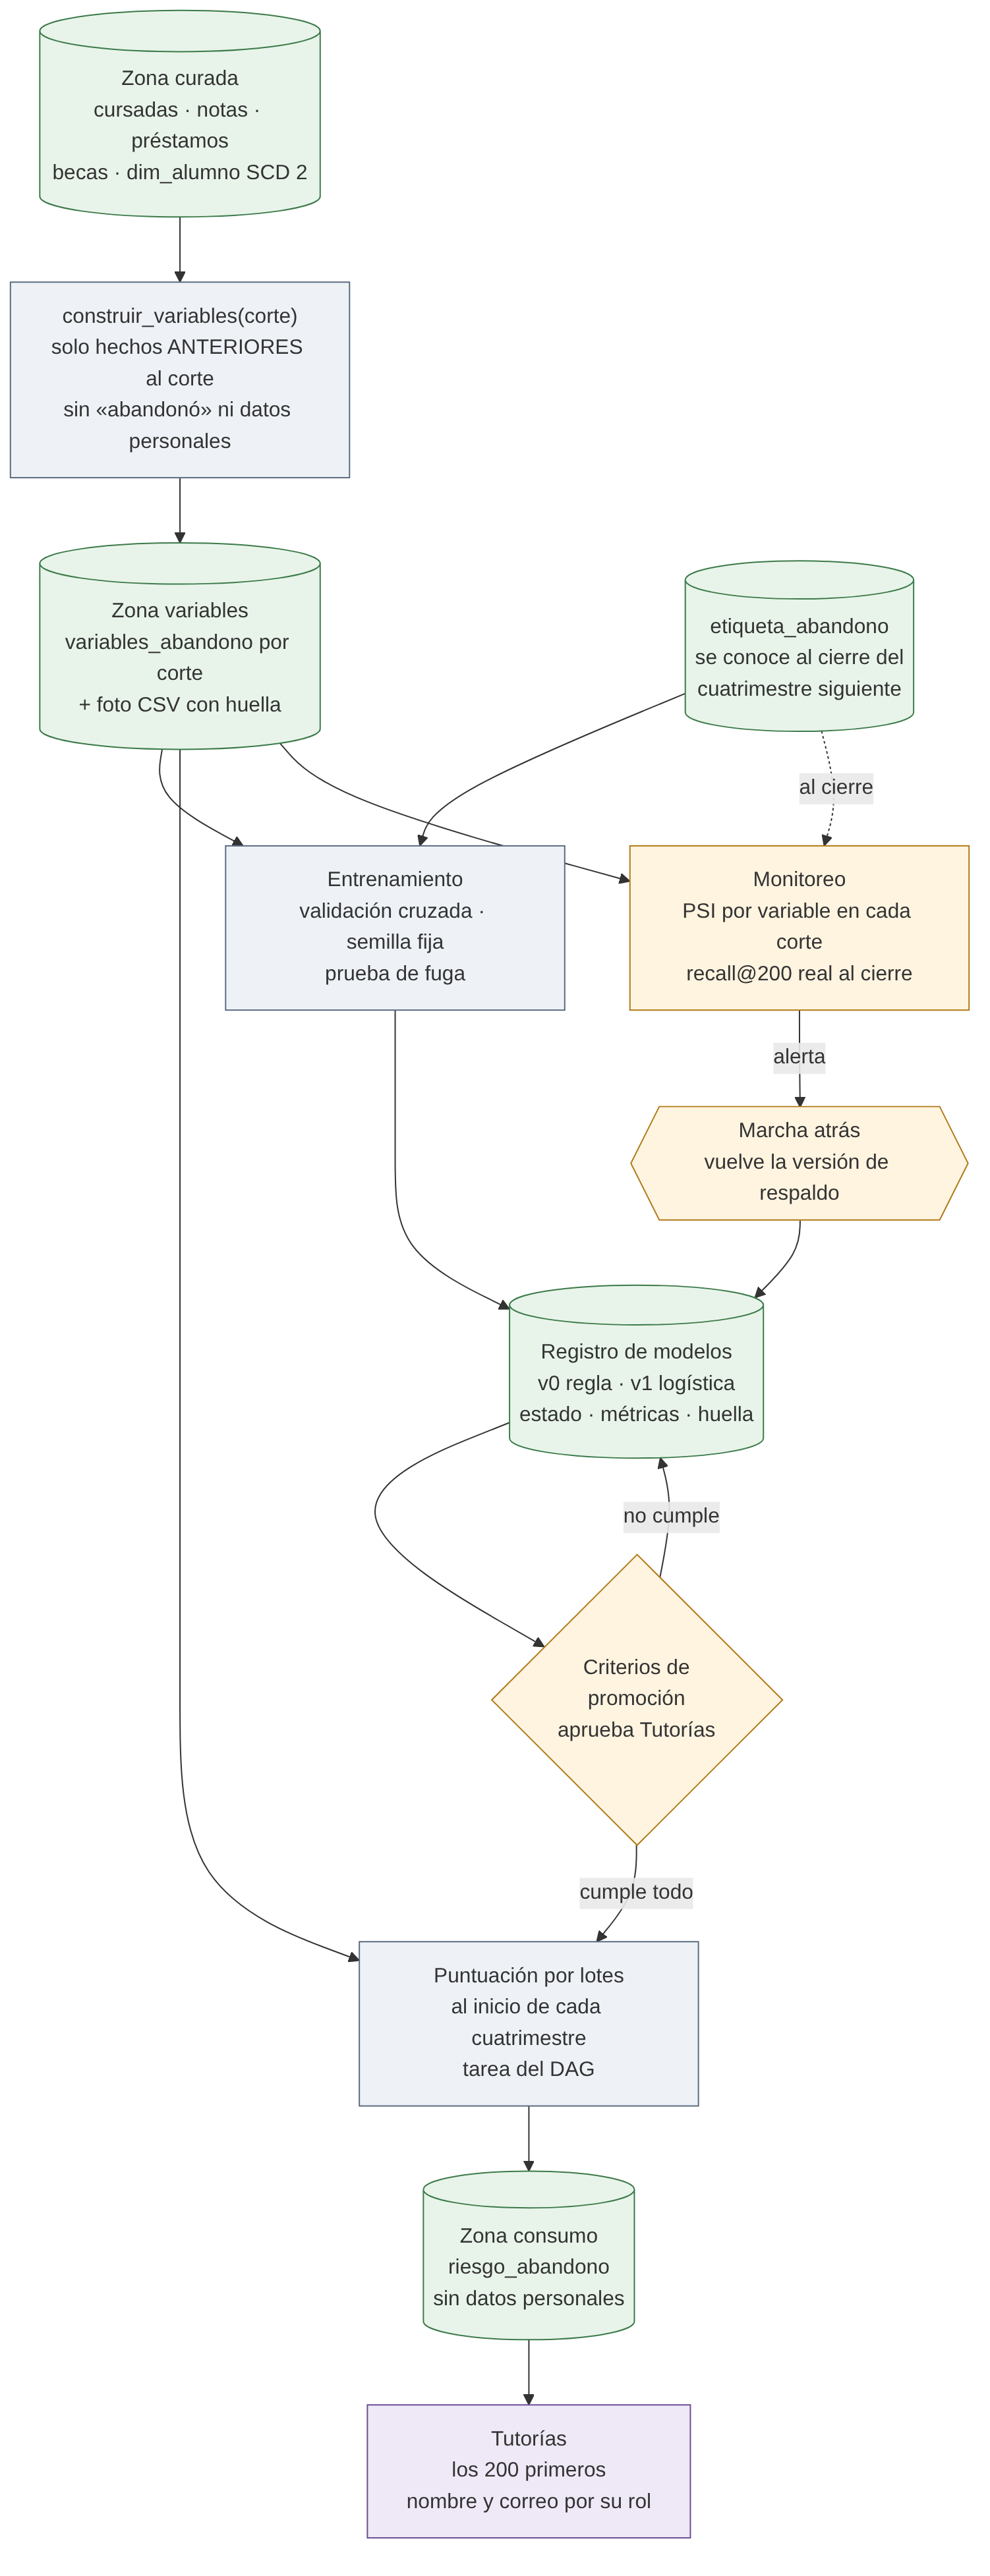

| Campo | Contenido |
| --- | --- |
| Decisión | **Puntuación por lotes** al inicio de cada cuatrimestre, como una tarea más del DAG. Las variables se guardan en una tabla con fecha de corte, y los modelos en un registro propio (tabla + carpeta). |
| Restricción comprobable | Tutorías trabaja con una lista por cuatrimestre (S16). Los datos de notas cambian una vez por cuatrimestre. El equipo de datos es chico. |
| Opción elegida y costo que se acepta | Lotes y herramientas mínimas. El costo: un alumno que empieza a faltar a mitad de cuatrimestre no aparece hasta la lista siguiente, y no hay interfaz para comparar experimentos. |
| **Alternativa descartada y por qué** | **Puntuación en línea** (un servicio que responde en cada consulta): no hay ningún consumidor que la necesite. **MLflow + un *feature store* (Feast):** resuelven el registro y las variables con más funciones, pero suman dos servicios para operar un solo modelo. |
| Control que detecta el fallo y qué se hace cuando suena | Las reglas de paso de abajo y el monitoreo del módulo 7. Si la foto de variables con la que se entrenó el modelo en producción cambió o desapareció, la regla «variables → modelo» falla: el modelo ya no se puede reproducir y no se republica. |

**Qué cambiaría la decisión:**
- Con varios modelos (riesgo de abandono, recomendación de materias, demanda de cursos), un registro como MLflow empieza a pagar su costo.
- Si Tutorías pidiera alertas semanales, las variables de préstamos se calcularían cada semana y la puntuación pasaría al calendario semanal del DAG.

In [35]:
# ===== Las reglas de paso entre zonas, verificadas sobre lo que quedó cargado =====
PII = {"dni", "nombre", "fecha_nacimiento", "email"}
columnas = lambda t: set(sql(f"PRAGMA table_info({t})", base="dwh.db").name)
pii_en = lambda t: columnas(t) & PII - ({"nombre"} if t == "dim_materia" else set())   # el nombre de una materia no es un dato personal

def archivos_crudos_intactos():
    """Cada lote de ingesta correcto tiene su archivo en la zona cruda, con la misma huella con la que se cargó."""
    lotes = sql("SELECT fuente, huella FROM control_lote WHERE proceso = 'ingesta' AND estado = 'ok'", base="dwh.db")
    en_cruda = {huella(os.path.join(r, f)) for r, _, fs in os.walk(CRUDA) for f in fs}
    return lotes.huella.isin(en_cruda).mean()

controles_zonas = pd.DataFrame([
    {"paso": "origen → cruda", "regla": "cada lote cargado tiene su archivo original intacto en la zona cruda (misma huella)",
     "medido": f"{archivos_crudos_intactos():.0%}", "cumple": archivos_crudos_intactos() == 1},
    {"paso": "cruda → curada", "regla": "todo lote cierra el balance: leídas = cargadas + cuarentena (R10)",
     "medido": f"{uno('SELECT AVG(filas_leidas = filas_cargadas + filas_cuarentena) FROM control_lote WHERE proceso = ? AND estado = ?', ('ingesta', 'ok')):.0%}",
     "cumple": uno("SELECT MIN(filas_leidas = filas_cargadas + filas_cuarentena) FROM control_lote WHERE proceso = 'ingesta' AND estado = 'ok'") == 1},
    {"paso": "cruda → curada", "regla": "toda nota y todo préstamo saben de qué lote vinieron (linaje fila por fila)",
     "medido": f"{uno('SELECT COUNT(*) FROM nota WHERE id_lote IS NULL') + uno('SELECT COUNT(*) FROM prestamo WHERE id_lote IS NULL')} sin lote",
     "cumple": uno("SELECT COUNT(*) FROM nota WHERE id_lote IS NULL") + uno("SELECT COUNT(*) FROM prestamo WHERE id_lote IS NULL") == 0},
    {"paso": "curada → consumo", "regla": "cada cuatrimestre publicado coincide con su huella, salvo un tardío pendiente de reapertura",
     "medido": ", ".join(f"{c}: {'igual' if huella_particion(c)[0] == h else 'cambió'}" for c, h in almacen.execute("SELECT cuatrimestre, huella FROM control_particion")),
     "cumple": all(huella_particion(c)[0] == h for c, h in almacen.execute("SELECT cuatrimestre, huella FROM control_particion"))},
    {"paso": "curada → consumo", "regla": "ninguna tabla de consumo tiene datos personales",
     "medido": ", ".join(t for t in zona["consumo"] if pii_en(t)) or "ninguna", "cumple": not any(pii_en(t) for t in zona["consumo"])},
    {"paso": "curada → variables", "regla": "las variables no tienen datos personales ni la etiqueta",
     "medido": ", ".join(sorted(columnas("variables_abandono") & (PII | {"abandono", "estado_final"}))) or "ninguna",
     "cumple": not columnas("variables_abandono") & (PII | {"abandono", "estado_final"})},
    {"paso": "curada → variables", "regla": "cada fila tiene corte y su cuatrimestre base terminó antes del corte",
     "medido": f"{uno('SELECT COUNT(*) FROM variables_abandono v JOIN dim_tiempo t ON t.cuatrimestre = v.cuatrimestre_base WHERE t.fecha_fin >= v.corte')} filas fuera de regla",
     "cumple": uno("SELECT COUNT(*) FROM variables_abandono v JOIN dim_tiempo t ON t.cuatrimestre = v.cuatrimestre_base WHERE t.fecha_fin >= v.corte") == 0},
    {"paso": "variables → modelo", "regla": "el modelo en producción se entrenó con una foto de variables que existe y no cambió",
     "medido": "igual" if huella(f"lake/variables/abandono/corte={CORTE}/variables.csv") == uno("SELECT huella_datos FROM registro_modelo WHERE estado = 'producción'") else "cambió",
     "cumple": huella(f"lake/variables/abandono/corte={CORTE}/variables.csv") == uno("SELECT huella_datos FROM registro_modelo WHERE estado = 'producción'")},
    {"paso": "modelo → consumo", "regla": "hay exactamente un modelo en producción y la lista publicada lo nombra",
     "medido": f"{uno('SELECT COUNT(*) FROM registro_modelo WHERE estado = ?', ('producción',))} en producción",
     "cumple": uno("SELECT COUNT(*) FROM registro_modelo WHERE estado = 'producción'") == 1},
])
print(f"{controles_zonas.cumple.sum()} de {len(controles_zonas)} reglas de paso se cumplen.")
controles_zonas

9 de 9 reglas de paso se cumplen.


,paso,regla,medido,cumple
0,origen → cruda,cada lote cargado tiene su archivo original in...,100%,True
1,cruda → curada,todo lote cierra el balance: leídas = cargadas...,100%,True
2,cruda → curada,toda nota y todo préstamo saben de qué lote vi...,0 sin lote,True
3,curada → consumo,cada cuatrimestre publicado coincide con su hu...,"2024-2c: igual, 2025-1c: igual",True
4,curada → consumo,ninguna tabla de consumo tiene datos personales,ninguna,True
5,curada → variables,las variables no tienen datos personales ni la...,ninguna,True
6,curada → variables,cada fila tiene corte y su cuatrimestre base t...,0 filas fuera de regla,True
7,variables → modelo,el modelo en producción se entrenó con una fot...,igual,True
8,modelo → consumo,hay exactamente un modelo en producción y la l...,1 en producción,True


**Las 9 reglas de paso se cumplen sobre lo que quedó cargado.** Es la evidencia de que las zonas no son solo carpetas:
- ningún archivo crudo se perdió ni se modificó;
- ningún lote perdió filas;
- ninguna tabla de consumo ni de variables tiene datos personales;
- ninguna variable mira después de su corte;
- el modelo en producción se puede reproducir con la foto exacta con la que se entrenó.

## 9 · Seguridad y metadatos

### Clasificación

Cada columna de cada tabla tiene uno de cuatro niveles: **público**, **interno**, **confidencial** o **sensible**. Por defecto, una columna es «interno»: nada se publica sin decidirlo.

Los cinco datos que el caso marca como sensibles se clasifican así:
- **DNI y fecha de nacimiento: sensible.** Identifican a la persona también fuera de la universidad, y la fecha habilita discriminar por edad.
- **Nombre, correo y legajo: confidencial.** Identifican a la persona, pero solo dentro de la universidad.

También aparecieron datos personales que el caso no nombra:
- **El tipo de beca es «sensible»:** una beca por «Necesidad» revela la situación económica de una persona.
- **La lista de riesgo es «sensible»:** quedar etiquetado como «en riesgo de abandonar» puede estigmatizar.
- **La cuarentena es «sensible»:** guarda la fila original tal cual llegó, con DNI y nombre incluidos. Es fácil olvidarse de esta.

**Seudonimización.** Fuera de `persona_pii`, las personas aparecen con un seudónimo (`id_persona`) calculado con una clave secreta. En el primer diseño, el identificador repetía el número de legajo (`P00367` ↔ `L20367`). Eso dejaba sin efecto el enmascaramiento del legajo, porque se podía reconstruir. Se corrigió en el módulo 3.

In [36]:
# ===== Clasificación: cada columna de cada tabla tiene un nivel =====
# público < interno < confidencial < sensible. Lo que no está listado es «interno» (por defecto, nada es público).
NIVELES = ["público", "interno", "confidencial", "sensible"]
clasificacion = {
    # --- Los cinco datos que el caso marca como sensibles ---
    "persona_pii.dni": "sensible",                  # identifica a la persona de forma única y fuera de la universidad
    "persona_pii.fecha_nacimiento": "sensible",     # junto con otros datos reidentifica; habilita discriminar por edad
    "persona_pii.nombre": "confidencial",
    "persona_pii.email": "confidencial",
    "legajo.legajo": "confidencial", "legajo.id_alumno": "confidencial",
    "dim_alumno.legajo_vigente": "confidencial", "dim_alumno.id_alumno_vigente": "confidencial",
    # --- Otros datos que el caso no nombra, pero que son personales ---
    "beca.tipo_beca": "sensible",                   # «Necesidad» revela la situación económica de una persona
    "beca.porcentaje": "confidencial",
    "cursada.estado": "confidencial", "nota.nota": "confidencial", "nota.ausente": "confidencial",   # rendimiento de una persona
    # En consumo, nota y estado quedan «interno»: están seudonimizados (sin legajo en claro no se sabe de quién son).
    "prestamo.isbn": "confidencial",                # qué lee una persona
    "riesgo_abandono.score": "sensible", "riesgo_abandono.puesto": "sensible", "riesgo_abandono.en_lista": "sensible",  # perfilamiento: estigmatiza
    # etiqueta_abandono y variables_abandono quedan «interno»: están seudonimizadas, solo las lee ciencia de datos,
    # y las necesita en claro para entrenar. La beca aparece solo como porcentaje, sin el tipo («Necesidad»).
    "respuesta_encuesta.comentario": "confidencial",  # anónima, pero el texto libre puede nombrar a alguien
    "cuarentena.registro": "sensible",               # guarda la fila original tal cual llegó: puede traer DNI y nombre
    # --- Lo que puede publicarse ---
    **{f"{t}.{c}": "público" for t in ("materia", "dim_materia") for c in ("id_materia", "nombre", "carrera")},
    **{f"dim_tiempo.{c}": "público" for c in ("cuatrimestre", "anio", "numero", "fecha_inicio", "fecha_fin")},
}
TABLAS = [t for ts in zona.values() for t in ts]
for t in TABLAS:                                    # todo lo demás: interno
    for c in sql(f"PRAGMA table_info({t})", base="dwh.db").name:
        clasificacion.setdefault(f"{t}.{c}", "interno")

nivel_de = lambda tabla, columna: clasificacion.get(f"{tabla}.{columna}", "interno")
resumen = pd.Series(clasificacion).rename("nivel").rename_axis("columna").reset_index()
resumen["tabla"] = resumen.columna.str.split(".").str[0]
print(f"{len(resumen)} columnas clasificadas en {resumen.tabla.nunique()} tablas:",
      ", ".join(f"{n} {k}" for k, n in resumen.nivel.value_counts().reindex(NIVELES).items()))
resumen[resumen.nivel.isin(["sensible", "confidencial"])].groupby("nivel").columna.apply(lambda s: ", ".join(s)).reindex(["sensible", "confidencial"]).to_frame()

133 columnas clasificadas en 21 tablas: 11 público, 103 interno, 12 confidencial, 7 sensible


,columna
nivel,
sensible,"persona_pii.dni, persona_pii.fecha_nacimiento,..."
confidencial,"persona_pii.nombre, persona_pii.email, legajo...."


### Accesos por rol y enmascaramiento

Cada rol tiene un **nivel máximo que puede ver en claro**. La regla es la misma para todas las tablas:
- las columnas de su nivel o menos se ven **en claro**;
- las de un nivel más arriba se ven **enmascaradas** (la forma del dato, no el dato);
- las de dos niveles o más arriba **no aparecen**.

Además, cada rol tiene una lista de tablas a las que puede entrar. **Cada consulta queda registrada**, incluidas las denegadas.

| Rol | Ve en claro hasta | Tablas | Para qué |
| --- | --- | --- | --- |
| Responsable de datos académicos | sensible | todas | Decide sobre casos concretos: cuarentena, inconsistencias |
| Equipo de datos | confidencial | todas | Opera la plataforma; ve el DNI y la cuarentena enmascarados |
| Ciencia de datos | interno | variables, consumo, modelos, calidad | Entrena y monitorea; no ve datos personales |
| Analista BI | interno | dimensiones, hecho, encuesta, calidad | Arma tableros con datos seudonimizados |
| Tutor | — | solo la vista `lista_para_tutorias` | Contacta a los alumnos de la lista vigente |

**El tutor es un caso aparte.** Necesita el nombre y el correo para contactar al alumno, pero solo de los 200 de su lista: es un filtro **por fila** (*row-level security*). Además, no ve el *score* ni el puesto: «está en la lista» alcanza para llamar, y un número de riesgo pegado a un nombre es lo que más estigmatiza.

In [37]:
# ===== Accesos por rol, enmascaramiento y auditoría =====
# Cada rol tiene un nivel máximo que puede ver EN CLARO.
# - Columnas de ese nivel o menos: en claro.
# - Un nivel más arriba: enmascaradas (se ve la forma del dato, no el dato).
# - Dos niveles o más arriba: la columna no aparece.
ROLES = {
    "responsable_datos_academicos": {"nivel": "sensible", "tablas": TABLAS},
    "equipo_datos":   {"nivel": "confidencial", "tablas": TABLAS},
    "ciencia_datos":  {"nivel": "interno", "tablas": zona["variables"] + zona["consumo"] + zona["modelos"] + ["resultado_calidad"]},
    "analista_bi":    {"nivel": "interno", "tablas": ["dim_tiempo", "dim_materia", "dim_alumno", "hecho_cursada", "respuesta_encuesta", "resultado_calidad"]},
}

def enmascarar_columna(columna, serie):
    if columna == "email":            return serie.map(lambda e: e[0] + "***@" + e.split("@")[1] if isinstance(e, str) and "@" in e else e)
    if columna == "fecha_nacimiento": return serie.map(lambda f: str(f)[:4] + "-**-**")       # generalización: solo el año
    if columna == "registro":         return serie.map(lambda r: "{…oculto…}")
    if pd.api.types.is_numeric_dtype(serie): return serie.map(lambda v: "•••")                # un número corto no se puede enmascarar «a medias»
    return serie.map(lambda v: None if v is None else enmascarar(v, 2))                    # la función que trae el notebook

def auditar(rol, objeto, resultado, filas=None, enmascaradas=(), quitadas=()):
    almacen.execute("INSERT INTO auditoria_acceso (momento, rol, objeto, resultado, filas, enmascaradas, quitadas) VALUES (datetime('now'), ?, ?, ?, ?, ?, ?)",
                    (rol, objeto, resultado, filas, ", ".join(enmascaradas), ", ".join(quitadas)))

def consultar(rol, tabla, limite=None):
    """Lo que ve un rol cuando consulta una tabla: con la política aplicada y el acceso registrado."""
    politica = ROLES[rol]
    if tabla not in politica["tablas"]:
        auditar(rol, tabla, "denegado")
        raise PermissionError(f"el rol {rol} no tiene acceso a {tabla}")
    df = sql(f"SELECT * FROM {tabla}" + (f" LIMIT {limite}" if limite else ""), base="dwh.db")
    tope = NIVELES.index(politica["nivel"]); enmascaradas, quitadas = [], []
    for c in list(df.columns):
        distancia = NIVELES.index(nivel_de(tabla, c)) - tope
        if distancia == 1:   df[c] = enmascarar_columna(c, df[c]); enmascaradas.append(c)
        elif distancia >= 2: df = df.drop(columns=c); quitadas.append(c)
    auditar(rol, tabla, "permitido", len(df), enmascaradas, quitadas)
    return df

def lista_para_tutorias(tutor="tutor_general"):
    """Rol tutor: NO consulta tablas. Ve una sola vista, filtrada por fila (row-level security): los alumnos de la lista vigente,
    con nombre y correo para contactarlos y sin DNI, fecha de nacimiento, score ni puesto (para no etiquetar a nadie con un número)."""
    v = sql("""SELECT p.nombre, p.email, d.carrera
               FROM riesgo_abandono r
               JOIN persona_pii p USING (id_persona)
               JOIN dim_alumno d ON d.id_persona = r.id_persona AND d.es_vigente = 1
               WHERE r.en_lista = 1 AND r.corte = (SELECT MAX(corte) FROM riesgo_abandono)
                 AND r.version_modelo = (SELECT version FROM registro_modelo WHERE estado = 'producción')
               ORDER BY d.carrera, p.nombre""", base="dwh.db")
    auditar(f"tutor:{tutor}", "vista lista_para_tutorias", "permitido", len(v))
    return v

# Demostración 1 · la misma tabla, tres roles.
for rol in ("responsable_datos_academicos", "equipo_datos", "analista_bi"):
    print(f"\n{rol} consulta dim_alumno:")
    display(consultar(rol, "dim_alumno", limite=2))


responsable_datos_academicos consulta dim_alumno:


,sk_alumno,id_persona,id_alumno_vigente,legajo_vigente,carrera,plan_estudio,valido_desde,valido_hasta,es_vigente
0,1,Pb078a67657,AL00367,L20367,Ingeniería,2018,2024-08-01,9999-12-31,1
1,2,Pe0c1412044,AL01914,L21914,Psicología,2018,2024-08-01,2025-06-03,0



equipo_datos consulta dim_alumno:


,sk_alumno,id_persona,id_alumno_vigente,legajo_vigente,carrera,plan_estudio,valido_desde,valido_hasta,es_vigente
0,1,Pb078a67657,AL00367,L20367,Ingeniería,2018,2024-08-01,9999-12-31,1
1,2,Pe0c1412044,AL01914,L21914,Psicología,2018,2024-08-01,2025-06-03,0



analista_bi consulta dim_alumno:


,sk_alumno,id_persona,id_alumno_vigente,legajo_vigente,carrera,plan_estudio,valido_desde,valido_hasta,es_vigente
0,1,Pb078a67657,*****67,****67,Ingeniería,2018,2024-08-01,9999-12-31,1
1,2,Pe0c1412044,*****14,****14,Psicología,2018,2024-08-01,2025-06-03,0


In [38]:
# Demostración 2 · los datos personales: quién los ve y cómo.
print("equipo_datos consulta persona_pii (el DNI y la fecha de nacimiento son «sensible»: un nivel arriba del suyo → enmascarados):")
display(consultar("equipo_datos", "persona_pii", limite=3))
print("equipo_datos consulta la cuarentena (el registro original puede traer DNI y nombre: es «sensible» → oculto):")
display(consultar("equipo_datos", "cuarentena", limite=3))
print("ciencia_datos consulta riesgo_abandono (score, puesto y en_lista son «sensible»: dos niveles arriba del suyo → no aparecen):")
display(consultar("ciencia_datos", "riesgo_abandono", limite=3))
for rol, tabla in (("analista_bi", "persona_pii"), ("ciencia_datos", "beca"), ("analista_bi", "riesgo_abandono")):
    try:
        consultar(rol, tabla)
    except PermissionError as e:
        print("⛔", e)

# Demostración 3 · el rol tutor, filtrado por fila.
tutorias = lista_para_tutorias()
print(f"\nTutorías ve {len(tutorias)} alumnos (la lista vigente), de {uno('SELECT COUNT(*) FROM persona_pii')} personas en la base:")
display(tutorias.head(3))

print("Registro de accesos (auditoría):")
sql("SELECT momento, rol, objeto, resultado, filas, enmascaradas, quitadas FROM auditoria_acceso ORDER BY id_acceso", base="dwh.db") \
    .astype({"filas": "Int64"})

equipo_datos consulta persona_pii (el DNI y la fecha de nacimiento son «sensible»: un nivel arriba del suyo → enmascarados):


,id_persona,dni,nombre,fecha_nacimiento,email
0,Pb078a67657,******51,Alumno 00367,2001-**-**,alumno367@uniandina.test
1,Pe0c1412044,******08,Alumno 01914,2001-**-**,alumno1914@uniandina.test
2,Pb00281c655,******60,Alumno 01144,2000-**-**,alumno1144@uniandina.test


equipo_datos consulta la cuarentena (el registro original puede traer DNI y nombre: es «sensible» → oculto):


,id_cuarentena,id_lote,fuente,registro,motivo,resuelto
0,1,1,op.cambios_plan,{…oculto…},cambio de plan repetido en el otro legajo de l...,0
1,2,2,op.cambios_plan,{…oculto…},cambio de plan repetido en el otro legajo de l...,0
2,3,3,op.cambios_plan,{…oculto…},cambio de plan repetido en el otro legajo de l...,0


ciencia_datos consulta riesgo_abandono (score, puesto y en_lista son «sensible»: dos niveles arriba del suyo → no aparecen):


,id_persona,corte,version_modelo
0,P004e2ecfba,2025-03-01,v2
1,P0052a79606,2025-03-01,v2
2,P00542a4bf8,2025-03-01,v2


⛔ el rol analista_bi no tiene acceso a persona_pii
⛔ el rol ciencia_datos no tiene acceso a beca
⛔ el rol analista_bi no tiene acceso a riesgo_abandono

Tutorías ve 200 alumnos (la lista vigente), de 2000 personas en la base:


,nombre,email,carrera
0,Alumno 00011,alumno11@uniandina.test,Administración
1,Alumno 00013,alumno13@uniandina.test,Administración
2,Alumno 00093,alumno93@uniandina.test,Administración


Registro de accesos (auditoría):


,momento,rol,objeto,resultado,filas,enmascaradas,quitadas
0,2026-11-03 23:16:00,responsable_datos_academicos,dim_alumno,permitido,2,,
1,2026-11-03 23:16:00,equipo_datos,dim_alumno,permitido,2,,
2,2026-11-03 23:16:00,analista_bi,dim_alumno,permitido,2,"id_alumno_vigente, legajo_vigente",
3,2026-11-03 23:16:00,equipo_datos,persona_pii,permitido,3,"dni, fecha_nacimiento",
4,2026-11-03 23:16:00,equipo_datos,cuarentena,permitido,3,registro,
5,2026-11-03 23:16:00,ciencia_datos,riesgo_abandono,permitido,3,,"score, puesto, en_lista"
6,2026-11-03 23:16:00,analista_bi,persona_pii,denegado,<NA>,,
7,2026-11-03 23:16:00,ciencia_datos,beca,denegado,<NA>,,
8,2026-11-03 23:16:00,analista_bi,riesgo_abandono,denegado,<NA>,,
9,2026-11-03 23:16:00,tutor:tutor_general,vista lista_para_tutorias,permitido,200,,


| Campo | Contenido |
| --- | --- |
| Decisión | Política de acceso **por nivel de clasificación**, la misma para todas las tablas. El tutor entra solo por una vista filtrada por fila. Todo acceso se audita. |
| Restricción comprobable | Hay datos personales de estudiantes (consigna). La Ley 25.326 de protección de datos personales exige medidas de seguridad y confidencialidad, y usar los datos solo para la finalidad con la que se recolectaron. |
| Opción elegida y costo que se acepta | Una regla general («un nivel arriba se enmascara, dos se quita»). El costo: algunos casos necesitan excepciones explícitas. Por ejemplo, el porcentaje de beca en las variables queda «interno» porque ciencia de datos lo necesita en claro para entrenar. |
| **Alternativa descartada y por qué** | **Una matriz rol × columna escrita a mano.** Con 133 columnas, se desactualiza en cuanto alguien agrega una tabla, y la columna nueva queda abierta. Con la regla por nivel, una columna nueva nace «interno» y nadie fuera de los roles internos la ve. |
| Control que detecta el fallo y qué se hace cuando suena | La auditoría de accesos y la regla de paso «ninguna tabla de consumo tiene datos personales» (módulo 8). Un acceso denegado repetido, o una consulta a `persona_pii` fuera de lo habitual, se revisa. **Decide la Dirección del área de datos**, que puede revocar el rol. |

**En el motor real del curso (Oracle) esto no se programa a mano: se configura.**

| En este notebook | En Oracle |
| --- | --- |
| `ROLES` y la lista de tablas por rol | `CREATE ROLE analista_bi; GRANT SELECT ON hecho_cursada TO analista_bi;` |
| `enmascarar_columna` según el nivel | Data Redaction: `DBMS_REDACT.ADD_POLICY` (parcial para el DNI, completa para la cuarentena) |
| `lista_para_tutorias`, filtrada por fila | Virtual Private Database: `DBMS_RLS.ADD_POLICY` con un predicado `en_lista = 1` |
| `auditoria_acceso` | Unified Auditing: `CREATE AUDIT POLICY ... ACTIONS SELECT ON persona_pii` |
| `seudonimo()` con clave secreta | `STANDARD_HASH` con una clave guardada en un *wallet*, fuera del código |

### Catálogo mínimo

El catálogo tiene dos partes:
- **Lo que se escribe a mano:** para qué sirve cada tabla y quién es su dueño.
- **Lo que se calcula solo, en cada corrida:** zona, nivel de clasificación más alto, cantidad de filas y última carga.

Un catálogo escrito entero a mano se desactualiza el primer día. Uno calculado entero no sabe para qué sirve cada cosa.

In [39]:
# ===== Catálogo mínimo: las tablas =====
# Lo que se escribe a mano (para qué sirve y de quién es) + lo que se calcula solo (filas, frescura, clasificación, calidad).
DESCRIPCION = {
    "control_lote": ("Cada ejecución: qué se leyó, cargó y fue a cuarentena", "Equipo de datos"),
    "cuarentena": ("Filas y archivos que no pasaron un control, con su motivo", "Responsable de datos académicos"),
    "control_particion": ("Huella de cada cuatrimestre publicado (datos tardíos)", "Equipo de datos"),
    "resultado_calidad": ("Cada medición de cada regla de calidad", "Responsable de datos académicos"),
    "auditoria_acceso": ("Quién consultó qué y qué vio", "Dirección del área de datos"),
    "persona_pii": ("Datos personales de cada persona (acceso restringido)", "Secretaría Académica"),
    "legajo": ("Equivalencia legajo → persona; marca el legajo vigente", "Secretaría Académica"),
    "materia": ("Materias y su carrera", "Secretaría Académica"),
    "cursada": ("Inscripción de una persona a una materia en un cuatrimestre", "Secretaría Académica"),
    "nota": ("Nota de cada cursada, de 0 a 10, con su fuente (acta o CSV)", "Dirección de Alumnos"),
    "prestamo": ("Préstamos de biblioteca", "Dirección de Biblioteca"),
    "beca": ("Becas por persona", "Área de Becas"),
    "respuesta_encuesta": ("Respuestas anónimas de la encuesta de satisfacción", "Área de Evaluación Institucional"),
    "dim_tiempo": ("Cuatrimestres con sus fechas", "Equipo de datos"),
    "dim_materia": ("Materias (dimensión)", "Secretaría Académica"),
    "dim_alumno": ("Alumno con historia de plan (SCD 2), sin datos personales", "Secretaría Académica"),
    "hecho_cursada": ("Una fila por persona, materia y cuatrimestre: estado, nota, aprobada", "Secretaría Académica"),
    "riesgo_abandono": ("Lista de riesgo publicada por corte y versión del modelo", "Secretaría Académica · Tutorías"),
    "variables_abandono": ("Variables del modelo por persona y fecha de corte", "Equipo de datos"),
    "etiqueta_abandono": ("Si la persona abandonó, por corte (solo para entrenar)", "Secretaría Académica"),
    "registro_modelo": ("Versiones del modelo, métricas y estado", "Equipo de datos"),
}
zona_de = {t: z for z, ts in zona.items() for t in ts}
ultima_carga = dict(almacen.execute("SELECT fuente, MAX(fin) FROM control_lote WHERE estado = 'ok' GROUP BY fuente").fetchall())
FUENTE_DE = {"cursada": "base_academica.cursadas", "materia": "base_academica.materias", "prestamo": "biblioteca", "beca": "becas",
             "respuesta_encuesta": "encuesta", "nota": "actas_docentes", "hecho_cursada": "zona curada al", "dim_alumno": "op.alumnos"}
def frescura(t):
    f = FUENTE_DE.get(t)
    return next((v for k, v in ultima_carga.items() if f and k.startswith(f)), "—")

catalogo_tablas = pd.DataFrame([{
    "tabla": t, "zona": zona_de[t], "para qué sirve": DESCRIPCION[t][0], "dueño": DESCRIPCION[t][1],
    "nivel máximo": max((nivel_de(t, c) for c in sql(f"PRAGMA table_info({t})", base="dwh.db").name), key=NIVELES.index),
    "filas": uno(f"SELECT COUNT(*) FROM {t}"), "última carga": frescura(t)} for t in TABLAS])
catalogo_tablas

,tabla,zona,para qué sirve,dueño,nivel máximo,filas,última carga
0,control_lote,control,"Cada ejecución: qué se leyó, cargó y fue a cua...",Equipo de datos,interno,80,—
1,cuarentena,control,"Filas y archivos que no pasaron un control, co...",Responsable de datos académicos,sensible,266,—
2,control_particion,control,Huella de cada cuatrimestre publicado (datos t...,Equipo de datos,interno,2,—
3,resultado_calidad,control,Cada medición de cada regla de calidad,Responsable de datos académicos,interno,10,—
4,auditoria_acceso,control,Quién consultó qué y qué vio,Dirección del área de datos,interno,10,—
5,persona_pii,curada,Datos personales de cada persona (acceso restr...,Secretaría Académica,sensible,2000,—
6,legajo,curada,Equivalencia legajo → persona; marca el legajo...,Secretaría Académica,confidencial,2060,—
7,materia,curada,Materias y su carrera,Secretaría Académica,público,40,2026-11-03 23:15:36
8,cursada,curada,Inscripción de una persona a una materia en un...,Secretaría Académica,confidencial,15290,2026-11-03 23:15:36
9,nota,curada,"Nota de cada cursada, de 0 a 10, con su fuente...",Dirección de Alumnos,confidencial,15232,2026-11-03 23:15:37


### Un indicador con su linaje: la tasa de aprobación

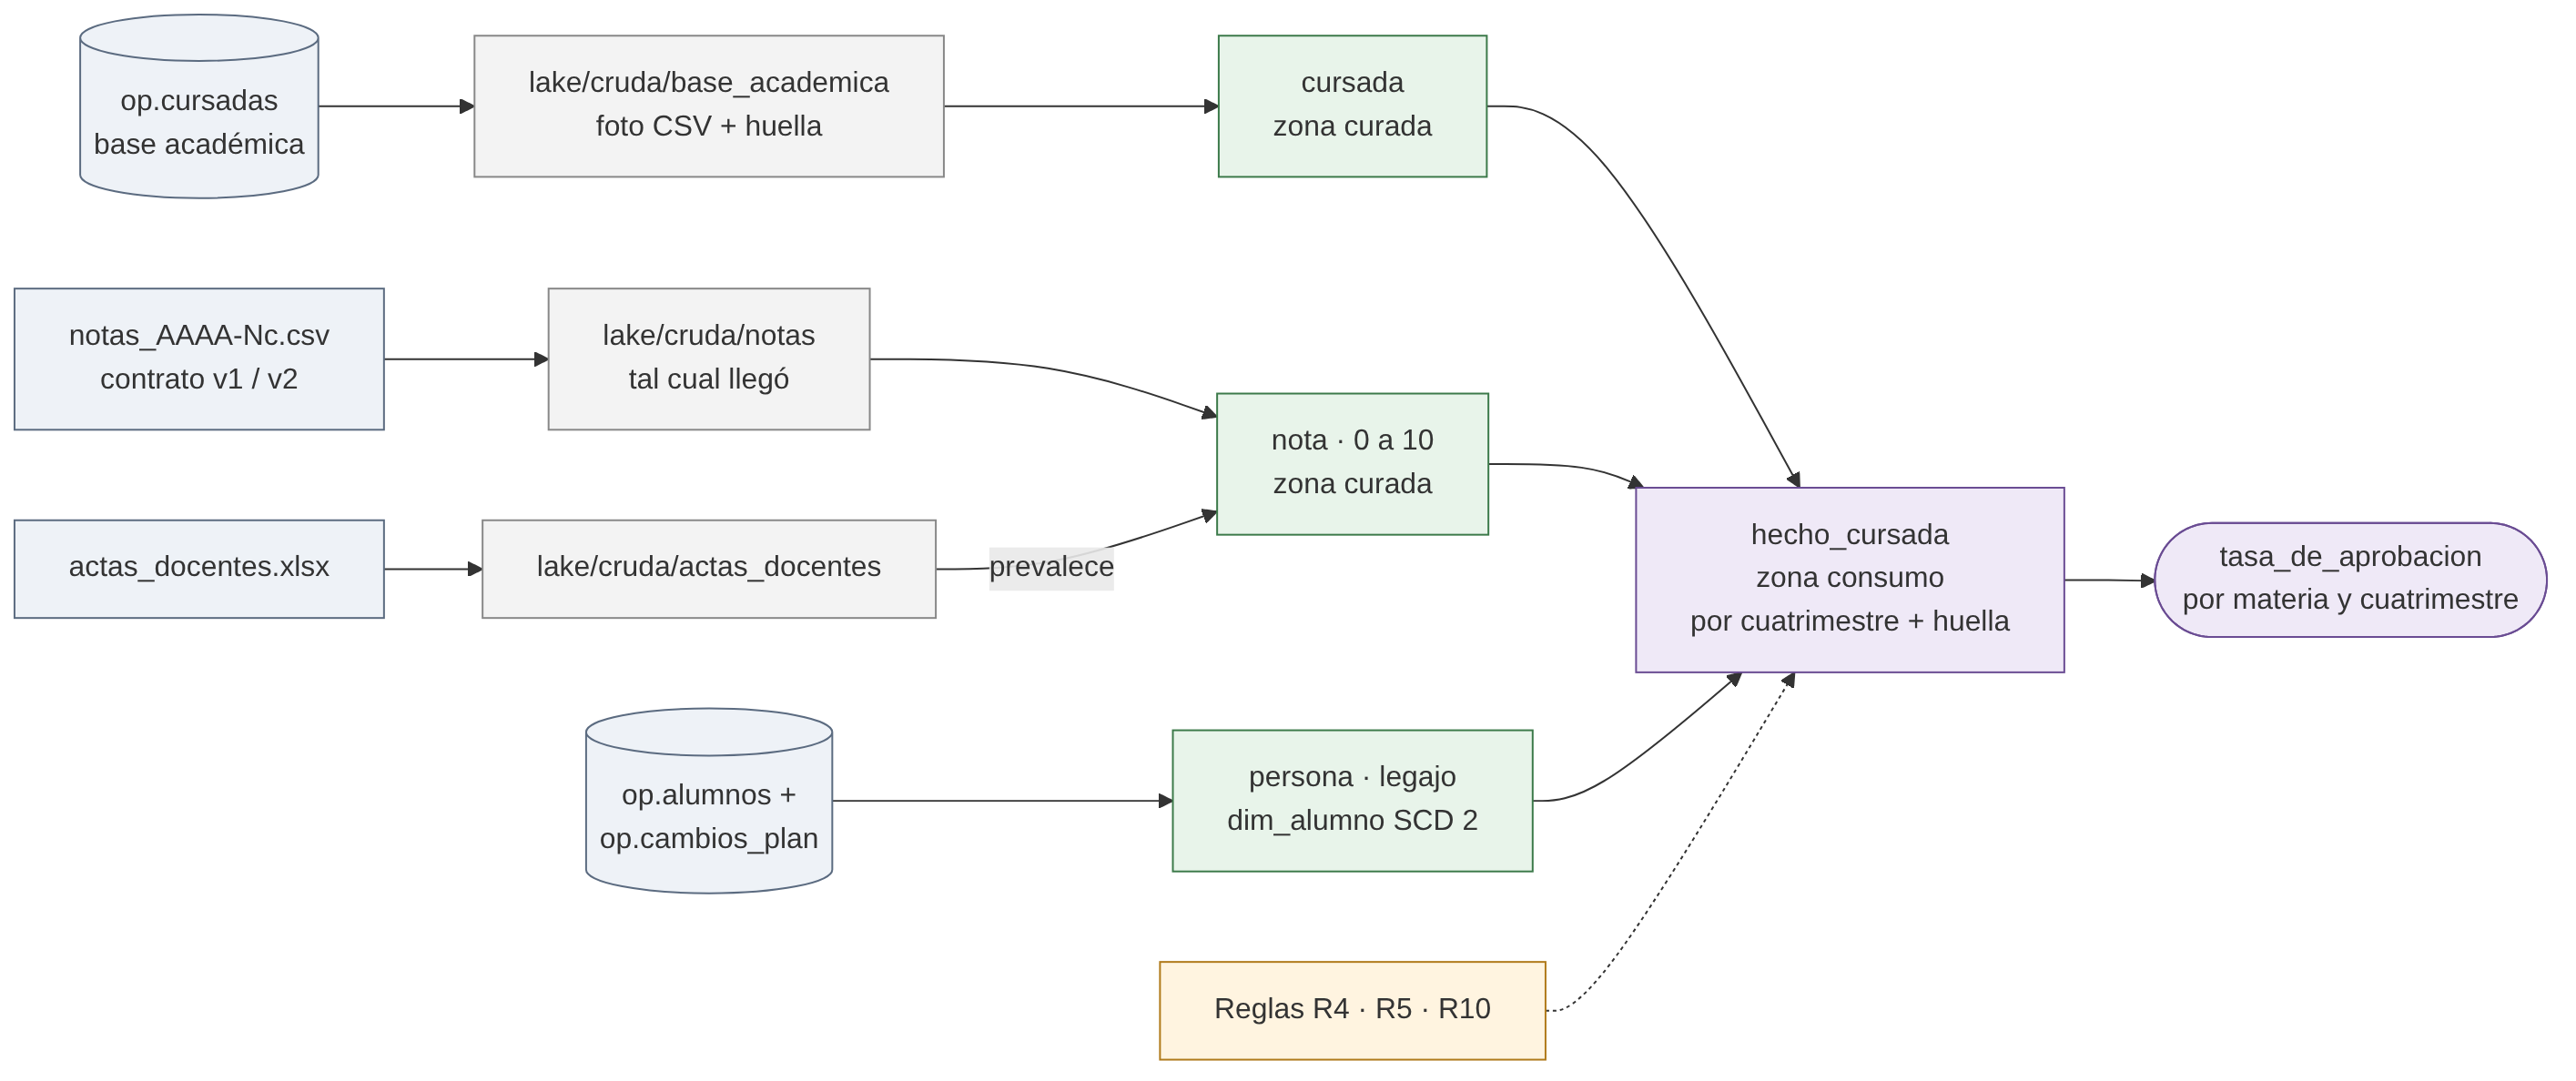

El linaje se puede recorrer en los dos sentidos:
- **Hacia atrás:** para un valor del tablero (una materia en un cuatrimestre), se listan los lotes de los que salió, con la huella de cada archivo crudo. Si alguien pregunta «¿de dónde salió este 98 %?», la respuesta es un lote y un archivo concretos.
- **Como verificación:** el indicador recalculado desde la zona curada tiene que dar exactamente lo mismo que el del tablero. Si no da igual, algo se rompió entre curada y consumo.

In [40]:
# ===== Catálogo mínimo: un indicador con su linaje =====
catalogo = {
    "tasa_de_aprobacion": {
        "dueño": "Secretaría Académica",
        "responsable": "Responsable de datos académicos",
        "definición": "De las cursadas terminadas (aprobadas o desaprobadas) de una materia en un cuatrimestre, qué parte se aprobó. "
                      "Las cursadas «abandonó» no cuentan: no terminaron.",
        "fórmula": "SUM(aprobada) / COUNT(*) sobre hecho_cursada con estado IN ('aprobada', 'desaprobada'), por materia y cuatrimestre",
        "frescura": "Diaria durante el cierre de actas, semanal el resto del año (DAG del módulo 5). Un cuatrimestre se congela 60 días después de su fin.",
        "clasificación": "público (es un agregado por materia; ninguna persona se puede identificar)",
        "calidad": ["R4 · estado que contradice la nota", "R5 · completitud de notas", "R10 · balance de lotes"],
        "linaje": [
            ("base académica · cursadas", "origen", "op.cursadas"),
            ("foto CSV en zona cruda", "cruda", "lake/cruda/base_academica/…/cursadas.csv"),
            ("cursada (persona, materia, cuatrimestre, estado)", "curada", "procesar_cursadas · módulo 4"),
            ("notas CSV por cuatrimestre + actas docentes", "origen", "datos_externos/"),
            ("nota (0 a 10, el acta prevalece)", "curada", "procesar_notas, procesar_actas · módulo 4"),
            ("dim_alumno (versión vigente al inicio del cuatrimestre)", "consumo", "cargar_dim_alumno · módulo 3"),
            ("hecho_cursada", "consumo", "publicar_consumo · módulo 5"),
            ("tasa_de_aprobacion", "indicador", "esta consulta"),
        ],
    }
}

def tasa_de_aprobacion():
    """El indicador, calculado desde la zona consumo (lo que ve el tablero)."""
    return sql("""SELECT t.cuatrimestre, m.nombre AS materia, COUNT(*) AS terminadas, SUM(h.aprobada) AS aprobadas,
                         ROUND(1.0 * SUM(h.aprobada) / COUNT(*), 4) AS tasa_de_aprobacion
                  FROM hecho_cursada h JOIN dim_tiempo t USING (sk_tiempo) JOIN dim_materia m USING (sk_materia)
                  WHERE h.estado IN ('aprobada', 'desaprobada') GROUP BY 1, 2 ORDER BY 1, 2""", base="dwh.db")

def linaje_de(cuatrimestre, materia):
    """Recorre el linaje al revés para UN valor del tablero: de qué lotes y de qué archivos crudos (con su huella) salió."""
    lotes = sql("""SELECT DISTINCT l.id_lote, l.proceso, l.fuente, substr(l.huella, 1, 12) AS huella, l.fin
                   FROM hecho_cursada h JOIN dim_tiempo t USING (sk_tiempo) JOIN dim_materia m USING (sk_materia)
                   JOIN cursada c ON c.id_cursada = h.id_cursada LEFT JOIN nota n ON n.id_cursada = c.id_cursada
                   JOIN control_lote l ON l.id_lote IN (h.id_lote, n.id_lote)
                   WHERE t.cuatrimestre = ? AND m.nombre = ?
                   UNION
                   SELECT id_lote, proceso, fuente, substr(huella, 1, 12), fin FROM control_lote
                   WHERE id_lote = (SELECT MAX(id_lote) FROM control_lote WHERE fuente = 'base_academica.cursadas' AND estado = 'ok')
                   ORDER BY 1""", base="dwh.db", parametros=(cuatrimestre, materia))
    return lotes

tablero = tasa_de_aprobacion()
# Verificación del linaje: el mismo indicador recalculado desde la zona CURADA tiene que dar igual que el de consumo.
desde_curada = sql("""SELECT c.cuatrimestre, m.nombre AS materia, ROUND(AVG(CASE WHEN c.estado = 'aprobada' THEN 1.0 ELSE 0 END), 4) AS tasa_curada
                      FROM cursada c JOIN materia m USING (id_materia) WHERE c.estado IN ('aprobada', 'desaprobada') GROUP BY 1, 2""", base="dwh.db")
cruce = tablero.merge(desde_curada, on=["cuatrimestre", "materia"])
print(f"Linaje verificado: {(cruce.tasa_de_aprobacion == cruce.tasa_curada).sum()} de {len(cruce)} valores del tablero "
      "coinciden con el recálculo desde la zona curada.")
ficha_indicador = {k: (v if not isinstance(v, list) else " → ".join(x[0] if isinstance(x, tuple) else x for x in v))
                   for k, v in catalogo["tasa_de_aprobacion"].items()}
display(pd.DataFrame(ficha_indicador.items(), columns=["campo", "contenido"]).style.hide(axis="index").set_properties(**{"text-align": "left"}))
ejemplo = tablero.iloc[0]
print(f"Ejemplo: {ejemplo.materia} en {ejemplo.cuatrimestre} → tasa de aprobación {ejemplo.tasa_de_aprobacion:.1%} "
      f"({ejemplo.aprobadas} de {ejemplo.terminadas}). Salió de estos lotes:")
linaje_de(ejemplo.cuatrimestre, ejemplo.materia)

Linaje verificado: 80 de 80 valores del tablero coinciden con el recálculo desde la zona curada.


campo,contenido
dueño,Secretaría Académica
responsable,Responsable de datos académicos
definición,"De las cursadas terminadas (aprobadas o desaprobadas) de una materia en un cuatrimestre, qué parte se aprobó. Las cursadas «abandonó» no cuentan: no terminaron."
fórmula,"SUM(aprobada) / COUNT(*) sobre hecho_cursada con estado IN ('aprobada', 'desaprobada'), por materia y cuatrimestre"
frescura,"Diaria durante el cierre de actas, semanal el resto del año (DAG del módulo 5). Un cuatrimestre se congela 60 días después de su fin."
clasificación,público (es un agregado por materia; ninguna persona se puede identificar)
calidad,R4 · estado que contradice la nota → R5 · completitud de notas → R10 · balance de lotes
linaje,"base académica · cursadas → foto CSV en zona cruda → cursada (persona, materia, cuatrimestre, estado) → notas CSV por cuatrimestre + actas docentes → nota (0 a 10, el acta prevalece) → dim_alumno (versión vigente al inicio del cuatrimestre) → hecho_cursada → tasa_de_aprobacion"


Ejemplo: Materia 00 en 2024-2c → tasa de aprobación 98.1% (207 de 211). Salió de estos lotes:


,id_lote,proceso,fuente,huella,fin
0,22,ingesta,base_academica.cursadas,e2aa51a2f80d,2026-11-03 23:15:36
1,24,ingesta,notas_2024-2c,4a8e82d54902,2026-11-03 23:15:37
2,60,publicar_consumo,zona curada al 2025-08-06,NaN,2026-11-03 23:15:38


**Resultado:**
- Los 80 valores del tablero (40 materias × 2 cuatrimestres) coinciden con el recálculo desde la zona curada.
- El ejemplo muestra los lotes de los que salió un valor: la carga de cursadas, la de notas de ese cuatrimestre y la publicación que lo dejó en el hecho, cada uno con su huella.

## 10 · Proyecto: riesgos, backlog y defensa

### Matriz de riesgos

Cada riesgo sale de algo que **pasó o se probó** en este notebook. La columna «evidencia» dice dónde.

| # | Riesgo | Prob. | Impacto | Cómo se detecta | Cómo se contiene y se recupera | Responsable | Evidencia |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Un origen cambia de formato sin aviso | Alta (ya pasó) | Alto | Contrato versionado: 🔴 en el semáforo | El archivo entero va a cuarentena y el consumo sigue con lo último bueno. Se agrega la versión al contrato y se reprocesa (es idempotente) | Responsable de datos académicos | Módulos 4, 5 y 6 |
| 2 | Se fusionan dos personas distintas (DNI mal cargado) | Baja | Alto: mezcla historias y datos personales | Control de identidad: mismo DNI con otro nombre o fecha → cuarentena (S11); regla R1 | No se fusiona. Se corrige en el origen y se reconstruye la dimensión desde la primera foto | Responsable de datos académicos | Módulo 3 |
| 3 | Un dato tardío cambia un indicador ya informado | Media (ya pasó) | Medio | Huella por cuatrimestre en `control_particion` | El hecho no cambia hasta que la responsable reabre el cuatrimestre | Responsable de datos académicos | Módulo 5 |
| 4 | El modelo usa información que no tendría al predecir | Media | Alto: lista inútil con falsa confianza | Controles *point-in-time*, prueba de fuga, criterio «AUC < 0,90» | No se promueve. Se corrigen las variables y se reentrena | Ciencia de datos | Módulo 7 |
| 5 | Un origen deja de entregar y el modelo ve una población distinta | Alta (ya pasó: biblioteca, julio) | Medio | PSI por variable en cada corte | Marcha atrás automática a la regla v0. Se consulta al origen | Ciencia de datos y Biblioteca | Módulo 7 |
| 6 | Se filtran datos personales o la lista de riesgo | Baja | Alto: Ley 25.326 y estigmatización | Auditoría de accesos; regla de paso «sin datos personales en consumo» | Se revoca el rol. Si hubo exposición, se notifica según el procedimiento institucional | Dirección del área de datos | Módulos 8 y 9 |
| 7 | La base académica no responde | Media | Bajo | Falla de la tarea en el DAG | Reintento automático; si no, la corrida siguiente | Equipo de datos | Módulo 5 |
| 8 | **Se pierde o se corrompe el almacén (`dwh.db`)** | Baja | **El más alto: todo depende de él** | `PRAGMA integrity_check` diario y falla del DAG | Se reconstruye entero desde la zona cruda: este notebook lo hace en cada corrida, desde cero | Equipo de datos | Todo el notebook |
| 9 | Las alertas suenan siempre y nadie las mira | Media | Medio | R2, R3, R4 y R7 fallan en cada corrida (módulo 6) | Si una alerta sigue abierta más de 2 cierres de actas, se escala al dueño | Dueño de cada dato | Módulo 6 |
| 10 | La lista de riesgo se usa para otra cosa (becas, sanciones) | Baja | Alto | Auditoría: quién consulta la lista | La ficha del modelo dice para qué NO se usa, y solo Tutorías la ve con nombres | Secretaría Académica · Tutorías | Módulos 7 y 9 |

### Backlog priorizado

| Prioridad | Qué | Por qué ahora | Esfuerzo | Depende de |
| --- | --- | --- | --- | --- |
| 1 | Confirmar con Biblioteca si falta julio de 2025 o fue el receso, y contar los días sin préstamo descontando los períodos sin clases | El modelo v2 está retirado por esto, y la lista sale con la regla | Bajo | Biblioteca |
| 1 | Revisar con Bedelía los 42 alumnos «aprobados» que figuran «ausentes» en el acta (R4) | Son notas oficiales que se contradicen: alguien puede tener un título con una materia mal registrada | Bajo | Secretaría Académica |
| 1 | Firmar el contrato de notas con la Dirección de Alumnos | Hoy lo cumple un solo lado, y el origen ya cambió una vez sin avisar | Bajo | Dirección de Alumnos |
| 2 | Publicar en el tablero la lista de alumnos con materias abandonadas (es un hecho: no necesita modelo) | Ahí están 209 de los 247 que abandonan, y hoy no los ve nadie | Bajo | — |
| 2 | Agregar al DAG la tarea de calidad (después de publicar) y la de puntuación (al inicio de cada cuatrimestre) | Hoy corren a mano en el notebook | Medio | — |
| 2 | Agregar el control de DNI en el alta de alumnos (R2) | Cada cuatrimestre puede sumar legajos duplicados | Medio | Sistemas académicos |
| 3 | Reentrenar el modelo con una segunda cohorte cuando se conozca la etiqueta de 2025-2c, y medir el recall@200 real | Una sola cohorte no alcanza para saber si el modelo generaliza | Medio | Etiqueta 2025-2c |
| 3 | Reemplazar los supuestos de calendario (S13 y S14) por el calendario académico oficial | Hoy las fechas son supuestas | Bajo | Secretaría Académica |
| 3 | Pasar el almacén de SQLite a un motor con roles reales (Oracle o PostgreSQL) y respaldo diario probado | Cuando haya más de un usuario a la vez | Alto | Infraestructura |

### Guion de la defensa (8 minutos)

| Tiempo | Parte | Qué se dice | Qué se muestra |
| --- | --- | --- | --- |
| 0:00–1:00 | **Problema y decisión** | La plataforma decide **a qué 200 alumnos llama Tutorías** al empezar el cuatrimestre, con datos en los que se pueda confiar: personas con dos legajos, notas que cambian de formato, datos personales | El caso y la tabla de hallazgos del diagnóstico |
| 1:00–4:00 | **El diseño** | Lakehouse liviano (descartamos el warehouse clásico: perderíamos el original) · estrella con la dimensión alumno con historia · contratos versionados con cuarentena en dos niveles · DAG con regla de datos tardíos | Diagramas de arquitectura, estrella y DAG |
| 4:00–6:00 | **La evidencia** | 27 problemas encontrados y medidos · balance que cierra en todos los lotes · 12 restricciones que rechazan los casos difíciles · 10 reglas de calidad, 4 que fallan por el origen (42 aprobados ausentes) · v1 rechazado y v2 promovido · fuga medida: 0,69 contra 0,95 | Tablas de calidad, criterios de promoción y prueba de fuga |
| 6:00–7:00 | **Fallas y recuperación** | Archivo con columnas nuevas → cuarentena, el consumo no se toca · rectificación tardía → espera la reapertura · biblioteca sin julio → PSI → marcha atrás automática | Salidas de los módulos 4, 5 y 7 |
| 7:00–8:00 | **Lo que queda abierto** | El modelo es modesto (encuentra 21 % de los abandonos) · una sola cohorte · un contrato sin firmar · SQLite como único almacén | Backlog |

**Respuestas preparadas a las preguntas del grupo**

- **¿Qué cambiaría si la latencia requerida bajara diez veces?** Hoy el dato más fresco tiene un día, por el calendario del DAG en cierre de actas. Diez veces menos son unas dos horas y media. Alcanza con correr el DAG cada dos horas: cada tarea es idempotente y la huella omite lo que no cambió, así que el costo es bajo. Lo que no aguanta es la puntuación del modelo: sus variables son por cuatrimestre. Para alertas en horas habría que sumar señales diarias (asistencia, préstamos de la semana), y eso es otro modelo.
- **¿Qué componente concentra el mayor radio de impacto?** El almacén (`dwh.db`): curada, consumo, variables, control y registro de modelos viven ahí. La defensa es que todo se puede reconstruir desde la zona cruda, que es inmutable y tiene huellas. De hecho, el notebook lo reconstruye entero en cada corrida. Lo que falta es un respaldo diario probado (backlog).
- **¿Qué control podría dar falsos positivos?**
  - **El PSI en julio:** puede ser el receso y no un error. Por eso la marcha atrás es a la regla, que es segura, y no a «sin lista».
  - **El semáforo de becas:** el 6 % sin alumno pueden ser ingresantes legítimos.
  - **R4:** un «ausente» en el acta puede ser un error del acta y no del estado.

  Ninguno de los tres bloquea la publicación: avisan, y decide una persona.

### Índice de supuestos

| # | Supuesto | Módulo |
| --- | --- | --- |
| S1–S7 | Persona = DNI · el acta es la fuente de verdad · escala 0–100 en 2025-1c · encuesta de 1 a 5 · las hojas de las actas no son carreras · materias compartidas · la primera versión rige desde el 1/8/2024 | Diagnóstico |
| S8–S9 | Fechas de los cuatrimestres · la cursada usa la versión del alumno vigente al inicio del cuatrimestre | 2 |
| S10–S12 | Legajo vigente = más cursadas · un DNI con otros datos no se fusiona · un cambio de plan repetido vale el primero | 3 |
| S13–S15 | Fechas del cierre de actas · ventana de 60 días · corrida semanal los lunes | 5 |
| S16–S17 | Tutorías contacta a 200 · la etiqueta se observa al cierre del cuatrimestre siguiente | 7 |

### Antes de entregar

- [x] Reinicié el kernel y corrí todo el notebook de punta a punta. *Se ejecuta completo, sin errores ni advertencias.*
- [x] Escribí qué suponemos y el caso no declara. *17 supuestos, con su índice en el módulo 10.*
- [x] Elegimos la herramienta después de fijar el requisito. *Cada decisión arranca por la restricción comprobable.*
- [x] Cada decisión tiene una alternativa descartada y el costo que aceptamos.
- [x] Encontramos los problemas de las fuentes propias y externas y dijimos qué hacemos con cada uno. *Diagnóstico: 27 hallazgos y 15 decisiones.*
- [x] Cada control dice **qué se hace cuando falla** y quién decide.
- [x] La carga es idempotente y se puede reprocesar un día cualquiera. *Pruebas en los módulos 3, 4 y 5.*
- [x] Los datos sensibles están clasificados, enmascarados y con acceso por rol. *Módulo 9.*
- [x] Si el caso lleva un modelo, no usa información posterior al evento. *Controles y prueba de fuga en el módulo 7.*
- [ ] Ensayamos la defensa en 8 minutos. *Pendiente del equipo: el guion está en el módulo 10.*